# Scenario

The Bank of England (BOE)‘s Prudential Regulation Authority (PRA) supervises over 1,500 financial institutions to maintain the UK’s monetary and financial stability. While traditional financial reporting provides structured backward-looking data, quarterly result announcements comprise unstructured transcripts that contain crucial forward-looking signals regarding emerging risks, analyst scrutiny and shifting executive outlook.

The unstructured nature of the quarterly announcement transcripts poses a challenge for the Bank's RegTech, Data and Innovation team and makes it difficult to extract actionable insights quickly. For instance, subtle supervisory red flags, such as liquidity pressures, operational friction, or deviations from regulatory policy, are hidden within narrative dialogue and thus difficult to detect.

To address this bottleneck, Team 7 proposes a domain-adapted natural language processing (NLP) and large language model (LLM) methodology combining FinBERT [1–2], BERTopic [3], and generative models. The framework seeks to systematically parse, cluster and summarise Global Systemically Important Bank (G-SIB) earnings transcripts to capture early risk indicators and evaluate whether such qualitative signals provide incremental supervisory value that can enhance central bank oversight.


# 1: Data load and libraries


In [ ]:
# Standard library only.
import sys, os, io, re, json, time, shutil, zipfile, pathlib

In [ ]:
# Third-party libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import pipeline
from IPython.display import display, Markdown
import pathlib, shutil

%matplotlib inline
pd.set_option("display.max_columns", 50)

print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("torch:", torch.__version__, "| transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

pandas: 2.2.2 | numpy: 2.0.2
torch: 2.11.0+cu128 | transformers: 5.13.1
GPU available: True


In [ ]:
!pip install -q transformers -c /content/david/cambridge_boe_r1c5/reports/colab_runtime/locked-requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: '/content/david/cambridge_boe_r1c5/reports/colab_runtime/locked-requirements.txt'


In [ ]:
!pip install -q gdown
import gdown, pathlib
import pandas as pd

FOLDER_URL = "https://drive.google.com/drive/folders/1smxzlE4sO6EWly3BESpaG7AWwGlGhkLI?usp=sharing"
DATA = pathlib.Path("/content/data")

if not (DATA / "turns.csv").exists():
    gdown.download_folder(FOLDER_URL, output=str(DATA), quiet=False)

turns    = pd.read_csv(DATA / "turns.csv",    keep_default_na=False)
calls    = pd.read_csv(DATA / "calls.csv",    keep_default_na=False)
speakers = pd.read_csv(DATA / "speakers.csv", keep_default_na=False)
print(turns.shape, calls.shape, speakers.shape)

Retrieving folder contents


Processing file 1eH75jg-66wgd8GDtIi-HtZMVcd5SElSP calls.csv
Processing file 1-4DOVqQklQUMTrK6hzGUlEm2GWAAFXKs speakers.csv
Processing file 1i9-SB3ta8jqQc8dMZC_6RH76wmoUUaMy turns.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1eH75jg-66wgd8GDtIi-HtZMVcd5SElSP
To: /content/data/calls.csv
100%|██████████| 26.2k/26.2k [00:00<00:00, 44.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-4DOVqQklQUMTrK6hzGUlEm2GWAAFXKs
To: /content/data/speakers.csv
100%|██████████| 1.05M/1.05M [00:00<00:00, 151MB/s]
Downloading...
From: https://drive.google.com/uc?id=1i9-SB3ta8jqQc8dMZC_6RH76wmoUUaMy
To: /content/data/turns.csv
100%|██████████| 47.4M/47.4M [00:01<00:00, 43.9MB/s]
Download completed


(5342, 28) (60, 21) (873, 9)


# 2: EDA


In [ ]:
coverage = calls.groupby(["fiscal_year", "fiscal_quarter", "bank_id"]).size().unstack("bank_id", fill_value=0)
assert coverage.shape == (20, 3) and coverage.eq(1).all().all()
display(coverage)

bank_id                     BAC  CITI  JPM
fiscal_year fiscal_quarter                
2021        1                 1     1    1
            2                 1     1    1
            3                 1     1    1
            4                 1     1    1
2022        1                 1     1    1
            2                 1     1    1
            3                 1     1    1
            4                 1     1    1
2023        1                 1     1    1
            2                 1     1    1
            3                 1     1    1
            4                 1     1    1
2024        1                 1     1    1
            2                 1     1    1
            3                 1     1    1
            4                 1     1    1
2025        1                 1     1    1
            2                 1     1    1
            3                 1     1    1
            4                 1     1    1

In [ ]:
df = turns.assign(bank_id=turns["call_id"].str.split("_").str[0])
role_counts = df.groupby(["bank_id", "speaker_role"]).size().unstack(fill_value=0)
role_counts["total"] = role_counts.sum(axis=1)
display(role_counts)

speaker_role,analyst,management,operator,other,total
bank_id,,,,,
BAC,625,694,256,0,1575
CITI,471,737,315,1,1524
JPM,804,1129,290,20,2243


In [ ]:
# Who were the speakers (speakers.csv)
analysts = speakers[speakers["speaker_role"] == "analyst"]

print(len(analysts), "analyst speaker entries (one per analyst per call)")
display(pd.crosstab(speakers["speaker_role"], speakers["review_status"], margins=True))
display(analysts["classification_evidence"].value_counts())

del analysts

633 analyst speaker entries (one per analyst per call)


review_status,rule_assigned,All
speaker_role,,
analyst,633,633
management,159,159
operator,60,60
other,21,21
All,873,873


,count
classification_evidence,
bounded operator next-questioner cue,224
explicit analyst title,218
bounded participant roster,190
bounded operator next-questioner substitute self-identification,1


In [ ]:
# Turn length (words) by channel
eda = turns.assign(words=turns["verbatim_text"].str.split().str.len())
length_summary = eda.groupby("channel")["words"].describe(percentiles=[0.5, 0.9]).round(0)
length_summary["% over ~380 words"] = (eda.assign(long=eda["words"] > 380)
                                          .groupby("channel")["long"].mean() * 100).round(1)
display(length_summary)

,count,mean,std,min,50%,90%,max,% over ~380 words
channel,,,,,,,,
analyst_question,1900.0,58.0,48.0,1.0,59.0,120.0,278.0,0.0
management_answer,2403.0,135.0,130.0,1.0,105.0,306.0,879.0,5.5
other,882.0,27.0,39.0,2.0,16.0,71.0,336.0,0.0
prepared_management,157.0,1462.0,1198.0,1.0,1426.0,3043.0,4431.0,66.2


In [ ]:
# Short turns (<15 words) in the Q&A, by bank and channel
qa_eda = eda[eda["channel"].isin(["analyst_question", "management_answer"])].assign(
    bank_id=lambda d: d["call_id"].str.split("_").str[0],
    short=lambda d: d["words"] < 15)
display(qa_eda.groupby(["bank_id", "channel"])["short"].agg(short_turns="sum",
        pct=lambda s: round(s.mean() * 100, 1)).unstack("channel"))

short_turns                                pct                  
channel analyst_question management_answer analyst_question management_answer
bank_id                                                                      
BAC                  190                77             30.4              12.4
CITI                  51               107             10.8              15.8
JPM                  321               362             39.9              32.8

In [ ]:
# Number of questions and answers per call
qa_eda["period"] = qa_eda["call_id"].str.extract(r"_(\d{4}Q[1-4])_")[0]
per_call = qa_eda.groupby(["bank_id", "period", "channel"]).size().unstack("channel")
display(per_call.groupby("bank_id").agg(["mean", "min", "max"]).round(1))

channel analyst_question         management_answer        
                    mean min max              mean min max
bank_id                                                   
BAC                 31.2  19  47              31.2  22  45
CITI                23.6  12  36              33.8  21  46
JPM                 40.2  27  57              55.2  30  93

In [ ]:
# Distinct analysts asking questions in each call
questioners = (qa_eda[qa_eda["channel"] == "analyst_question"]
               .groupby(["bank_id", "period"])["speaker_id"].nunique())
display(questioners.groupby("bank_id").agg(["mean", "min", "max"]).round(1).rename_axis(None, axis=1))

,mean,min,max
bank_id,,,
BAC,9.5,8,12
CITI,11.2,9,14
JPM,10.9,8,14


In [ ]:
# Turns with missing or empty text
empty = turns["verbatim_text"].str.strip().eq("").sum()
print("Turns with empty text:", empty, "of", len(turns))

Turns with empty text: 0 of 5342


# 3: FinBERT

## 3.1 Finbert Overall

In [ ]:
# FinBERT libraries and add transformers
!pip install -q transformers

In [ ]:
import torch, transformers
print("torch:", torch.__version__, "| transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

torch: 2.11.0+cu128 | transformers: 5.13.1
GPU available: True


In [ ]:
print("shape:", turns.shape)
print("columns:", turns.columns.tolist())
print()
print(turns.dtypes)
turns.head(3)

shape: (5342, 28)
columns: ['call_id', 'channel', 'classification_method', 'coordinate_contract', 'document_id', 'end_char', 'extraction_id', 'identity_review_status', 'layout_review_status', 'normalized_end_char', 'normalized_start_char', 'page_number', 'parser_fingerprint', 'parsing_status', 'reference_text_sha256', 'role_evidence_json', 'section', 'source_segments_json', 'speaker_id', 'speaker_identity_evidence_json', 'speaker_label_end_char', 'speaker_label_start_char', 'speaker_role', 'start_char', 'text', 'turn_id', 'turn_index', 'verbatim_text']

call_id                           object
channel                           object
classification_method             object
coordinate_contract               object
document_id                       object
end_char                           int64
extraction_id                     object
identity_review_status            object
layout_review_status              object
normalized_end_char                int64
normalized_start_char         

,call_id,channel,classification_method,coordinate_contract,document_id,end_char,extraction_id,identity_review_status,layout_review_status,normalized_end_char,normalized_start_char,page_number,parser_fingerprint,parsing_status,reference_text_sha256,role_evidence_json,section,source_segments_json,speaker_id,speaker_identity_evidence_json,speaker_label_end_char,speaker_label_start_char,speaker_role,start_char,text,turn_id,turn_index,verbatim_text
0,BAC_2021Q1_earnings_call,analyst_question,bounded participant roster,cam_boe.extraction_codepoints.half_open.segmen...,doc_7c89fe76bbded96f,23081,extract_eb924a740f4fbced,NO_UNSUPPORTED_LABEL_OBSERVED,NO_UNSUPPORTED_NUMERIC_EXCLUSION,704,0,1,22ce785c744ebb2fe674cab7e9c6edf1741a0887761da6...,parsed,96951a2522e78ee431ece5edb83f6fb23340ccfb5aa64b...,"[{""basis"":""bounded participant roster"",""end_ch...",qa,"[{""normalized_end"":704,""normalized_start"":0,""o...",speaker_6f1177b409986466,"[{""basis"":""bounded participant roster"",""end_ch...",22377,22363,analyst,22377,Hi. Thanks very much. I wonder if we could jus...,turn_609ba8c47d18caa5,6,Hi. Thanks very much. I wonder if we could jus...
1,BAC_2021Q1_earnings_call,analyst_question,bounded participant roster,cam_boe.extraction_codepoints.half_open.segmen...,doc_7c89fe76bbded96f,25135,extract_eb924a740f4fbced,NO_UNSUPPORTED_LABEL_OBSERVED,NO_UNSUPPORTED_NUMERIC_EXCLUSION,641,0,1,22ce785c744ebb2fe674cab7e9c6edf1741a0887761da6...,parsed,96951a2522e78ee431ece5edb83f6fb23340ccfb5aa64b...,"[{""basis"":""bounded participant roster"",""end_ch...",qa,"[{""normalized_end"":641,""normalized_start"":0,""o...",speaker_6f1177b409986466,"[{""basis"":""bounded participant roster"",""end_ch...",24494,24480,analyst,24494,Thank you. That's exactly what I was looking f...,turn_03060094a09428c8,8,Thank you. That's exactly what I was looking f...
2,BAC_2021Q1_earnings_call,analyst_question,bounded participant roster,cam_boe.extraction_codepoints.half_open.segmen...,doc_7c89fe76bbded96f,26435,extract_eb924a740f4fbced,NO_UNSUPPORTED_LABEL_OBSERVED,NO_UNSUPPORTED_NUMERIC_EXCLUSION,28,0,1,22ce785c744ebb2fe674cab7e9c6edf1741a0887761da6...,parsed,96951a2522e78ee431ece5edb83f6fb23340ccfb5aa64b...,"[{""basis"":""bounded participant roster"",""end_ch...",qa,"[{""normalized_end"":28,""normalized_start"":0,""op...",speaker_6f1177b409986466,"[{""basis"":""bounded participant roster"",""end_ch...",26407,26393,analyst,26407,"That's great. Thanks, Brian.",turn_26efda76c9eaa1c3,10,"That's great. Thanks, Brian."


In [ ]:
from transformers import pipeline

finbert = pipeline("text-classification", model="ProsusAI/finbert", truncation=True)

# quick smoke test
finbert([
    "Credit quality remains strong and we grew deposits this quarter.",
    "We are seeing rising charge-offs and continued margin pressure.",
])

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.9579935073852539},
 {'label': 'negative', 'score': 0.9623435139656067}]

FinBERT classified sentences for positive and it's scored 95% and for the negative by 96% confidence.

In [ ]:
print(repr(turns.loc[0, "verbatim_text"])[:300])
print(repr(turns.loc[0, "text"])[:300])

"Hi. Thanks very much. I wonder if we could just – you gave us a lot of detail in the expense side. I just wanted to try to get a jumping-off point on the second quarter. I think with all your comments, it gets you to the low- to mid-$14 billion range. I want to see if that's right. And then if you 
"Hi. Thanks very much. I wonder if we could just – you gave us a lot of detail in the expense side. I just wanted to try to get a jumping-off point on the second quarter. I think with all your comments, it gets you to the low- to mid-$14 billion range. I want to see if that's right. And then if you 


In [ ]:
# Scoring function and sample test
def score_turns(texts, batch_size=32):
    # top_k=None returns all three class probabilities per row
    raw = finbert(list(texts), batch_size=batch_size, truncation=True, top_k=None)
    rows = []
    for item in raw:
        d = {r["label"].lower(): r["score"] for r in item}
        rows.append((d.get("positive", 0.0), d.get("negative", 0.0), d.get("neutral", 0.0)))
    return rows

# 5 turns from each channel (same rows every run)
sample = (turns[turns["speaker_role"].isin(["analyst", "management"])]
          .groupby("channel", group_keys=False)
          .sample(5, random_state=0)
          .copy())

probs = score_turns(sample["verbatim_text"].fillna(""))
sample["p_positive"], sample["p_negative"], sample["p_neutral"] = zip(*probs)
sample["finbert_net"] = sample["p_positive"] - sample["p_negative"]
display(sample[["speaker_role", "channel", "p_positive", "p_negative", "p_neutral", "finbert_net"]])

,speaker_role,channel,p_positive,p_negative,p_neutral,finbert_net
3368,analyst,analyst_question,0.088731,0.017476,0.893793,0.071255
1676,analyst,analyst_question,0.099449,0.023396,0.877155,0.076053
3232,analyst,analyst_question,0.764596,0.016096,0.219308,0.748501
193,analyst,analyst_question,0.176666,0.010258,0.813076,0.166409
3467,analyst,analyst_question,0.162474,0.014045,0.823481,0.148428
2007,management,management_answer,0.182295,0.021418,0.796287,0.160878
1155,management,management_answer,0.045751,0.798215,0.156034,-0.752464
844,management,management_answer,0.290940,0.017728,0.691332,0.273212
2002,management,management_answer,0.469370,0.020703,0.509926,0.448667
1322,management,management_answer,0.069949,0.026894,0.903157,0.043055


In [ ]:
# Score all turns with FinBERT
probs = score_turns(turns["verbatim_text"].fillna(""))
turns["p_positive"], turns["p_negative"], turns["p_neutral"] = zip(*probs)
turns["finbert_label"] = turns[["p_positive", "p_negative", "p_neutral"]].idxmax(axis=1).str.replace("p_", "")
turns["finbert_net"]   = turns["p_positive"] - turns["p_negative"]

# attach bank + period from calls.csv (many turns → one call)
meta = calls[["call_id", "bank_id", "fiscal_year", "fiscal_quarter"]]
keep = ["turn_id", "call_id", "bank_id", "fiscal_year", "fiscal_quarter",
        "channel", "speaker_role", "p_positive", "p_negative", "p_neutral", "finbert_label", "finbert_net"]
scored = turns.merge(meta, on="call_id", how="left", validate="many_to_one")[keep]

assert len(scored) == 5_342 and scored["bank_id"].notna().all()

In [ ]:
# Score summary across all 5,342 turns (whole call, including operator lines)
print("rows scored:", len(scored))
print("any missing net scores:", scored["finbert_net"].isna().sum())

print("\nlabel distribution:")
labels = pd.DataFrame({
    "turns": scored["finbert_label"].value_counts(),
    "%": scored["finbert_label"].value_counts(normalize=True).mul(100).round(1),
})
display(labels)

print("net sentiment range:", round(scored["finbert_net"].min(), 3), "to", round(scored["finbert_net"].max(), 3))

rows scored: 5342
any missing net scores: 0

label distribution:


,turns,%
finbert_label,,
neutral,4440,83.1
positive,599,11.2
negative,303,5.7


net sentiment range: -0.944 to 0.941


No missing data; 4440 (83%) are neutral, and 17% are positive/negative.

In [ ]:
scored.groupby(["bank_id","channel"])["finbert_net"].mean().unstack("channel").round(3)

channel,analyst_question,management_answer,other,prepared_management
bank_id,,,,
BAC,0.133,0.100,0.023,0.295
CITI,0.043,0.206,0.001,0.291
JPM,0.138,0.062,0.010,0.282


Prepared remarks are uniform among the banks.
- Citi: it made the least positive questions amongst the banks, while management gave the most positive answers.
- BAC: both analysts and management have a similar tone.
- JPM analysts asked 0.138 mildly positive questions, whereas management gave more reserved answers.


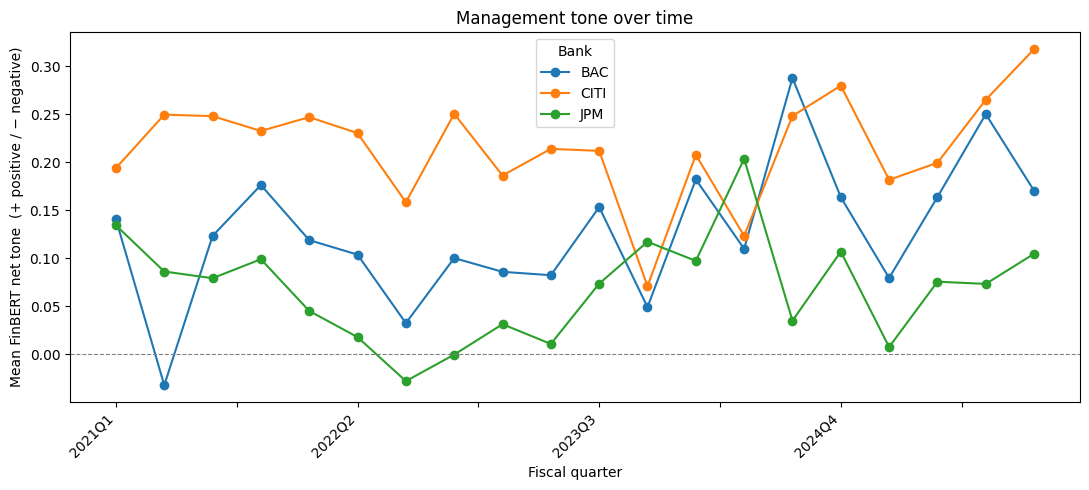

bank_id,BAC,CITI,JPM
period,,,
2021Q1,0.140,0.194,0.134
2021Q2,-0.032,0.250,0.086
2021Q3,0.123,0.248,0.079
2021Q4,0.176,0.233,0.099
2022Q1,0.119,0.247,0.045
2022Q2,0.104,0.230,0.018
2022Q3,0.032,0.158,-0.028
2022Q4,0.100,0.251,-0.001
2023Q1,0.086,0.186,0.031


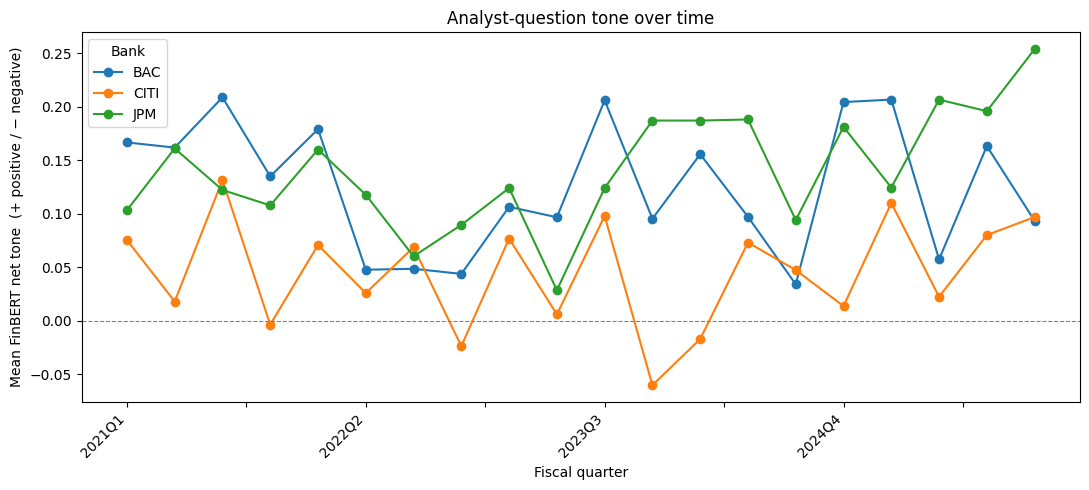

bank_id,BAC,CITI,JPM
period,,,
2021Q1,0.167,0.075,0.103
2021Q2,0.162,0.018,0.161
2021Q3,0.209,0.131,0.122
2021Q4,0.135,-0.004,0.108
2022Q1,0.179,0.071,0.160
2022Q2,0.048,0.026,0.118
2022Q3,0.049,0.069,0.060
2022Q4,0.044,-0.024,0.089
2023Q1,0.106,0.077,0.124


In [ ]:
# ordered quarter label (e.g. 2021Q1 … 2025Q4) so the x-axis sorts chronologically
qnum = scored["fiscal_quarter"].astype(str).str.extract(r"([1-4])\s*$")[0].astype(int)
scored["period_sort"] = scored["fiscal_year"].astype(int) * 4 + (qnum - 1)
scored["period"] = scored["fiscal_year"].astype(int).astype(str) + "Q" + qnum.astype(str)
order = scored.sort_values("period_sort")["period"].unique()
scored["period"] = pd.Categorical(scored["period"], categories=order, ordered=True)

def tone_trend(mask, title):
    wide = (scored[mask]
            .groupby(["period", "bank_id"], observed=True)["finbert_net"]
            .mean().unstack("bank_id").sort_index())
    ax = wide.plot(marker="o", figsize=(11, 5))
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_ylabel("Mean FinBERT net tone  (+ positive / − negative)")
    ax.set_xlabel("Fiscal quarter")
    ax.set_title(title)
    ax.legend(title="Bank")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout(); plt.show()
    display(wide.round(3))
    return wide

mgmt_trend    = tone_trend(scored["speaker_role"].eq("management"), "Management tone over time")
analyst_trend = tone_trend(scored["speaker_role"].eq("analyst"),   "Analyst-question tone over time")

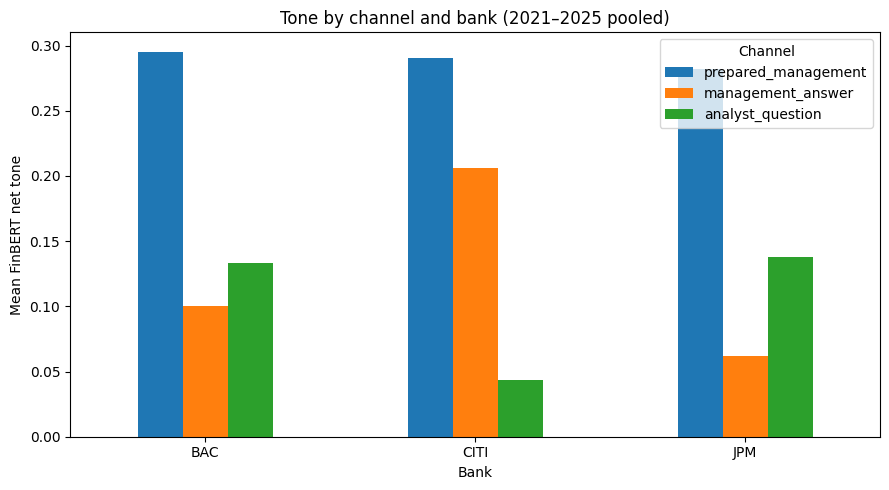

channel,prepared_management,management_answer,analyst_question
bank_id,,,
BAC,0.295,0.100,0.133
CITI,0.291,0.206,0.043
JPM,0.282,0.062,0.138


In [ ]:
# Avg tone per bank
pivot = scored.groupby(["bank_id","channel"])["finbert_net"].mean().unstack("channel")
cols  = ["prepared_management","management_answer","analyst_question"]

ax = pivot[cols].plot(kind="bar", figsize=(9,5))
ax.set_ylabel("Mean FinBERT net tone")
ax.set_xlabel("Bank")
ax.set_title("Tone by channel and bank (2021–2025 pooled)")
ax.legend(title="Channel")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

display(pivot[cols].round(3))

The values are small, as most of the call is based on facts such as revenue, which reads as slightly positive but still needs some exploration/refinement.

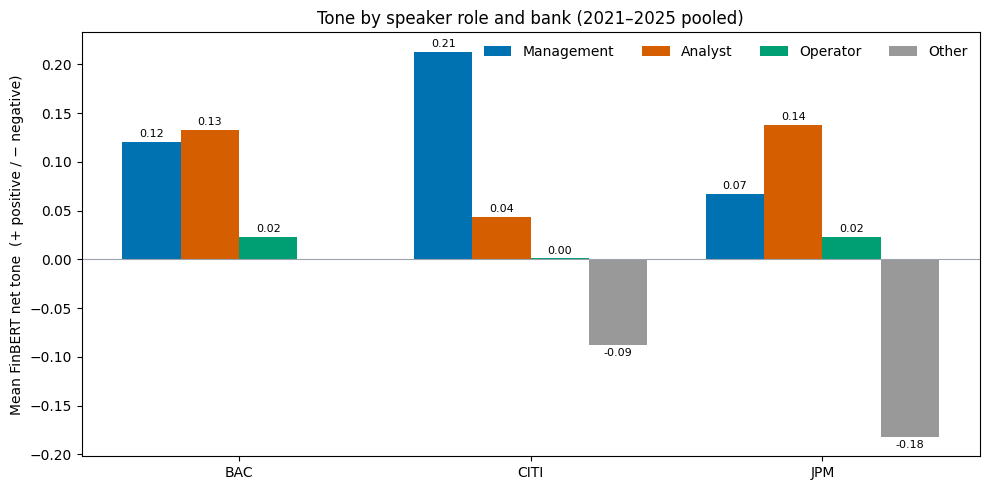

speaker_role,management,analyst,operator,other
bank_id,,,,
BAC,0.120,0.133,0.023,NaN
CITI,0.213,0.043,0.001,-0.088
JPM,0.067,0.138,0.023,-0.182


speaker_role,Management,Analyst,Operator,Other
bank_id,,,,
BAC,694,625,256,0
CITI,737,471,315,1
JPM,1129,804,290,20


In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Overall: all speaker roles by bank, pooled 2021–2025
banks  = ["BAC", "CITI", "JPM"]
roles  = ["management", "analyst", "operator", "other"]
colors = ["#0072B2", "#D55E00", "#009E73", "#999999"]

g = scored.groupby(["bank_id", "speaker_role"], observed=True)["finbert_net"]
vals   = g.mean().unstack("speaker_role").reindex(index=banks, columns=roles)
counts = g.size().unstack("speaker_role").reindex(index=banks, columns=roles).fillna(0).astype(int)

x = np.arange(len(banks)); w = 0.2
fig, ax = plt.subplots(figsize=(10, 5))
for i, (role, color) in enumerate(zip(roles, colors)):
    heights = vals[role].fillna(0)
    bars = ax.bar(x + (i - 1.5) * w, heights, w, color=color, label=role.capitalize())
    labels = ["" if np.isnan(v) else f"{v:.2f}" for v in vals[role]]
    ax.bar_label(bars, labels=labels, padding=2, fontsize=8)
ax.axhline(0, color="#9ca3af", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(banks)
ax.set_ylabel("Mean FinBERT net tone  (+ positive / − negative)")
ax.set_title("Tone by speaker role and bank (2021–2025 pooled)")
ax.legend(frameon=False, ncol=4)
plt.tight_layout(); plt.show()

display(vals.round(3))
display(counts.rename(columns=str.capitalize))

Management and analyst bars are based on several hundred turns per bank. Operator turns, which are procedural, score close to zero, as expected. "Other" turns are too few to interpret (BAC 0, CITI 1, JPM 20).

Note: FinBERT's input limit is 512 tokens per input (a fixed architectural limit). This rarely affects Q&A turns, but it impacts longer texts, such as prepared remarks, when running on the overall data; these require sentence-level scoring.

In [ ]:
import os
import re
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# CHANGED: removed the repo-root search and os.chdir (not needed: data comes from turns.csv loaded earlier)
# CHANGED: removed DATA = Path("data/processed/...") (her parquet inputs are rebuilt from turns.csv in the next cell)
OUT = Path("/content/output")  # CHANGED: was Path("scripts/output"); fixed Colab path
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "prepared": OUT / "prepared_remarks_sentiment.csv",
    "qa": OUT / "qa_turns_sentiment.csv",
}
SECTION_NAMES = {"prepared": "Prepared Remarks", "qa": "Q&A"}
COLS = ["bank", "quarter", "text", "sentiment_label", "sentiment_score"]

# FinBERT takes a while on CPU. The sentiment CSVs are not in git,
# so this has to run once after a fresh clone.
RUN_FINBERT = not all(p.exists() for p in FILES.values())
# CHANGED: removed RUN_PDF_PARSING (PDF-parsing step dropped; raw PDFs are not part of the data)

In [ ]:
def extract_bank_quarter(call_id):
    """'BAC_2022Q2_earnings_call' -> ('BAC', '2022Q2')"""
    match = re.match(r"([A-Z]+)_(\d{4}Q\d)", str(call_id))
    if match:
        return match.group(1), match.group(2)
    return None, None


def split_into_sentences(df):
    """One row per sentence, so FinBERT reads all of the text."""
    df = df.copy()
    df["text"] = df["text"].fillna("").astype(str).str.split(r"(?<=[.!?])\s+")
    df = df.explode("text")
    df["text"] = df["text"].str.strip()
    df = df[df["text"].str.len() > 20]  # drop empty bits and tiny fragments like "Thanks."
    return df.reset_index(drop=True)


def run_sentiment(df, label, sentiment_pipeline):
    df[["bank", "quarter"]] = df["call_id"].apply(lambda x: pd.Series(extract_bank_quarter(x)))
    unparsed = df["bank"].isna().sum()
    if unparsed > 0:
        print(f"WARNING: {unparsed} rows in {label} had a call_id that didn't match the expected pattern")

    texts = df["text"].fillna("").tolist()
    results = sentiment_pipeline(texts, truncation=True, max_length=512, batch_size=8)
    df["sentiment_label"] = [r["label"] for r in results]
    df["sentiment_score"] = [r["score"] for r in results]
    print(f"\n--- {label} sentiment counts ---")
    print(df["sentiment_label"].value_counts())
    return df


if RUN_FINBERT:
    from transformers import pipeline

    prepared_remarks = turns[turns["channel"] == "prepared_management"].copy()  # CHANGED: was read_parquet(prepared_management_turns); same 157 turns and text
    qa_turns = turns[turns["channel"] == "management_answer"].copy()  # CHANGED: was read_parquet(management_qa_turns); same 2,403 answers and text
    print("Prepared Remarks shape:", prepared_remarks.shape)  # CHANGED (expected output): (157, 28) instead of (157, 37) - fewer columns, same rows
    print("Q&A shape:", qa_turns.shape)  # CHANGED (expected output): (2403, 28) instead of (2403, 38)

    prepared_remarks = split_into_sentences(prepared_remarks)
    print("Prepared Remarks after splitting into sentences:", prepared_remarks.shape)

    finbert_top = pipeline("sentiment-analysis", model="ProsusAI/finbert")  # CHANGED: renamed from finbert so it does not overwrite the finbert used in the Q&A section
    prepared_remarks = run_sentiment(prepared_remarks, "Prepared Remarks", finbert_top)  # CHANGED: finbert -> finbert_top
    qa_turns = run_sentiment(qa_turns, "Q&A", finbert_top)  # CHANGED: finbert -> finbert_top

    prepared_remarks.to_csv(FILES["prepared"], index=False)
    qa_turns.to_csv(FILES["qa"], index=False)
    print(f"\nSaved both CSVs to {OUT}/")  # CHANGED: message now shows the real folder
else:
    print("Sentiment CSVs already exist, skipping FinBERT (delete them to rerun)")

Prepared Remarks shape: (157, 33)
Q&A shape: (2403, 33)
Prepared Remarks after splitting into sentences: (11288, 33)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


--- Prepared Remarks sentiment counts ---
sentiment_label
positive    5675
neutral     3836
negative    1777
Name: count, dtype: int64

--- Q&A sentiment counts ---
sentiment_label
neutral     1909
positive     326
negative     168
Name: count, dtype: int64

Saved both CSVs to /content/output/


In [ ]:
# NOTE: prints short text snippets - clear this output before sharing the notebook
lines = ["ENCODING CHECK: non-standard characters in the text", ""]
for key, path in FILES.items():
    df = pd.read_csv(path, usecols=["bank", "quarter", "text"])
    counter = Counter()
    examples = {}
    for text in df["text"].fillna("").astype(str):
        for i, ch in enumerate(text):
            if ord(ch) > 127:  # anything beyond plain English letters, numbers and punctuation
                counter[ch] += 1
                if ch not in examples:
                    examples[ch] = text[max(0, i - 40): i + 40].replace("\n", " ")
    lines.append(f"=== {SECTION_NAMES[key]}: {len(df)} rows, {sum(counter.values())} unusual characters ===")
    for ch, n in counter.most_common(25):
        lines.append(f"  {ch!r:<6} (U+{ord(ch):04X})  x{n:<6} ...{examples[ch]}...")
    lines.append("")

report = "\n".join(lines)
print(report)
(OUT / "encoding_check.txt").write_text(report, encoding="utf-8")
print(f"Saved to {OUT}/encoding_check.txt")  # CHANGED: message now shows the real folder

ENCODING CHECK: non-standard characters in the text

=== Prepared Remarks: 11288 rows, 347 unusual characters ===
  '’'    (U+2019)  x261    ...I’m sure, by now, you've all had a chance...
  '–'    (U+2013)  x50     ...We experienced strong household – new household acquisition in a virtual...
  '‘'    (U+2018)  x26     ...And by contrast, last year, in ‘21, we released $6.8 billion of reserve...
  '“'    (U+201C)  x4      ...ngs including, without limitati on, the “Risk Factors” section of our 2020 Form ...
  '”'    (U+201D)  x4      ..., without limitati on, the “Risk Factors” section of our 2020 Form 10-K....
  '—'    (U+2014)  x2      ...Fixed Income however was down 6% — our Rates and Currencies business didn...

=== Q&A: 2403 rows, 1708 unusual characters ===
  '’'    (U+2019)  x997    ...s, literally, when you look in customers’ earnings power and things like that. B...
  '–'    (U+2013)  x669    ...s, digital increases. So we are sort of – as talked about in other calls, we've 

In [ ]:
# Boilerplate filter
BOILERPLATE_PATTERN = (
    r"forward[- ]looking statements|disclaimer|does not constitute an offer|safe harbor|"
    r"thank you(?: all| everyone)? for joining|this concludes|you may now disconnect|"
    r"have a (?:great|good) (?:day|evening|weekend)|contact (?:ir|investor relations)|"
    r"presentation is available|available on our website"
)
MAX_WORDS = 40  # longer turns usually contain real content, so they are kept


def remove_boilerplate(df, label=""):
    """Removes short rows that are only welcomes, closings or legal disclaimers."""
    text = df["text"].fillna("").astype(str)
    matches = text.str.lower().str.contains(BOILERPLATE_PATTERN, regex=True)
    short = text.str.split().str.len() <= MAX_WORDS
    is_boilerplate = matches & short
    print(f"{label}: removed {is_boilerplate.sum()} short boilerplate rows out of {len(df)}")
    return df[~is_boilerplate].copy()

In [ ]:
# 4. Negative sentiment trend by bank and quarter
CONFIDENCE_THRESHOLD = 0.7

prepared = remove_boilerplate(pd.read_csv(FILES["prepared"]), "Prepared Remarks")
qa_answers = remove_boilerplate(pd.read_csv(FILES["qa"]), "Q&A")  # CHANGED: renamed from qa so it does not overwrite qa in the Q&A section


def sentiment_trend(df, label):
    """% of rows per bank/quarter that FinBERT labels negative with score >= threshold."""
    df = df.copy()
    df["is_negative"] = df["sentiment_label"] == "negative"
    df["is_confident_negative"] = df["is_negative"] & (df["sentiment_score"] >= CONFIDENCE_THRESHOLD)

    grouped = df.groupby(["bank", "quarter"]).agg(
        n_turns=("sentiment_label", "size"),
        n_negative=("is_negative", "sum"),
        n_confident_negative=("is_confident_negative", "sum"),
    ).reset_index()

    grouped["pct_negative_raw"] = grouped["n_negative"] / grouped["n_turns"] * 100
    grouped["pct_negative"] = grouped["n_confident_negative"] / grouped["n_turns"] * 100

    grouped = grouped.sort_values(["bank", "quarter"])
    print(f"\n--- {label}: % Negative Sentiment by Bank/Quarter (confidence >= {CONFIDENCE_THRESHOLD}) ---")
    print(grouped.to_string(index=False))
    return grouped


prepared_trend = sentiment_trend(prepared, "Prepared Remarks")
qa_trend = sentiment_trend(qa_answers, "Q&A")  # CHANGED: qa -> qa_answers

prepared_trend.to_csv(OUT / "prepared_remarks_trend.csv", index=False)
qa_trend.to_csv(OUT / "qa_turns_trend.csv", index=False)
print(f"\nSaved trend summaries to {OUT}/")  # CHANGED: message now shows the real folder

Prepared Remarks: removed 125 short boilerplate rows out of 11288
Q&A: removed 11 short boilerplate rows out of 2403

--- Prepared Remarks: % Negative Sentiment by Bank/Quarter (confidence >= 0.7) ---
bank quarter  n_turns  n_negative  n_confident_negative  pct_negative_raw  pct_negative
 BAC  2021Q1      178          42                    35         23.595506     19.662921
 BAC  2021Q2      283          64                    57         22.614841     20.141343
 BAC  2021Q3      261          29                    29         11.111111     11.111111
 BAC  2021Q4      285          30                    26         10.526316      9.122807
 BAC  2022Q1      320          54                    43         16.875000     13.437500
 BAC  2022Q2      292          47                    40         16.095890     13.698630
 BAC  2022Q3      295          58                    47         19.661017     15.932203
 BAC  2022Q4      307          44                    35         14.332248     11.400651
 BAC  2

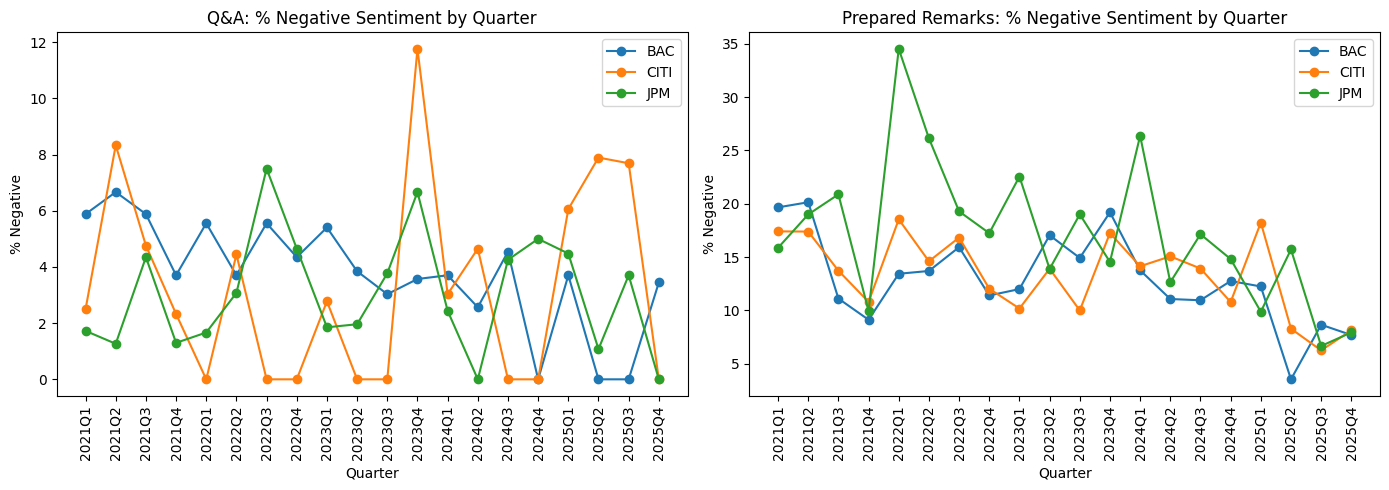

In [ ]:
# Trend chart
panels = [("Q&A", qa_trend), ("Prepared Remarks", prepared_trend)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (title, trend) in zip(axes, panels):
    for bank in trend["bank"].unique():
        bank_data = trend[trend["bank"] == bank]
        ax.plot(bank_data["quarter"], bank_data["pct_negative"], marker="o", label=bank)
    ax.set_title(f"{title}: % Negative Sentiment by Quarter")
    ax.set_xlabel("Quarter")
    ax.set_ylabel("% Negative")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()

plt.tight_layout()
plt.savefig(OUT / "sentiment_trend_chart.png", dpi=150)
plt.show()

In [ ]:
# Threshold sensitivity
THRESHOLDS = [0.0, 0.6, 0.7, 0.8, 0.9]  # 0.0 = no threshold (raw labels)
cols = ["bank", "quarter", "sentiment_label", "sentiment_score"]

results = []
for key, path in FILES.items():
    section = SECTION_NAMES[key]
    df = pd.read_csv(path, usecols=cols)
    df["is_neg"] = df["sentiment_label"] == "negative"
    for t in THRESHOLDS:
        df["hit"] = df["is_neg"] & (df["sentiment_score"] >= t)
        g = df.groupby(["bank", "quarter"]).agg(n_rows=("hit", "size"), n_negative=("hit", "sum")).reset_index()
        g["pct_negative"] = g["n_negative"] / g["n_rows"] * 100
        g["threshold"] = t
        g["section"] = section
        results.append(g)

res = pd.concat(results, ignore_index=True)
res.to_csv(OUT / "threshold_sensitivity.csv", index=False)

lines = ["THRESHOLD SENSITIVITY CHECK", ""]
for section in SECTION_NAMES.values():
    s = res[res["section"] == section].pivot_table(
        index=["bank", "quarter"], columns="threshold", values="pct_negative")
    lines.append(f"=== {section} ===")
    lines.append("Correlation of each threshold with the 0.7 results (1.0 = identical pattern):")
    lines.append(s.corr()[0.7].round(3).to_string())
    lines.append("")
    lines.append("Top 5 bank-quarters at each threshold:")
    for t in THRESHOLDS:
        top = s[t].sort_values(ascending=False).head(5)
        name = "none" if t == 0 else f">= {t}"
        lines.append(f"  {name:>6}: " + ", ".join(f"{b} {q} ({v:.1f}%)" for (b, q), v in top.items()))
    lines.append("")

report = "\n".join(lines)
print(report)
(OUT / "threshold_sensitivity.txt").write_text(report, encoding="utf-8")

THRESHOLD SENSITIVITY CHECK

=== Prepared Remarks ===
Correlation of each threshold with the 0.7 results (1.0 = identical pattern):
threshold
0.0    0.979
0.6    0.991
0.7    1.000
0.8    0.982
0.9    0.951

Top 5 bank-quarters at each threshold:
    none: JPM 2022Q1 (35.3%), JPM 2022Q2 (29.2%), JPM 2024Q1 (27.2%), JPM 2023Q1 (23.3%), BAC 2021Q1 (23.2%)
  >= 0.6: JPM 2022Q1 (35.3%), JPM 2022Q2 (28.1%), JPM 2024Q1 (26.1%), JPM 2023Q1 (22.3%), BAC 2021Q2 (21.7%)
  >= 0.7: JPM 2022Q1 (34.1%), JPM 2024Q1 (26.1%), JPM 2022Q2 (25.8%), JPM 2023Q1 (22.3%), JPM 2021Q3 (20.7%)
  >= 0.8: JPM 2022Q1 (31.8%), JPM 2024Q1 (23.9%), JPM 2022Q2 (23.6%), JPM 2023Q1 (22.3%), BAC 2021Q2 (18.2%)
  >= 0.9: JPM 2022Q1 (29.4%), JPM 2022Q2 (23.6%), JPM 2023Q1 (19.4%), JPM 2024Q1 (18.5%), JPM 2022Q3 (17.0%)

=== Q&A ===
Correlation of each threshold with the 0.7 results (1.0 = identical pattern):
threshold
0.0    0.656
0.6    0.807
0.7    1.000
0.8    0.718
0.9    0.526

Top 5 bank-quarters at each threshold:
  

1542

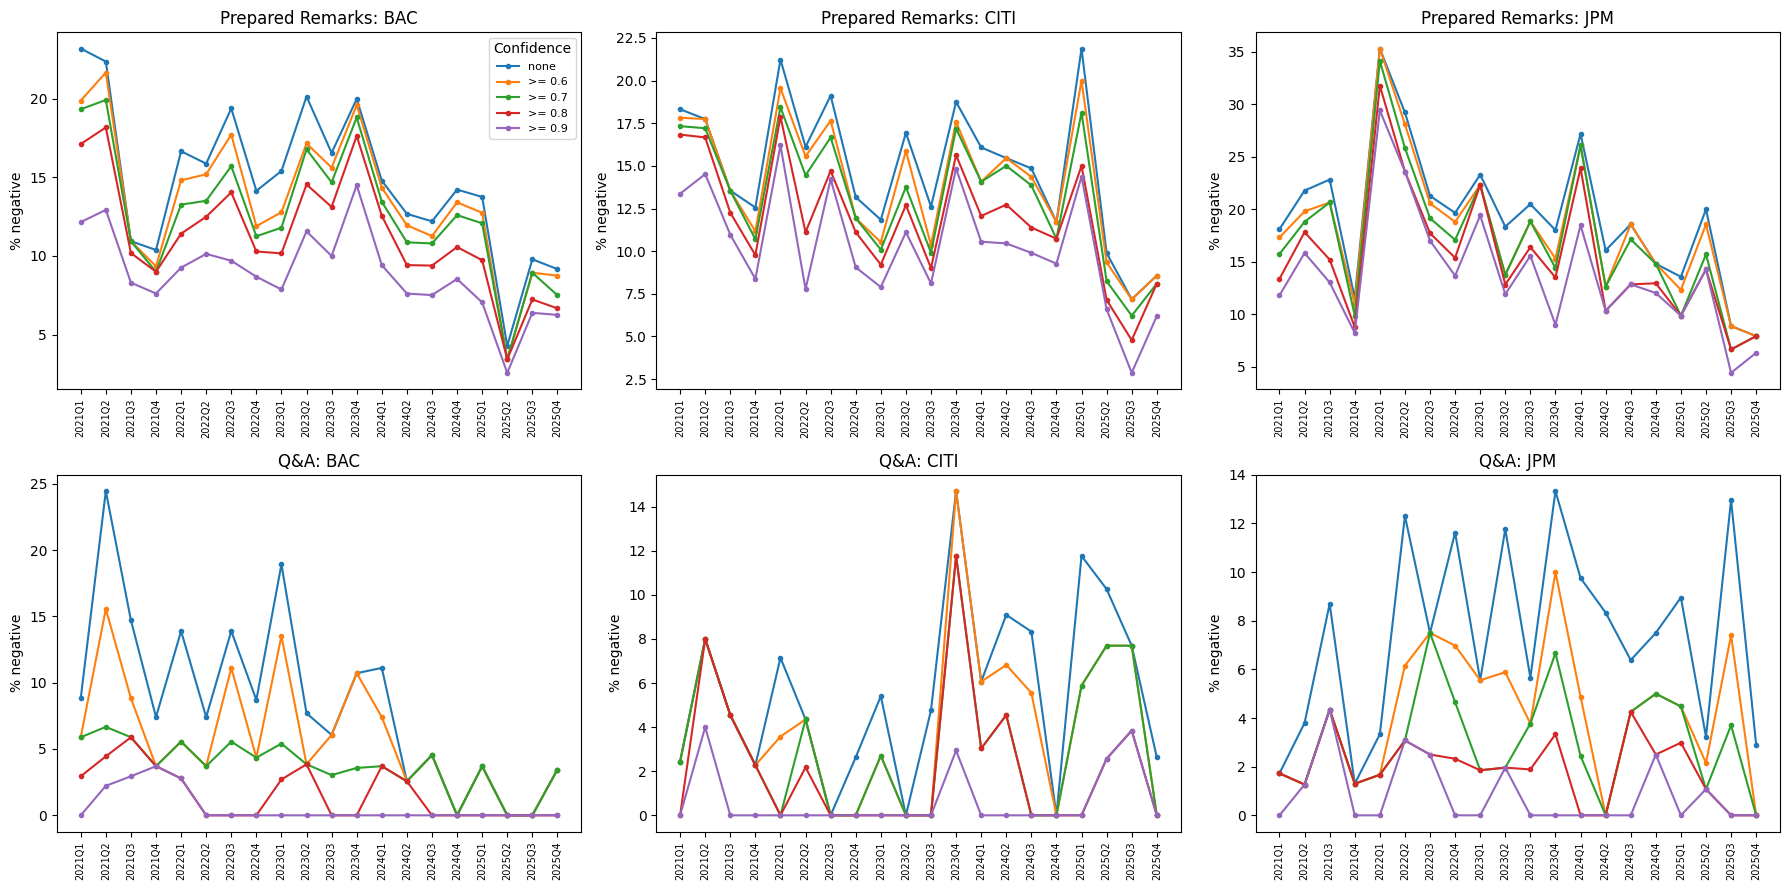

In [ ]:
# Threshold chart, unchanged
banks = sorted(res["bank"].unique())
sections = list(SECTION_NAMES.values())
fig, axes = plt.subplots(len(sections), len(banks), figsize=(6 * len(banks), 9), squeeze=False)
for i, section in enumerate(sections):
    for j, bank in enumerate(banks):
        ax = axes[i][j]
        d = res[(res["section"] == section) & (res["bank"] == bank)]
        for t in THRESHOLDS:
            dt = d[d["threshold"] == t].sort_values("quarter")
            ax.plot(dt["quarter"], dt["pct_negative"], marker="o", markersize=3,
                    label="none" if t == 0 else f">= {t}")
        ax.set_title(f"{section}: {bank}")
        ax.set_ylabel("% negative")
        ax.tick_params(axis="x", rotation=90, labelsize=7)
axes[0][0].legend(title="Confidence", fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "threshold_sensitivity_chart.png", dpi=120)
plt.show()

## 3.2 FinBERT on the Q&A

In [ ]:
# questions vs answers by bank
qa = scored[scored["channel"].isin(["analyst_question", "management_answer"])].copy()
qa["period"] = qa["fiscal_year"].astype(str) + "Q" + qa["fiscal_quarter"].astype(str)
print(qa["channel"].value_counts())

overview = (qa.groupby(["bank_id", "channel"])
              .agg(mean_net=("finbert_net", "mean"),
                   n=("finbert_net", "size"),
                   sd=("finbert_net", "std"),
                   pct_pos=("finbert_label", lambda s: (s == "positive").mean() * 100),
                   pct_neg=("finbert_label", lambda s: (s == "negative").mean() * 100))
              .round(3))
display(overview)

channel
management_answer    2403
analyst_question     1900
Name: count, dtype: int64


mean_net     n     sd  pct_pos  pct_neg
bank_id channel                                                   
BAC     analyst_question      0.133   625  0.286   12.160    5.600
        management_answer     0.100   623  0.324   12.681    8.989
CITI    analyst_question      0.043   471  0.264    4.246    6.369
        management_answer     0.206   677  0.332   20.975    5.613
JPM     analyst_question      0.138   804  0.302   12.438    5.224
        management_answer     0.062  1103  0.274    9.519    6.709

In [ ]:
print("Q&A rows scored:", len(qa))
print("any missing net scores:", qa["finbert_net"].isna().sum())
print("\nlabel distribution:")
print(qa["finbert_label"].value_counts())
print(qa["finbert_label"].value_counts(normalize=True).mul(100).round(1))   # as %
print("\nnet sentiment range:", round(qa["finbert_net"].min(), 3), "to", round(qa["finbert_net"].max(), 3))

Q&A rows scored: 4303
any missing net scores: 0

label distribution:
finbert_label
neutral     3506
positive     522
negative     275
Name: count, dtype: int64
finbert_label
neutral     81.5
positive    12.1
negative     6.4
Name: proportion, dtype: float64

net sentiment range: -0.944 to 0.941


1900 questions and 2403 answers from managers.

Citi Q&A had a bigger contrast amongst the banks, indicating that only 4% of analyst questions were positive, while 21% of management answers were positive, the highest share of the three banks.

In [ ]:
# questions and answers gap
per_call = (qa.groupby(["bank_id", "period", "channel"])["finbert_net"]
              .agg(["mean", "size"]).unstack("channel"))
gap = pd.DataFrame({
    "q_tone": per_call[("mean", "analyst_question")],
    "a_tone": per_call[("mean", "management_answer")],
    "n_q":    per_call[("size", "analyst_question")],
    "n_a":    per_call[("size", "management_answer")],
}).reset_index()
gap["qa_gap"] = gap["a_tone"] - gap["q_tone"]

assert len(gap) == 60, len(gap)
print("Calls missing a side:", gap[["q_tone", "a_tone"]].isna().any(axis=1).sum())
display(gap.groupby("bank_id")[["q_tone", "a_tone", "qa_gap"]].agg(["mean", "std", "min", "max"]).round(3))

Calls missing a side: 0


q_tone                      a_tone                      qa_gap         \
          mean    std    min    max   mean    std    min    max   mean    std   
bank_id                                                                         
BAC      0.125  0.061  0.034  0.209  0.106  0.070 -0.034  0.266 -0.019  0.096   
CITI     0.045  0.051 -0.060  0.131  0.208  0.054  0.074  0.302  0.163  0.070   
JPM      0.141  0.055  0.029  0.254  0.062  0.053 -0.029  0.184 -0.079  0.047   

                       
           min    max  
bank_id                
BAC     -0.196  0.232  
CITI     0.044  0.279  
JPM     -0.160  0.031

Amongst the banks, Citi managers answered more positively than they were questioned in all quarters analysed. JPMs are the most consistent and reserved, while BAC is average, near zero but swinging widely between quarters (-0.20 to +0.23).

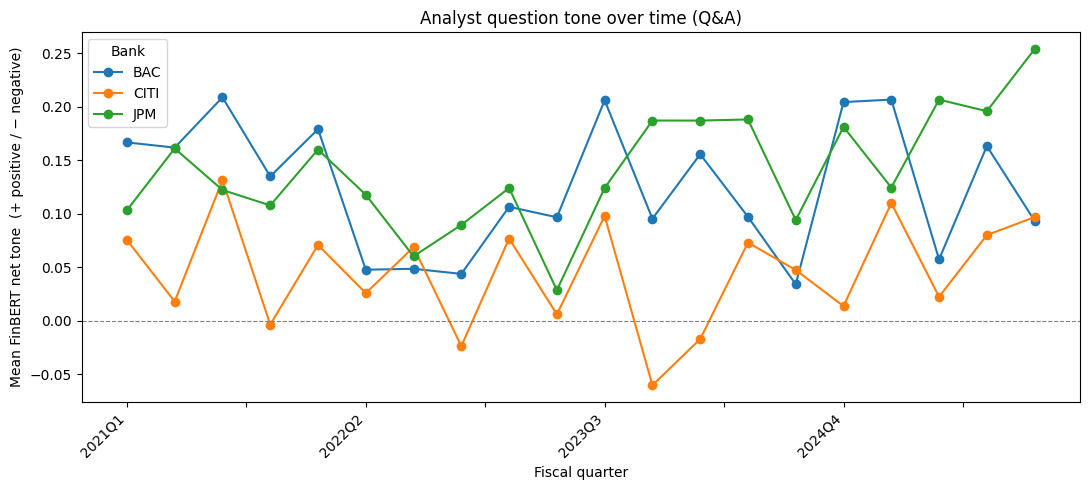

bank_id,BAC,CITI,JPM
period,,,
2021Q1,0.167,0.075,0.103
2021Q2,0.162,0.018,0.161
2021Q3,0.209,0.131,0.122
2021Q4,0.135,-0.004,0.108
2022Q1,0.179,0.071,0.160
2022Q2,0.048,0.026,0.118
2022Q3,0.049,0.069,0.060
2022Q4,0.044,-0.024,0.089
2023Q1,0.106,0.077,0.124


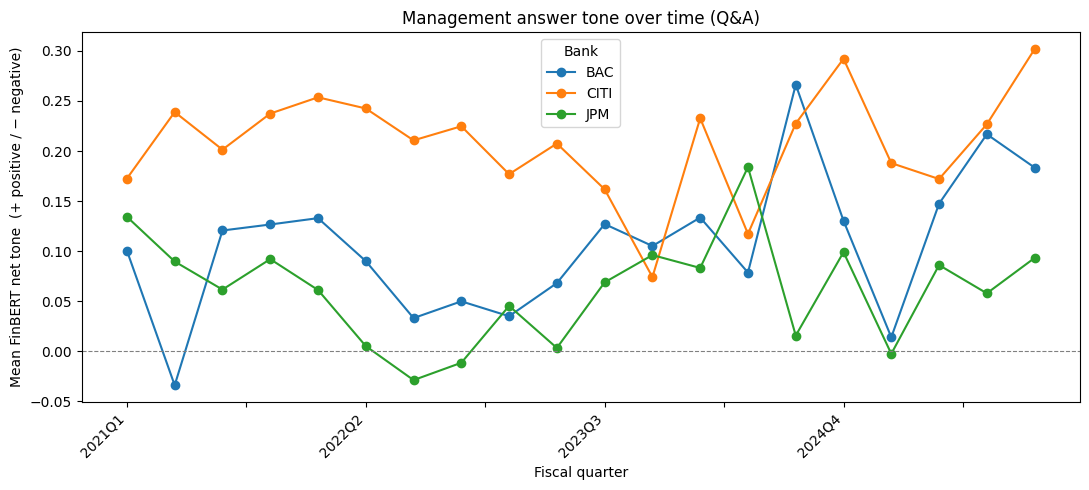

bank_id,BAC,CITI,JPM
period,,,
2021Q1,0.101,0.173,0.134
2021Q2,-0.034,0.239,0.090
2021Q3,0.121,0.201,0.062
2021Q4,0.127,0.237,0.092
2022Q1,0.133,0.254,0.061
2022Q2,0.090,0.243,0.005
2022Q3,0.033,0.211,-0.029
2022Q4,0.050,0.225,-0.011
2023Q1,0.035,0.177,0.045


In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

def tone_trend(mask, title):
    wide = (scored[mask]
            .groupby(["period", "bank_id"], observed=True)["finbert_net"]
            .mean().unstack("bank_id").sort_index())
    ax = wide.plot(marker="o", figsize=(11, 5))
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_ylabel("Mean FinBERT net tone  (+ positive / − negative)")
    ax.set_xlabel("Fiscal quarter")
    ax.set_title(title)
    ax.legend(title="Bank")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout(); plt.show()
    display(wide.round(3))
    return wide

analyst_trend = tone_trend(scored["channel"].eq("analyst_question"),  "Analyst question tone over time (Q&A)")
mgmt_trend    = tone_trend(scored["channel"].eq("management_answer"), "Management answer tone over time (Q&A)")

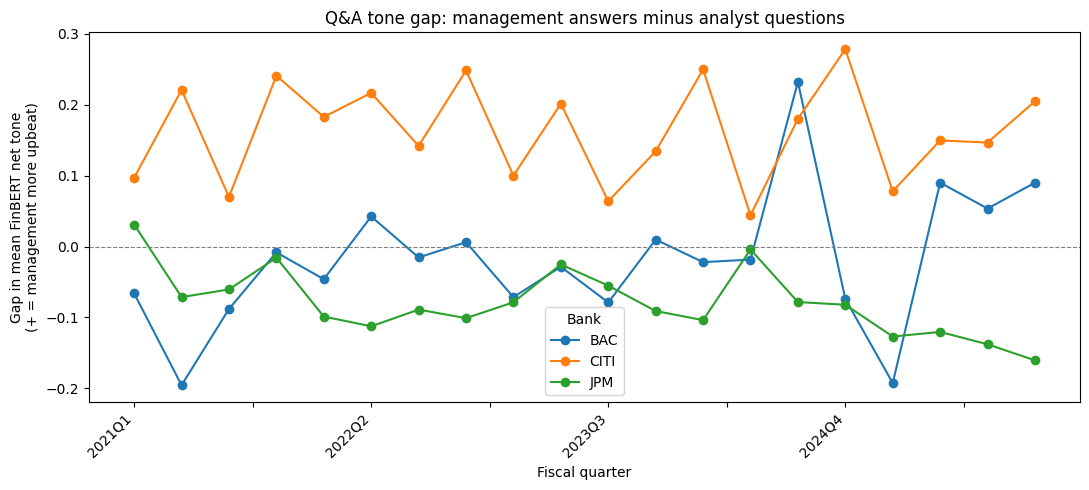

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

# Q&A gap over time
wide = gap.pivot(index="period", columns="bank_id", values="qa_gap").sort_index()
ax = wide.plot(marker="o", figsize=(11, 5))
ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.set_title("Q&A tone gap: management answers minus analyst questions")
ax.set_ylabel("Gap in mean FinBERT net tone\n(+ = management more upbeat)")
ax.set_xlabel("Fiscal quarter"); ax.legend(title="Bank")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

In [ ]:
# Who asks and who answers? Roles vs channels and sections
display(pd.crosstab(turns["speaker_role"], turns["channel"], margins=True))
display(pd.crosstab(turns["speaker_role"], turns["section"], margins=True))

# What are the "other" turns?
other = turns[turns["speaker_role"] == "other"]
other_summary = (other.assign(bank_id=other["call_id"].str.split("_").str[0],
                              words=other["verbatim_text"].str.split().str.len())
                      .groupby("bank_id")
                      .agg(turns=("turn_id", "size"),
                           min_words=("words", "min"),
                           max_words=("words", "max")))
display(other_summary)

# How the parser classified them (speakers.csv; no join, filter by ID)
print(speakers.loc[speakers["speaker_id"].isin(other["speaker_id"]), "classification_evidence"].value_counts())

channel,analyst_question,management_answer,other,prepared_management,All
speaker_role,,,,,
analyst,1900,0,0,0,1900
management,0,2403,0,157,2560
operator,0,0,861,0,861
other,0,0,21,0,21
All,1900,2403,882,157,5342


section,other,prepared_remarks,qa,All
speaker_role,,,,
analyst,0,0,1900,1900
management,0,157,2403,2560
operator,0,66,795,861
other,21,0,0,21
All,21,223,5098,5342


,turns,min_words,max_words
bank_id,,,
CITI,1,297,297
JPM,20,135,135


classification_evidence
source-structured terminal document appendix from positive document/layout evidence    21
Name: count, dtype: int64


Explore more about the speaker's role “other” if they can still represent a risk despite the tone.

In [ ]:
# Explore output about the speaker role other
text = turns.set_index("turn_id")["verbatim_text"]
qa_text = qa.assign(text=qa["turn_id"].map(text))

# 1) Read a few examples per label and channel
for channel in ["analyst_question", "management_answer"]:
    for label in ["positive", "neutral", "negative"]:
        ex = qa_text[(qa_text["channel"] == channel) & (qa_text["finbert_label"] == label)].sample(3, random_state=1)
        print(f"\n===== {channel} | {label} =====")
        for _, r in ex.iterrows():
            print(f"[{r['bank_id']} {r['period']} | net {r['finbert_net']:.2f}] {r['text'][:400]}\n")

# 2) How often do risk-related words appear under each label?
risk_words = r"\b(?:risk|credit|charge-?offs?|provision|reserve|loss(?:es)?|default|deposit|liquidity|capital|delinquen\w*|commercial real estate|CRE|recession|stress)\b"
qa_text["mentions_risk"] = qa_text["text"].str.contains(risk_words, case=False, regex=True)
display(pd.crosstab([qa_text["channel"], qa_text["finbert_label"]], qa_text["mentions_risk"],
                    normalize="index").mul(100).round(1).rename(columns={True: "% mentioning risk words", False: "% not"}))


===== analyst_question | positive =====
[JPM 2023Q1 | net 0.57] That's great. I'll hop back into the queue. Thanks so much for taking my questions.

[BAC 2021Q2 | net 0.58] Fair enough. Thanks for accommodating the additional question.

[JPM 2021Q4 | net 0.77] Thanks so much, Jeremy.


===== analyst_question | neutral =====
[BAC 2021Q3 | net 0.15] Thank you.

[CITI 2023Q1 | net 0.15] Hey, good morning. Maybe just a question on capital. Appreciate the fact that the potential
sale of the Mexico franchise would be a negative impact, b ut you're sitting at a pretty comfortable cushion
now above your target. Obviously your expected future retained earnings growth should be more than an
offset, so how do we think about, how are you thinking about the timing of restarting buybacks wi

[CITI 2024Q4 | net 0.05] Well, I appreciate the insights. And then as a follow-up question, and I really don't mean
this as a ‘what have you done for me lately?’ type of question because you guys have made so m

mentions_risk                    % not  % mentioning risk words
channel           finbert_label                                
analyst_question  negative        62.6                     37.4
                  neutral         67.8                     32.2
                  positive        87.2                     12.8
management_answer negative        60.1                     39.9
                  neutral         64.1                     35.9
                  positive        62.3                     37.7

In the Sample above, we can see labels for positive questions that are actually courtesy items. The negative ones are real risk questions, like 30% down (Citi 2021Q1) and delinquencies (JPM 2022Q1). FinBert classified those negative ones very well.

In [ ]:
# PRIVATE EXPLORATION – clear output before saving/sharing
other = turns[turns["speaker_role"] == "other"].copy()
other["bank_id"] = other["call_id"].str.split("_").str[0]

# Is the JPM text identical every quarter?
print("Distinct texts among JPM 'other' turns:", other.loc[other["bank_id"] == "JPM", "verbatim_text"].nunique())

# Read one JPM example and the single CITI one
print("\n===== JPM example =====")
print(other.loc[other["bank_id"] == "JPM", "verbatim_text"].iloc[0])
print("\n===== CITI (2024Q1) =====")
print(other.loc[other["bank_id"] == "CITI", "verbatim_text"].iloc[0])

Distinct texts among JPM 'other' turns: 6

===== JPM example =====
Disclaimer
This document contains forward-looking statements within the meaning of the Private Securities Litigation Reform Act of 1995. These
statements are based on the current beliefs and expectations of JPMorgan Chase & Co.’s management and are subject to significant risks
and uncertainties. Actual results may differ from those set forth in the forward-looking statements. Factors that could cause JPMorgan Chase
& Co.’s actual results to differ materially from those described in the forward-looking statements can be found in JPMorgan Chase & Co.’s
Annual Report on Form 10-K for the year ended December 31, 2020, which has been filed with the Securities and Exchange Commission and
is available on JPMorgan Chase & Co.’s website (https://jpmorganchaseco.gcs-web.com/financial-information/sec-filings), and on the
Securities and Exchange Commission’s website (www.sec.gov). JPMorgan Chase & Co. does not undertake to update a

The 21 "other" turns are forward-looking-statement disclaimers appended to the transcripts (20 from JPM and 1 from Citi). JPM's follow a standard template that changes only slightly over time; Citi's 2024Q1 version lists quarter-specific risk factors but is partly garbled by PDF extraction. All are excluded from sentiment analysis.



Once there are some cortesis classified as "positive", the analyst decided to exclude courtesy turns.

Short analyst turns such as "Thanks so much" score strongly positive without containing a question. To check that the Q&A gap is not driven by politeness, we recompute it excluding turns under 15 words that contain a thank-you phrase. The original data and scores are not changed; the check runs on a copy.

In [ ]:
# Robustness check: exclude courtesy turns short AND thank you phrase
words = turns.set_index("turn_id")["verbatim_text"].str.split().str.len()
text  = turns.set_index("turn_id")["verbatim_text"]

courtesy_phrases = r"\b(?:thank|thanks|appreciate|back (?:in|into) the queue|congrat\w*|great quarter|nice quarter)\b"
qa_check = qa.assign(n_words=qa["turn_id"].map(words),
                     courtesy=qa["turn_id"].map(text).str.contains(courtesy_phrases, case=False, regex=True))
qa_check["is_courtesy"] = qa_check["courtesy"] & (qa_check["n_words"] < 15)

# How many turns are removed, per bank and side
display(qa_check.groupby(["bank_id", "channel"])["is_courtesy"].agg(removed="sum", share=lambda s: round(s.mean() * 100, 1)))

# Recompute the per-call gap without courtesies
def per_call_gap(df):
    m = df.groupby(["bank_id", "period", "channel"])["finbert_net"].mean().unstack("channel")
    return (m["management_answer"] - m["analyst_question"]).rename("qa_gap").reset_index()

compare = pd.DataFrame({
    "gap_all_turns":     per_call_gap(qa_check).groupby("bank_id")["qa_gap"].mean(),
    "gap_no_courtesies": per_call_gap(qa_check[~qa_check["is_courtesy"]]).groupby("bank_id")["qa_gap"].mean(),
})
compare["change"] = compare["gap_no_courtesies"] - compare["gap_all_turns"]
display(compare.round(3))

removed  share
bank_id channel                          
BAC     analyst_question       133   21.3
        management_answer        7    1.1
CITI    analyst_question        24    5.1
        management_answer       14    2.1
JPM     analyst_question       222   27.6
        management_answer      100    9.1

,gap_all_turns,gap_no_courtesies,change
bank_id,,,
BAC,-0.019,0.043,0.062
CITI,0.163,0.176,0.013
JPM,-0.079,-0.014,0.065


In [ ]:
# Comparison between remove cortesis vs non-removed
removed = (qa_check.groupby(["bank_id", "channel"])["is_courtesy"]
                   .agg(["sum", "mean"]).unstack("channel"))

side_by_side = pd.DataFrame({
    "analyst turns removed":    removed[("sum", "analyst_question")].astype(int),
    "analyst % removed":        (removed[("mean", "analyst_question")] * 100).round(1),
    "management turns removed": removed[("sum", "management_answer")].astype(int),
    "management % removed":     (removed[("mean", "management_answer")] * 100).round(1),
    "gap (all turns)":          compare["gap_all_turns"].round(3),
    "gap (no courtesies)":      compare["gap_no_courtesies"].round(3),
    "change":                   compare["change"].round(3),
})
display(side_by_side)

,analyst turns removed,analyst % removed,management turns removed,management % removed,gap (all turns),gap (no courtesies),change
bank_id,,,,,,,
BAC,133,21.3,7,1.1,-0.019,0.043,0.062
CITI,24,5.1,14,2.1,0.163,0.176,0.013
JPM,222,27.6,100,9.1,-0.079,-0.014,0.065


Removing short courtesy turns (21–28% of analyst turns at BAC and JPM, 5% at Citi) left Citi's Q&A gap essentially unchanged (+0.16 → +0.18) but moved BAC and JPM close to zero (+0.04 and −0.01). Citi's pattern is therefore robust, while the apparent caution of BAC and JPM management was largely impacted by cortesis.

In [ ]:
# Question and answer tone: all turns vs without courtesy turns
def tone_by_bank(df):
    return df.groupby(["bank_id", "channel"])["finbert_net"].mean().unstack("channel")

before = tone_by_bank(qa_check)
after  = tone_by_bank(qa_check[~qa_check["is_courtesy"]])

new_tone = pd.DataFrame({
    "questions (all)":           before["analyst_question"],
    "questions (no courtesies)": after["analyst_question"],
    "questions change":          after["analyst_question"] - before["analyst_question"],
    "answers (all)":             before["management_answer"],
    "answers (no courtesies)":   after["management_answer"],
    "answers change":            after["management_answer"] - before["management_answer"],
}).round(3)
display(new_tone)

,questions (all),questions (no courtesies),questions change,answers (all),answers (no courtesies),answers change
bank_id,,,,,,
BAC,0.133,0.061,-0.072,0.100,0.099,-0.002
CITI,0.043,0.027,-0.016,0.206,0.204,-0.002
JPM,0.138,0.040,-0.098,0.062,0.031,-0.031


By removing cortesis, the Q&A are close to neutral and similar across banks.

,% questions on risk,question tone (risk),question tone (other),% answers on risk,answer tone (risk),answer tone (other)
bank_id,,,,,,
BAC,42.480,0.031,0.083,50.162,0.116,0.082
CITI,36.018,0.059,0.009,41.176,0.233,0.184
JPM,44.330,0.017,0.057,40.179,0.016,0.042


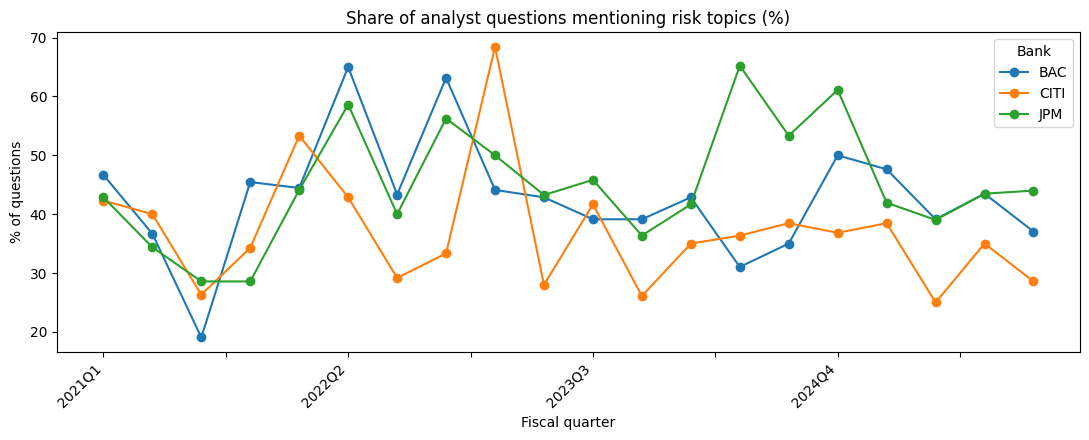

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

# Tone of risk: flag risk-topic turns (courtesies excluded; uses qa_check from the robustness cell)
text = turns.set_index("turn_id")["verbatim_text"]
risk_words = (r"\b(?:risk\w*|credit|charge-?offs?|provision\w*|reserve\w*|loss(?:es)?|default\w*|deposit\w*|"
              r"liquidity|capital|delinquen\w*|commercial real estate|CRE|recession|stress\w*)\b")
qa_risk = qa_check[~qa_check["is_courtesy"]].copy()
qa_risk["risk_topic"] = qa_risk["turn_id"].map(text).str.contains(risk_words, case=False, regex=True)

# Share of turns on risk topics, and tone on risk vs other topics
def mean_tone(ch, risk):
    s = qa_risk[(qa_risk["channel"] == ch) & (qa_risk["risk_topic"] == risk)]
    return s.groupby("bank_id")["finbert_net"].mean()

risk_summary = pd.DataFrame({
    "% questions on risk":         qa_risk[qa_risk["channel"] == "analyst_question"].groupby("bank_id")["risk_topic"].mean() * 100,
    "question tone (risk)":        mean_tone("analyst_question", True),
    "question tone (other)":       mean_tone("analyst_question", False),
    "% answers on risk":           qa_risk[qa_risk["channel"] == "management_answer"].groupby("bank_id")["risk_topic"].mean() * 100,
    "answer tone (risk)":          mean_tone("management_answer", True),
    "answer tone (other)":         mean_tone("management_answer", False),
}).round(3)
display(risk_summary)

# Over time: share of analyst questions on risk topics (analyst attention to risk)
att = (qa_risk[qa_risk["channel"] == "analyst_question"]
       .groupby(["period", "bank_id"])["risk_topic"].mean().mul(100)
       .unstack("bank_id").sort_index())
ax = att.plot(marker="o", figsize=(11, 4.5))
ax.set_title("Share of analyst questions mentioning risk topics (%)")
ax.set_ylabel("% of questions"); ax.set_xlabel("Fiscal quarter"); ax.legend(title="Bank")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

On risk-related topics, all three banks reached significant levels; FinBERT considers keywords but not context, so any topic discussed can be a risk or not, depending on the circumstances. Neither identifies risk directly, so topic modelling and human review may be needed.

In [ ]:
# Flag unusual indicators per bank and quarter (courtesy turns excluded; uses qa_risk from the previous cell)
q = qa_risk[qa_risk["channel"] == "analyst_question"]
a = qa_risk[qa_risk["channel"] == "management_answer"]
keys = ["bank_id", "period"]

indicators = pd.DataFrame({
    "qa_gap":                a.groupby(keys)["finbert_net"].mean() - q.groupby(keys)["finbert_net"].mean(),
    "% negative questions":  q.groupby(keys)["finbert_label"].apply(lambda s: (s == "negative").mean() * 100),
    "% risk-vocab questions": q.groupby(keys)["risk_topic"].mean() * 100,
}).reset_index()

# Compare each quarter with the bank's own average (z score)
long = indicators.melt(id_vars=keys, var_name="indicator", value_name="value")
grp = long.groupby(["bank_id", "indicator"])["value"]
long["bank_average"] = grp.transform("mean")
long["z"] = (long["value"] - long["bank_average"]) / grp.transform("std")

flags = long[long["z"].abs() >= 1.5].sort_values(["period", "bank_id"])
flags["direction"] = flags["z"].map(lambda z: "above normal" if z > 0 else "below normal")
display(flags[["period", "bank_id", "indicator", "value", "bank_average", "z", "direction"]].round(2))

# Overview which quarters have flags by bank
overview = (flags.assign(label=flags["indicator"] + " (" + flags["direction"] + ")")
                 .pivot_table(index="period", columns="bank_id", values="label",
                              aggfunc=lambda s: "; ".join(s)).fillna(""))
display(overview)

,period,bank_id,indicator,value,bank_average,z,direction
100,2021Q1,JPM,% negative questions,0.00,7.24,-1.59,below normal
1,2021Q2,BAC,qa_gap,-0.10,0.04,-1.59,below normal
122,2021Q3,BAC,% risk-vocab questions,19.05,42.76,-2.38,below normal
102,2021Q3,JPM,% negative questions,14.29,7.24,1.54,above normal
162,2021Q3,JPM,% risk-vocab questions,28.57,44.93,-1.64,below normal
163,2021Q4,JPM,% risk-vocab questions,28.57,44.93,-1.64,below normal
144,2022Q1,CITI,% risk-vocab questions,53.33,36.97,1.61,above normal
125,2022Q2,BAC,% risk-vocab questions,65.00,42.76,2.23,above normal
127,2022Q4,BAC,% risk-vocab questions,63.16,42.76,2.05,above normal
107,2022Q4,JPM,% negative questions,15.62,7.24,1.84,above normal


bank_id,BAC,CITI,JPM
period,,,
2021Q1,,,% negative questions (below normal)
2021Q2,qa_gap (below normal),,
2021Q3,% risk-vocab questions (below normal),,% negative questions (above normal); % risk-vo...
2021Q4,,,% risk-vocab questions (below normal)
2022Q1,,% risk-vocab questions (above normal),
2022Q2,% risk-vocab questions (above normal),,
2022Q4,% risk-vocab questions (above normal),,% negative questions (above normal)
2023Q1,,% risk-vocab questions (above normal),
2023Q2,% negative questions (above normal),,


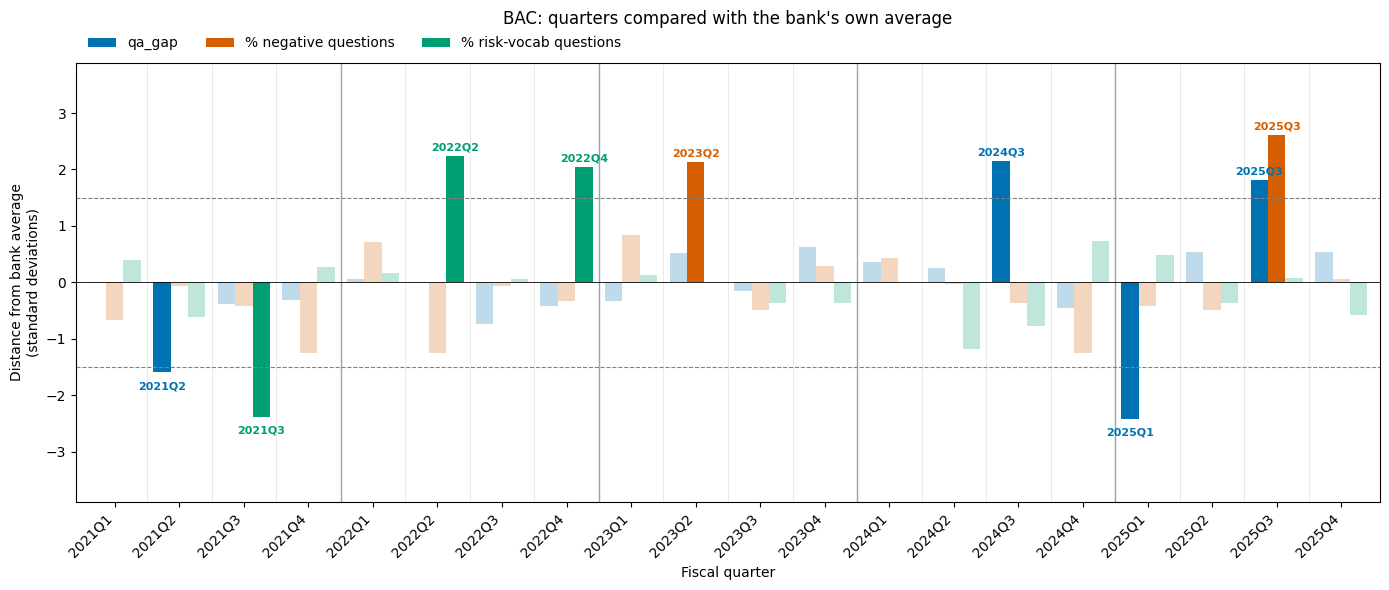

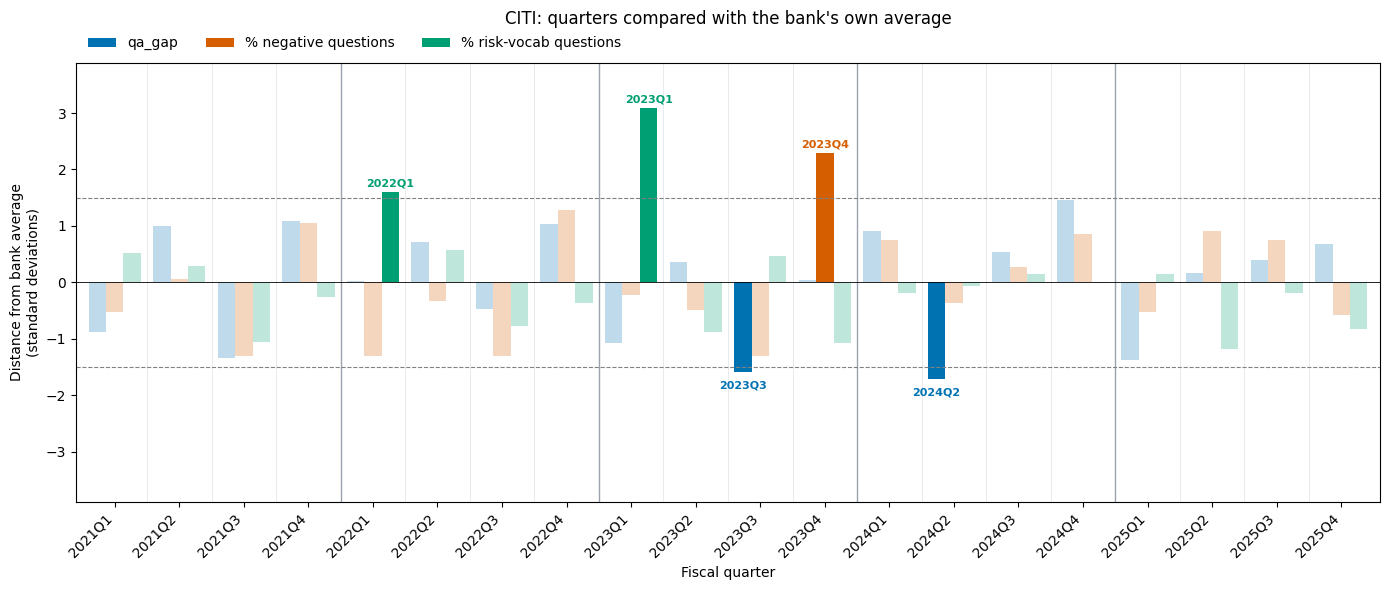

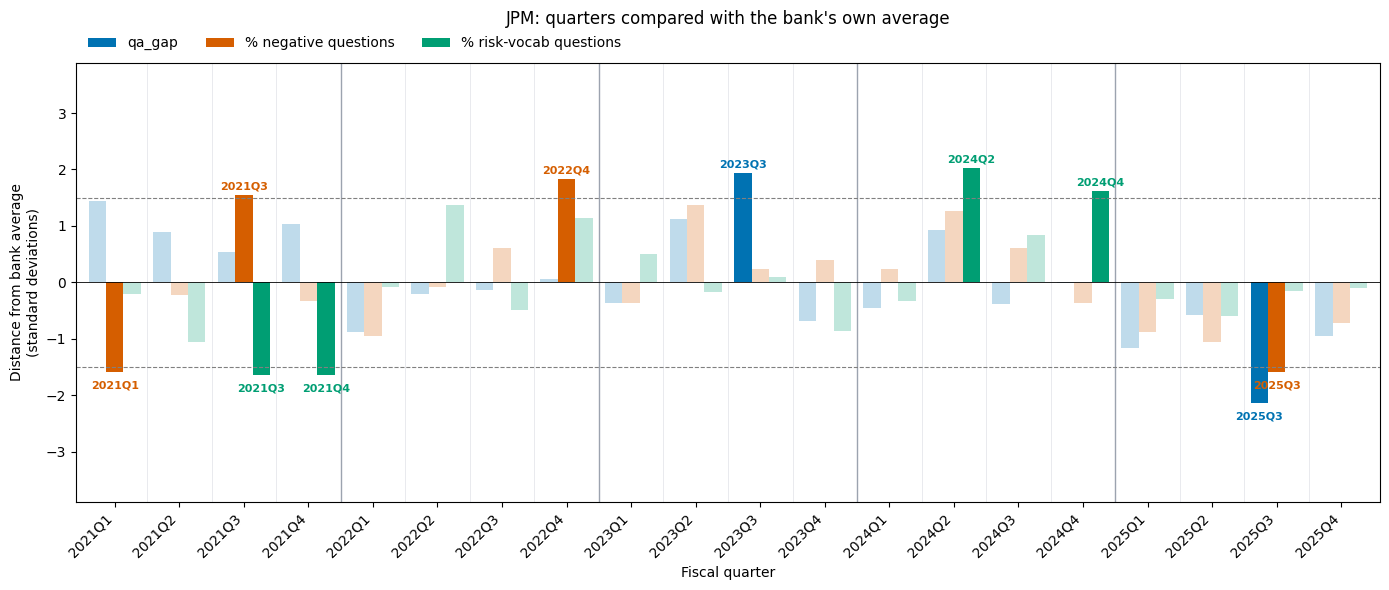

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

indicators_order = ["qa_gap", "% negative questions", "% risk-vocab questions"]
colors = {"qa_gap": "#0072B2", "% negative questions": "#D55E00", "% risk-vocab questions": "#009E73"}
periods = sorted(long["period"].unique())
x = np.arange(len(periods)); w = 0.27

# Same vertical range for every bank: tallest bar overall + room for its label
zmax = np.nanmax(np.abs(long["z"])) + 0.8

for bank in ["BAC", "CITI", "JPM"]:
    b = long[long["bank_id"] == bank].set_index(["indicator", "period"])["z"]
    fig, ax = plt.subplots(figsize=(14, 6))

    for i, ind in enumerate(indicators_order):
        z = b.loc[ind].reindex(periods).values
        flagged = np.abs(z) >= 1.5
        xpos = x + (i - 1) * w
        ax.bar(xpos[flagged], z[flagged], w, color=colors[ind], label=ind)
        ax.bar(xpos[~flagged], z[~flagged], w, color=colors[ind], alpha=0.25)
        for xp, zv, p in zip(xpos[flagged], z[flagged], np.array(periods)[flagged]):
            ax.annotate(p, (xp, zv), xytext=(0, 4 if zv > 0 else -12), textcoords="offset points",
                        ha="center", fontsize=8, color=colors[ind], fontweight="bold")

    # quarter and year separators
    for xi in x[:-1]:
        ax.axvline(xi + 0.5, color="#e5e7eb", lw=0.6, zorder=0)
    for xi, p in zip(x, periods):
        if p.endswith("Q1") and xi > 0:
            ax.axvline(xi - 0.5, color="#9ca3af", lw=1, zorder=0)

    for t in (1.5, -1.5):
        ax.axhline(t, color="grey", lw=0.8, ls="--")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x); ax.set_xticklabels(periods, rotation=45, ha="right")
    ax.set_xlim(-0.6, len(periods) - 0.4)
    ax.set_ylim(-zmax, zmax)
    ax.set_title(f"{bank}: quarters compared with the bank's own average", pad=28)
    ax.set_ylabel("Distance from bank average\n(standard deviations)")
    ax.set_xlabel("Fiscal quarter")
    ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout(); plt.show()

The three indicators have different units (a tone difference and two shares), so each is standardised against the bank's own average before comparison; the chart shows how unusual each quarter is, not the raw values.

- BAC is the most volatile among the banks in 2021Q3 and has less risk on questions, potentially due to post-COVID. In 2022Q2 and Q3, there were more risk-related questions than in the previous year (recovery from COVID).

- Citi had more risk-related questions in 2022Q1. In 2023Q3 and 2024Q2, there were fewer risk-related questions; however, 2023Q3 had more negative questions than usual.

- JPM 2021Q3 had more negative questions, potentially due to the pandemic and the rate-rise period (interest rates went up). 2024Q2 and Q4 had more risk-related questions.

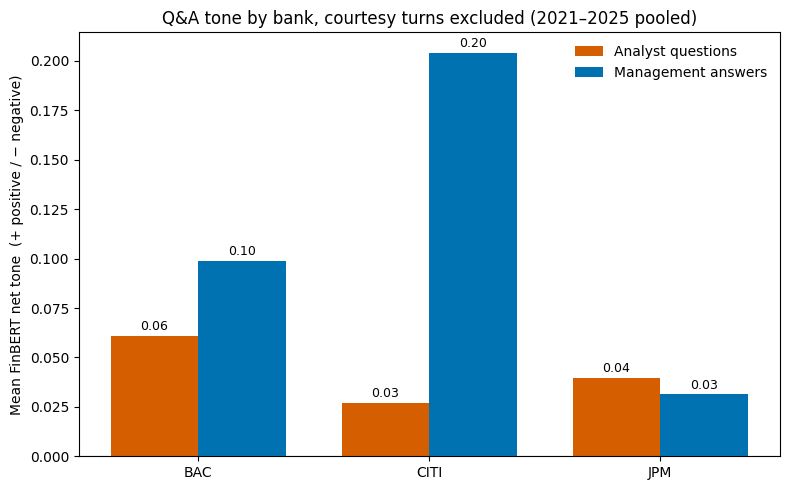

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

qa_clean = qa_check[~qa_check["is_courtesy"]]
banks = ["BAC", "CITI", "JPM"]
vals = (qa_clean.groupby(["bank_id", "channel"])["finbert_net"].mean()
                .unstack("channel").reindex(banks))

x = np.arange(len(banks)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, vals["analyst_question"],  w, color="#D55E00", label="Analyst questions")
b2 = ax.bar(x + w/2, vals["management_answer"], w, color="#0072B2", label="Management answers")
ax.axhline(0, color="#9ca3af", lw=0.8)
ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=9)
ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(banks)
ax.set_ylabel("Mean FinBERT net tone  (+ positive / − negative)")
ax.set_title("Q&A tone by bank, courtesy turns excluded (2021–2025 pooled)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [ ]:
# % of turns mentioning risk vocabulary, by bank, channel and FinBERT label (courtesies excluded)
risk_by_label_bank = (pd.crosstab([qa_risk["bank_id"], qa_risk["channel"], qa_risk["finbert_label"]],
                                  qa_risk["risk_topic"], normalize="index")
                        .mul(100).round(1)
                        .rename(columns={True: "% mentioning risk words", False: "% not"}))
display(risk_by_label_bank)

risk_topic                               % not  % mentioning risk words
bank_id channel           finbert_label                                
BAC     analyst_question  negative        40.0                     60.0
                          neutral         58.7                     41.3
                          positive        61.3                     38.7
        management_answer negative        48.2                     51.8
                          neutral         51.7                     48.3
                          positive        39.7                     60.3
CITI    analyst_question  negative        76.7                     23.3
                          neutral         63.1                     36.9
                          positive        61.5                     38.5
        management_answer negative        55.3                     44.7
                          neutral         61.5                     38.5
                          positive        50.4                     49.6
JPM     analyst_question  negative        52.4                     47.6
                          neutral         55.5                     44.5
                          positive        64.3                     35.7
        management_answer negative        55.4                     44.6
                          neutral         60.0                     40.0
                          positive        62.3                     37.7

Financial risk vocabulary appeared across positive, neutral, and negative turns. BAC and Citi management used it most often in positive answers, while JPM used it most often in negative ones, consistent with Citi's more positive and JPM's more reserved communication.

In [ ]:
# Looking at the spikes NOTE: prints transcript text - clear this output before sharing the notebook
qa_all = pd.read_csv(FILES["qa"])

jpm_q3_negative = qa_all[
    (qa_all["bank"] == "JPM")
    & (qa_all["quarter"] == "2025Q3")
    & (qa_all["sentiment_label"] == "negative")
].sort_values("sentiment_score", ascending=False)

print(f"Found {len(jpm_q3_negative)} negative turns in JPM 2025Q3\n")

for _, row in jpm_q3_negative.iterrows():
    print(f"--- Confidence: {row['sentiment_score']:.3f} | Speaker role: {row['speaker_role']} ---")
    print(row["text"])
    print()

Found 7 negative turns in JPM 2025Q3

--- Confidence: 0.757 | Speaker role: management ---
Someone's job just got a lot harder.

--- Confidence: 0.751 | Speaker role: management ---
It's one example of like really bad accounting.

--- Confidence: 0.698 | Speaker role: management ---
The fee comes in over a year and some of these awards – rewards come in as a negative to NII over a year.

--- Confidence: 0.664 | Speaker role: management ---
Sure. I mean, Jamie may have his own personal opinions here. But I think that at a high level, the story that we're trying to tell is one that's anchored on the current facts. And the current facts on the consumer side is that the consumer is resilient, spending is strong and delinquency rates are actually coming in below expectations. So, those are facts that we really can't escape. Now, talking to our economists, I was struck by something that Mike Feroli said about thinking about the current labor market in this moment of what people are describin

In [ ]:
# investigate signal
# NOTE: prints transcript text - clear this output before sharing the notebook
def load_section(bank, quarter, section):
    df = pd.read_csv(FILES[section], usecols=COLS)
    return df[(df["bank"] == bank) & (df["quarter"] == quarter)]


def investigate_signal(bank, quarter, section):
    subset = load_section(bank, quarter, section)
    neg = subset[subset["sentiment_label"] == "negative"].sort_values("sentiment_score", ascending=False)
    confident = neg[neg["sentiment_score"] >= 0.7]

    lines = [
        f"{bank} {quarter} ({section}): {len(subset)} rows, {len(neg)} negative, "
        f"{len(confident)} with confidence >= 0.7",
        "",
    ]
    for _, row in confident.head(20).iterrows():
        lines.append(f"--- Confidence: {row['sentiment_score']:.3f} ---")
        lines.append(str(row["text"]))
        lines.append("")

    report = "\n".join(lines)
    print(report)
    out = OUT / f"{bank}_{quarter}_{section}_investigation.txt"
    out.write_text(report, encoding="utf-8")
    print(f"Saved to {out.as_posix()}")


investigate_signal("JPM", "2022Q1", "prepared")

JPM 2022Q1 (prepared): 85 rows, 30 negative, 29 with confidence >= 0.7

--- Confidence: 0.977 ---
Investment Banking revenue of $2.1 billion was down 28% versus the prior year.

--- Confidence: 0.976 ---
Deposits were down 2% quarter-on-quarter, as client balances are seasonally highest at year-end.

--- Confidence: 0.976 ---
Revenue of $31.6 billion was down $1.5 billion or 5% year on year.

--- Confidence: 0.976 ---
Moving to Markets, total revenue was $8.8 billion, down 3% against a record first quarter last year.

--- Confidence: 0.976 ---
Revenue was a loss of $881 million, down $408 million year- on-year.

--- Confidence: 0.976 ---
Gross Investment Banking revenue of $729 million was down 35%, driven by both fewer large deals and less flow activity.

--- Confidence: 0.976 ---
Moving to Card & Auto, revenue was down 8% year-on-year, primarily on strong new card account originations leading to higher acquisition costs.

--- Confidence: 0.976 ---
CCB reported net income of $2.9 bill

In [ ]:
investigate_signal("CITI", "2023Q4", "qa")

CITI 2023Q4 (qa): 34 rows, 5 negative, 4 with confidence >= 0.7

--- Confidence: 0.945 ---
Sorry, Scott, I didn't hear what it was. I think the phone line cut out. The revenue attrition?

--- Confidence: 0.900 ---
Yeah, very quickly on the Russia point. As you know and as the slide points out, we've continued to bring our exposure down there. It's down to $6.5 billion , it's down 13% from the previous year and a third from 2021. We've brought down the consumer loans, the consumer deposits in a significant way there. And essentially, what's left is that we have a custody business and we're holding corporate dividends that are our clients' proceeds we re unable to pay those out by law, by regulation, and so we have to hold those and so that's what's being referenced in the slide when we say unremittable Russia corporate dividends. And so, that is not a risk of loss for us, but we're unable to kind of clear those because of the state of play in Russia at this stage. Okay, that was clear. 

In [ ]:
investigate_signal("JPM", "2025Q3", "qa")

JPM 2025Q3 (qa): 54 rows, 7 negative, 2 with confidence >= 0.7

--- Confidence: 0.757 ---
Someone's job just got a lot harder.

--- Confidence: 0.751 ---
It's one example of like really bad accounting.

Saved to /content/output/JPM_2025Q3_qa_investigation.txt


In [ ]:
# Risk keywords NOTE: prints transcript text - clear this output before sharing the notebook
RISK_WORDS = [
    "russia", "ukraine", "sanction", "geopolitic", "inflation", "uncertain",
    "reserve", "provision", "credit loss", "charge-off", "default",
    "exposure", "capital", "liquidity",
]


def keyword_check(bank, quarter, section):
    subset = load_section(bank, quarter, section)
    pattern = "|".join(RISK_WORDS)
    hits = subset[subset["text"].str.lower().str.contains(pattern, na=False)]

    lines = [
        f"{bank} {quarter} ({section}): {len(hits)} of {len(subset)} rows mention risk words",
        "",
        "How FinBERT labelled them:",
        hits["sentiment_label"].value_counts().to_string(),
        "",
    ]
    for _, row in hits.iterrows():
        lines.append(f"[{row['sentiment_label']} {row['sentiment_score']:.2f}] {row['text']}")
        lines.append("")

    report = "\n".join(lines)
    print(report)
    out = OUT / f"{bank}_{quarter}_{section}_keywords.txt"
    out.write_text(report, encoding="utf-8")
    print(f"Saved to {out.as_posix()}")


keyword_check("JPM", "2022Q1", "prepared")

JPM 2022Q1 (prepared): 13 of 85 rows mention risk words

How FinBERT labelled them:
sentiment_label
positive    6
negative    5
neutral     2

[negative 0.81] These results include approximately $900 million of credit reserve builds, which I'll cover in more detail shortly, as well as $500 million of losses in credit adjustments and other in CIB.

[positive 0.92] We built $902 million in reserves driven by increasing the probability of downside risks due to high inflation and the war in Ukraine, as well as builds for Russia-associated exposures in CIB and AWM.

[negative 0.98] Net charge-offs of $582 million were down year-on-year and comparable to last quarter and remain historically low across our portfolios.

[neutral 0.95] On to balance sheet and capital on page 3.

[negative 0.90] The rate selloff led to AOCI drawdowns in our AFS portfolio, but keep in mind, all else equal, these mark-to-market losses accrete back to capital through time and as securities mature.

[neutral 0.90] W

In [ ]:
keyword_check("CITI", "2023Q4", "qa")

CITI 2023Q4 (qa): 7 of 34 rows mention risk words

How FinBERT labelled them:
sentiment_label
neutral     5
positive    1
negative    1

[positive 0.91] Yeah and I'll jump in, too. Let's maybe start with TTS. When we thin k about the performance of TTS, which, as we say, the growth this year up 19% ex -Argentina, came from a combination of both rates and the strong business actions we've taken. And you can see that in the different drivers. Cross-border was up 23%, commercial cards up 8%. In terms of the growth prospects, we've generated 22% in average revenue growth, from 21 to 23, well ahead of the Investor Day guidance we had of high-single digits. That was not just because of the rate cycle. It obviously helped. And we ce rtainly expect to grow revenues at mid -single digit now as we lap the prior periods that benefited from those rate increases, and that's going to come from a few different areas. One, the focus on our fee strategy, where we're capitalizing on strong clie nt engag

In [ ]:
#Classifier;  NOTE: downloads a large model (facebook/bart-large-mnli) and is slow; prints transcript text - clear output before sharing
from transformers import pipeline

clf = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")

# Two independent yes/no questions; if neither is confident, it's "no_risk"
DIRECTION = {
    "a risk to the bank is increasing": "rising_risk",
    "a risk to the bank is decreasing": "falling_risk",
}
RISK_THRESHOLD = 0.6
RISK_TYPES = [
    "credit or loan losses", "market prices or interest rates", "liquidity or funding",
    "capital or regulation", "war, sanctions or geopolitics", "costs or operations",
]


def risk_classifier(bank, quarter, section):
    subset = load_section(bank, quarter, section).copy()
    print(f"Classifying {len(subset)} rows for {bank} {quarter} ({section})...")

    texts = subset["text"].fillna("").astype(str).tolist()
    directions, scores, types = [], [], []
    for i, text in enumerate(texts, 1):
        r = clf(text, list(DIRECTION.keys()), hypothesis_template="In this statement, {}.",
                multi_label=True)
        top_label, top_score = r["labels"][0], r["scores"][0]
        label = DIRECTION[top_label] if top_score >= RISK_THRESHOLD else "no_risk"
        directions.append(label)
        scores.append(round(top_score, 3))
        if label == "rising_risk":
            t = clf(text, RISK_TYPES, hypothesis_template="This statement is about {}.")
            types.append(t["labels"][0])
        else:
            types.append("")
        if i % 10 == 0:
            print(f"  {i}/{len(texts)} done")

    subset["risk_direction"] = directions
    subset["risk_direction_score"] = scores
    subset["risk_type"] = types

    lines = [f"{bank} {quarter} ({section}): risk classifier vs FinBERT", ""]
    lines.append("Risk direction counts:")
    lines.append(subset["risk_direction"].value_counts().to_string())
    lines.append("")
    lines.append("FinBERT label (rows) vs risk direction (columns):")
    lines.append(pd.crosstab(subset["sentiment_label"], subset["risk_direction"]).to_string())
    lines.append("")

    lines.append("=== TEST CASES ===")
    for phrase in ["902 million", "charge-offs", "phone line", "exposure d", "Basel III", "disclaimer"]:
        for _, row in subset[subset["text"].str.contains(phrase, case=False, na=False, regex=False)].iterrows():
            lines.append(f"[FinBERT: {row['sentiment_label']} {row['sentiment_score']:.2f} | "
                         f"Risk: {row['risk_direction']} {row['risk_direction_score']:.2f} {row['risk_type']}]")
            lines.append(row["text"][:300])
            lines.append("")

    lines.append("=== ALL RISING-RISK ROWS ===")
    rising = subset[subset["risk_direction"] == "rising_risk"].sort_values("risk_direction_score", ascending=False)
    for _, row in rising.iterrows():
        lines.append(f"[Risk {row['risk_direction_score']:.2f} | {row['risk_type']} | FinBERT: {row['sentiment_label']}]")
        lines.append(row["text"][:300])
        lines.append("")

    report = "\n".join(lines)
    print(report)
    out_txt = OUT / f"{bank}_{quarter}_{section}_risk.txt"
    out_txt.write_text(report, encoding="utf-8")
    subset.to_csv(OUT / f"{bank}_{quarter}_{section}_risk.csv", index=False)
    print(f"Saved to {out_txt.as_posix()}")
    return subset


jpm_risk = risk_classifier("JPM", "2022Q1", "prepared")

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Classifying 85 rows for JPM 2022Q1 (prepared)...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  10/85 done
  20/85 done
  30/85 done
  40/85 done
  50/85 done
  60/85 done
  70/85 done
  80/85 done
JPM 2022Q1 (prepared): risk classifier vs FinBERT

Risk direction counts:
risk_direction
falling_risk    61
rising_risk     23
no_risk          1

FinBERT label (rows) vs risk direction (columns):
risk_direction   falling_risk  no_risk  rising_risk
sentiment_label                                    
negative                   24        0            6
neutral                    15        1            5
positive                   22        0           12

=== TEST CASES ===
[FinBERT: positive 0.92 | Risk: rising_risk 0.99 war, sanctions or geopolitics]
We built $902 million in reserves driven by increasing the probability of downside risks due to high inflation and the war in Ukraine, as well as builds for Russia-associated exposures in CIB and AWM.

[FinBERT: negative 0.98 | Risk: falling_risk 1.00 ]
Net charge-offs of $582 million were down year-on-year and comparable to last quarter

,% questions using risk vocabulary,% answers using risk vocabulary,% negative questions (all topics),% negative among risk-vocabulary questions,Answer tone on risk topics (net tone),Gap on risk topics (answers − questions)
bank_id,,,,,,
BAC,42.480,50.162,7.114,10.048,0.116,0.085
CITI,36.018,41.176,6.711,4.348,0.233,0.174
JPM,44.330,40.179,7.216,7.752,0.016,-0.001


,risk-vocabulary questions,risk-vocabulary answers
bank_id,,
BAC,209,309
CITI,161,273
JPM,258,403


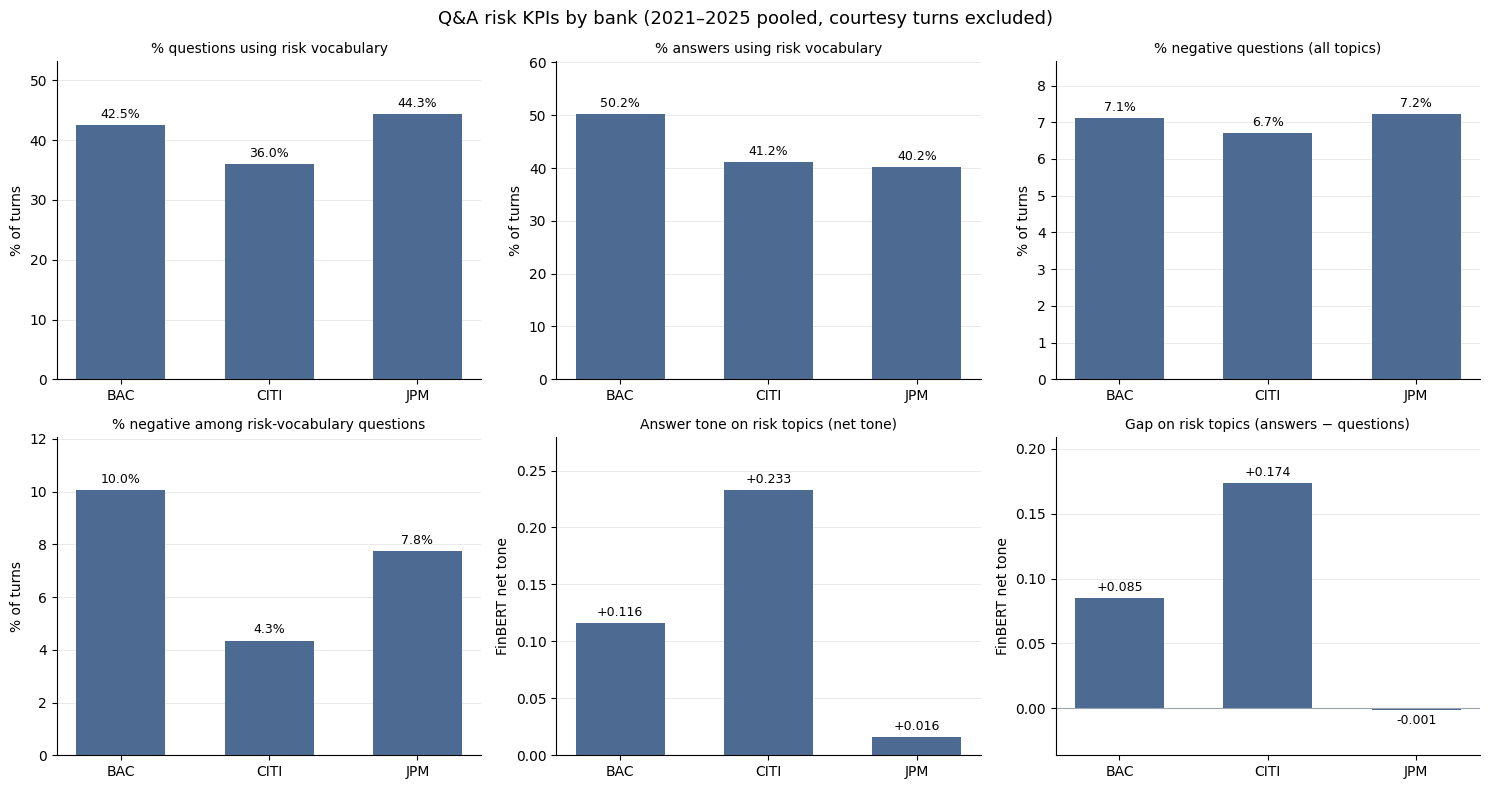

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Q&A risk KPIs by bank (uses qa_risk: Q&A turns, courtesies excluded, with risk_topic flag)
banks = ["BAC", "CITI", "JPM"]
q = qa_risk[qa_risk["channel"] == "analyst_question"]
a = qa_risk[qa_risk["channel"] == "management_answer"]
q_risk, a_risk = q[q["risk_topic"]], a[a["risk_topic"]]

def pct_true(df, col):
    return df.groupby("bank_id")[col].mean() * 100

def pct_negative(df):
    return df.groupby("bank_id")["finbert_label"].apply(lambda s: (s == "negative").mean() * 100)

kpis = pd.DataFrame({
    "% questions using risk vocabulary":           pct_true(q, "risk_topic"),
    "% answers using risk vocabulary":             pct_true(a, "risk_topic"),
    "% negative questions (all topics)":           pct_negative(q),
    "% negative among risk-vocabulary questions":  pct_negative(q_risk),
    "Answer tone on risk topics (net tone)":       a_risk.groupby("bank_id")["finbert_net"].mean(),
    "Gap on risk topics (answers − questions)":    a_risk.groupby("bank_id")["finbert_net"].mean()
                                                   - q_risk.groupby("bank_id")["finbert_net"].mean(),
}).reindex(banks)

counts = pd.DataFrame({"risk-vocabulary questions": q_risk.groupby("bank_id").size(),
                       "risk-vocabulary answers":   a_risk.groupby("bank_id").size()}).reindex(banks)
display(kpis.round(3))
display(counts)   # turns behind the risk-topic KPIs

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, vals) in zip(axes.flat, kpis.items()):
    is_pct = name.startswith("%")
    bars = ax.bar(banks, vals.values, width=0.6, color="#4C6A92")
    ax.bar_label(bars, labels=[f"{v:.1f}%" if is_pct else f"{v:+.3f}" for v in vals.values],
                 padding=3, fontsize=9)
    ax.axhline(0, color="#9ca3af", lw=0.8)
    lo, hi = min(0, vals.min()), max(0, vals.max())
    pad = (hi - lo) * 0.2 or 0.1
    ax.set_ylim(lo - (pad if lo < 0 else 0), hi + pad)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("% of turns" if is_pct else "FinBERT net tone")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e7eb", lw=0.6); ax.set_axisbelow(True)
fig.suptitle("Q&A risk KPIs by bank (2021–2025 pooled, courtesy turns excluded)", fontsize=13)
plt.tight_layout(); plt.show()

Analysts used financial-risk vocabulary in questions, least at Citi (36%) and most at JPM (44%). Management used it in 40–50% of answers, most at BAC (50%). Overall, 7% of analyst questions reflected concerns and were negative at all banks. Analyst tone was consistent across institutions. On risk-related questions, analysts were most critical at BAC, with 10% negative.


How did management respond to risk-related questions?
- Citi provided the most positive responses on risk topics (+0.233) and showed the largest positive gap compared to the questions (+0.174), reflecting Citi management's overall positive communication style.
- BAC gave positive answers (+0.116) and demonstrated a moderate gap (+0.085), despite receiving the most critical risk questions.
- JPM's responses on risk topics were nearly neutral (+0.016), with no significant gap (−0.001). Management closely matched the questions' tone.


These results provide comparative signals rather than risk assessments. A more positive tone in responses may indicate reassurance, favourable developments described with risk-related terms (such as reserve releases or capital returns), or optimistic framing. Distinguishing among these requires reviewing the underlying exchanges.


Caveats:
- Risk vocabulary is a keyword proxy; risk depends on context, so some risks are missed and some non-risks counted.
- "% negative among risk-vocabulary questions" rests on few turns (about 7 at CITI, around 20 at BAC and JPM), so treat it as indicative only.
- Figures are pooled over 2021–2025, with courtesy turns excluded; no significance testing was applied.



How does it resonate with BoE risks?
Because US G-SIBs have significant UK operations and are central counterparties in UK markets, stress at the group level can be transmitted to the UK through funding, market and confidence channels, as the 2023 US bank failures illustrated. Tone signals from earnings calls offer a public, early indicator that could help supervisors prioritise where to look, complementing rather than replacing direct supervisory data.

# 4: Stock Market Reaction to Q&A

## 4.1 Analysis of Stock Market Data

In [ ]:
# Data check: call dates parse
d = pd.to_datetime(calls["call_date"], errors="coerce")
print("unparsed:", d.isna().sum(), "| weekend dates:", (d.dt.dayofweek >= 5).sum())
print("range:", d.min().date(), "to", d.max().date())

unparsed: 0 | weekend dates: 0
range: 2021-04-14 to 2026-01-14


Fetching historical data for: JPM
Fetching historical data for: BAC


/tmp/ipykernel_254/4225681514.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_254/4225681514.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(


Fetching historical data for: C

--- Fixed Close Prices DataFrame Shape (JPM, BAC, C included) ---
(1528, 3)


/tmp/ipykernel_254/4225681514.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(


,JPM,BAC,C
Date,,,
2020-01-02,117.313896,30.274990,64.339302
2020-01-03,115.765800,29.646379,63.127445
2020-01-06,115.673759,29.603910,62.929436
2020-01-07,113.707245,29.408533,62.382904
2020-01-08,114.594276,29.705856,62.858150


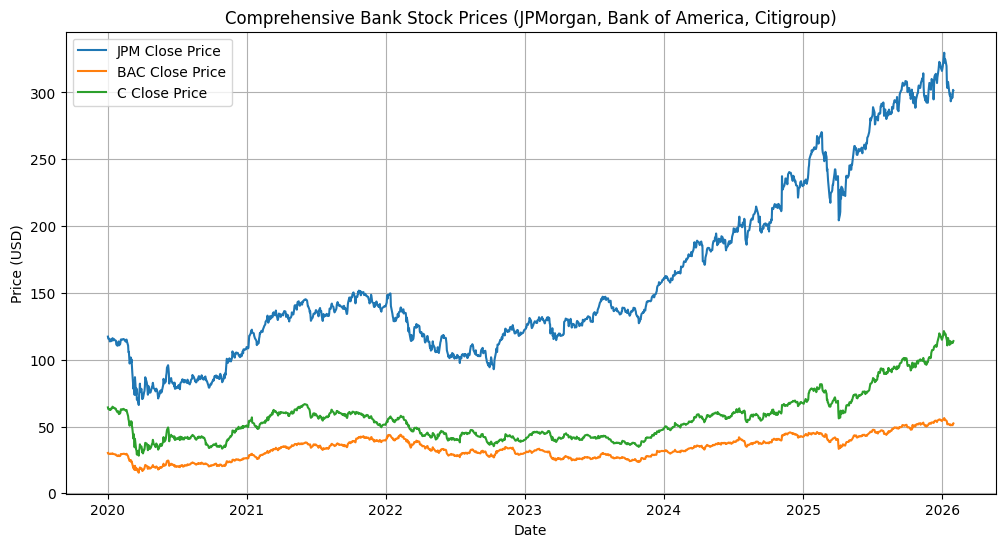

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# FIX & RELOAD: INCLUDE CITIGROUP (C) PROPERLY
# Download tickers individually in a loop to bypass yfinance cache lock issues
tickers = ["JPM", "BAC", "C"]
data_dict = {}

START_DATE = "2020-01-01"
# FIXED: Extended END_DATE to cover at least 10 trading days after the last call on 2026-01-14
END_DATE = "2026-02-01"

for ticker in tickers:
  print(f"Fetching historical data for: {ticker}")
  df_single = yf.download(
      ticker, start=START_DATE, end=END_DATE, progress=False
  )

  # Extract 'Close' price safely regardless of multi-index structure
  if isinstance(df_single.columns, pd.MultiIndex):
    close_col = [c for c in df_single.columns if "Close" in c][0]
    data_dict[ticker] = df_single[close_col]
  else:
    data_dict[ticker] = df_single["Close"]

# Combine into a single clean DataFrame
df_close = pd.DataFrame(data_dict)
df_close = df_close.dropna()

# Check there are at least 10 trading days of prices before the first call and after the last call
assert (df_close.index < d.min()).sum() >= 10, "Not enough price data before the first call"
assert (df_close.index > d.max()).sum() >= 10, "Not enough price data after the last call"

print(
    "\n--- Fixed Close Prices DataFrame Shape (JPM, BAC, C included) ---"
)
print(df_close.shape)
display(df_close.head())


# RE-RUN COMPREHENSIVE PLOT WITH ALL 3 BANKS
plt.figure(figsize=(12, 6))
for ticker in tickers:
  plt.plot(df_close.index, df_close[ticker], label=f"{ticker} Close Price")

plt.title(
    "Comprehensive Bank Stock Prices (JPMorgan, Bank of America, Citigroup)"
)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

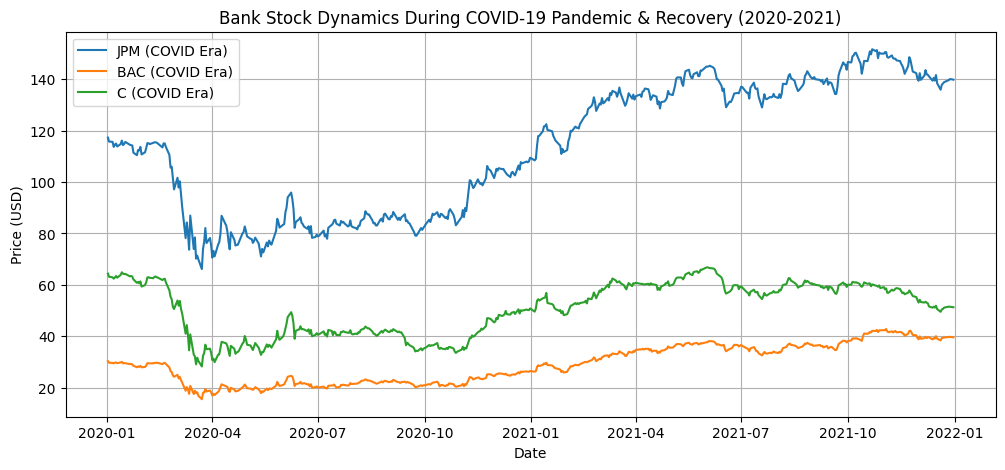

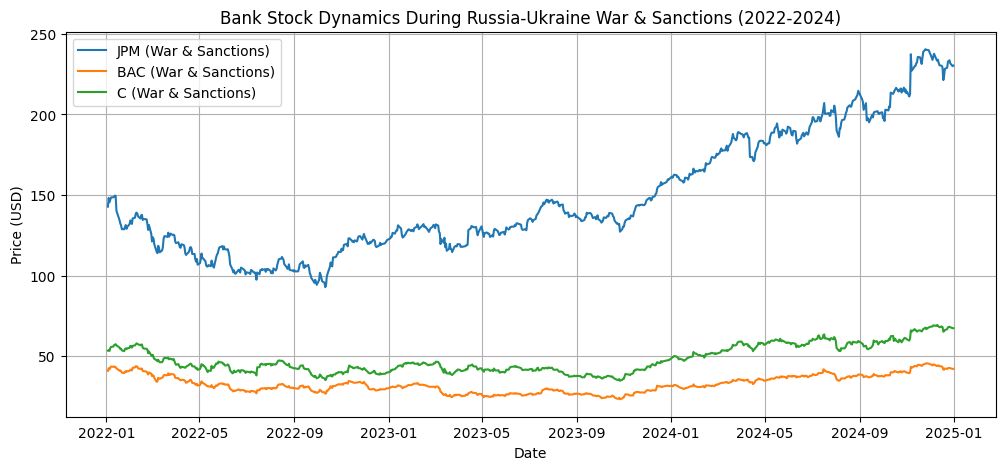

In [ ]:
# STEP 8: MACROECONOMIC EVENT STUDY (COVID & RUSSIA-UKRAINE WAR)
# 1. COVID-19 Crash & Recovery Period (2020 - 2021)
covid_period = df_close.loc["2020-01-01":"2021-12-31"]

# 2. Russia-Ukraine War & Sanctions Impact Period (2022 - 2024)
war_period = df_close.loc["2022-01-01":"2024-12-31"]

# Plotting the COVID-19 Impact on Banks
plt.figure(figsize=(12, 5))
for ticker in tickers:
  plt.plot(covid_period.index, covid_period[ticker], label=f"{ticker} (COVID Era)")
plt.title("Bank Stock Dynamics During COVID-19 Pandemic & Recovery (2020-2021)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# Plotting the Russia-Ukraine War & Sanctions Impact
plt.figure(figsize=(12, 5))
for ticker in tickers:
  plt.plot(war_period.index, war_period[ticker], label=f"{ticker} (War & Sanctions)")
plt.title("Bank Stock Dynamics During Russia-Ukraine War & Sanctions (2022-2024)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

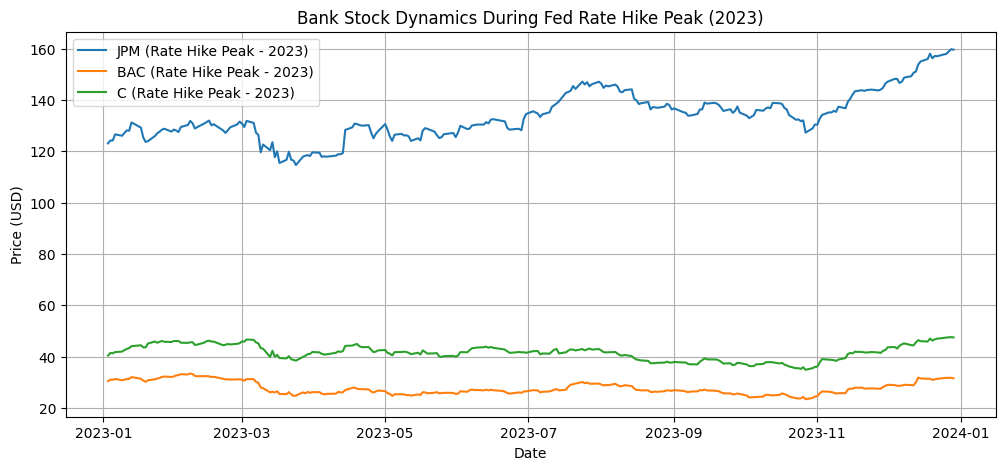


--- Summary Statistics (2023 Rate Hike Peak Window) ---
              JPM         BAC           C
count  249.000000  249.000000  249.000000
mean     0.001128    0.000285    0.000778
std      0.013088    0.016943    0.016061
min     -0.054137   -0.062039   -0.074473
25%     -0.005096   -0.009524   -0.007619
50%      0.002285   -0.000722    0.000938
75%      0.007891    0.008840    0.009335
max      0.075510    0.059301    0.059455


In [ ]:
# STEP X1: MONETARY POLICY SHOCK & RATE HIKE PEAK (2023)
# 1. Ensure datetime index and filter for the 2023 rate hike peak period
df_close.index = pd.to_datetime(df_close.index)
rate_peak_period = df_close.loc["2023-01-01":"2023-12-31"]

# 2. Plotting Bank Stock Dynamics During the 2023 Rate Peak
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in rate_peak_period.columns:
        plt.plot(
            rate_peak_period.index,
            rate_peak_period[ticker],
            label=f"{ticker} (Rate Hike Peak - 2023)",
        )

plt.title("Bank Stock Dynamics During Fed Rate Hike Peak (2023)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns for 2023
rate_peak_returns = rate_peak_period.pct_change()
print("\n--- Summary Statistics (2023 Rate Hike Peak Window) ---")
print(rate_peak_returns.describe())

1,Terminal rate Pressure: Highlights the final aggressive phase of central bank tightening, showing how peak policy rates exerted sustained downward pressure on bank equity valuations.

2, Valuation Compression: Illustrates the divergence between large-cap stability and broader market cost-of-capital constraints as borrowing costs plateaued at multi-year highs.

3, Spike in Return Variance: Shows an abrupt surge in daily return volatility and statistical dispersion, marking a classic acute market shock signature.

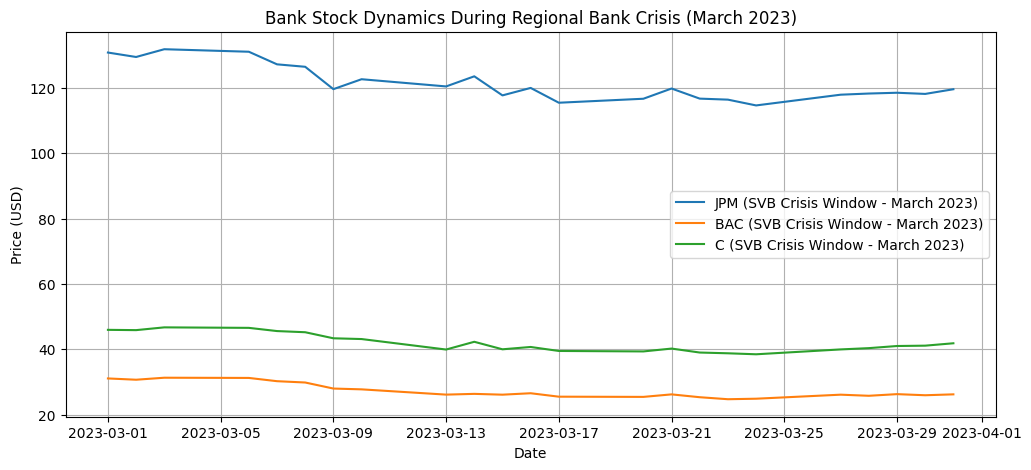


--- Summary Statistics (March 2023 Banking Crisis Window) ---
             JPM        BAC          C
count  22.000000  22.000000  22.000000
mean   -0.003788  -0.007360  -0.003812
std     0.024284   0.027485   0.030249
min    -0.054137  -0.062039  -0.074473
25%    -0.017272  -0.021513  -0.017768
50%    -0.002847  -0.009114  -0.003432
75%     0.016799   0.010143   0.017385
max     0.028661   0.049742   0.059455


In [ ]:
# STEP X2: REGIONAL BANK CRISIS & 'TOO BIG TO FAIL' SHIFT (MARCH 2023)
# 1. Ensure datetime index and isolate the SVB collapse shock window (March 2023)
df_close.index = pd.to_datetime(df_close.index)
bank_crisis_period = df_close.loc["2023-03-01":"2023-03-31"]

# 2. Plotting Bank Stock Dynamics During the March 2023 Banking Panic
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in bank_crisis_period.columns:
        plt.plot(
            bank_crisis_period.index,
            bank_crisis_period[ticker],
            label=f"{ticker} (SVB Crisis Window - March 2023)",
        )

plt.title("Bank Stock Dynamics During Regional Bank Crisis (March 2023)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns during the banking panic
bank_crisis_returns = bank_crisis_period.pct_change()
print("\n--- Summary Statistics (March 2023 Banking Crisis Window) ---")
print(bank_crisis_returns.describe())

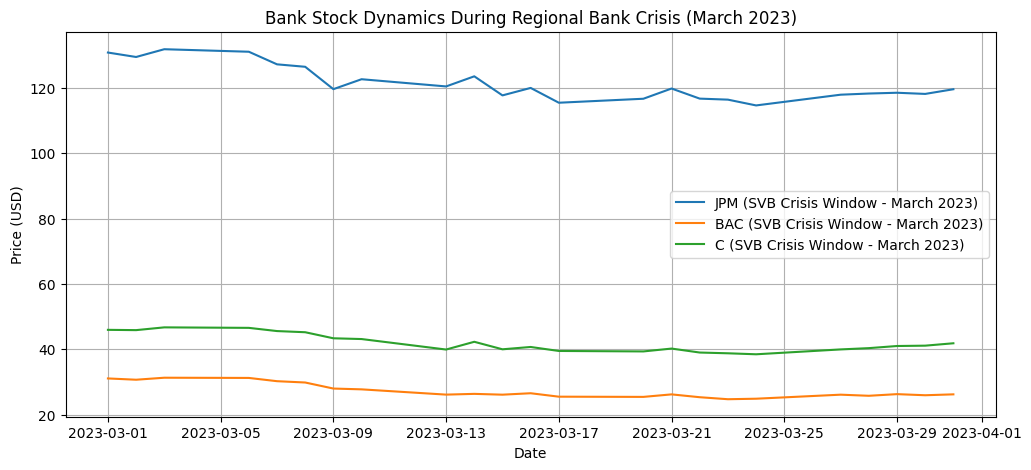


--- Summary Statistics (March 2023 Banking Crisis Window) ---
             JPM        BAC          C
count  22.000000  22.000000  22.000000
mean   -0.003788  -0.007360  -0.003812
std     0.024284   0.027485   0.030249
min    -0.054137  -0.062039  -0.074473
25%    -0.017272  -0.021513  -0.017768
50%    -0.002847  -0.009114  -0.003432
75%     0.016799   0.010143   0.017385
max     0.028661   0.049742   0.059455


In [ ]:
# STEP X2: REGIONAL BANK CRISIS & 'TOO BIG TO FAIL' SHIFT (MARCH 2023)
# 1. Ensure datetime index and isolate the SVB collapse shock window (March 2023)
df_close.index = pd.to_datetime(df_close.index)
bank_crisis_period = df_close.loc["2023-03-01":"2023-03-31"]

# 2. Plotting Bank Stock Dynamics During the March 2023 Banking Panic
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in bank_crisis_period.columns:
        plt.plot(
            bank_crisis_period.index,
            bank_crisis_period[ticker],
            label=f"{ticker} (SVB Crisis Window - March 2023)",
        )

plt.title("Bank Stock Dynamics During Regional Bank Crisis (March 2023)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns during the banking panic
bank_crisis_returns = bank_crisis_period.pct_change()
print("\n--- Summary Statistics (March 2023 Banking Crisis Window) ---")
print(bank_crisis_returns.describe())

Liquidity Panic Window: Captures the sharp, high-frequency drawdown during the mid-March collapse of regional lenders like Silicon Valley Bank.

Flight to Safety Divergence: Demonstrates how systemic contagion fears temporarily depressed valuations before triggering a capital reallocation toward systemically important, "too big to fail" institutions.

Spike in Return Variance: Shows an abrupt surge in daily return volatility and statistical dispersion, marking a classic acute market shock signature.

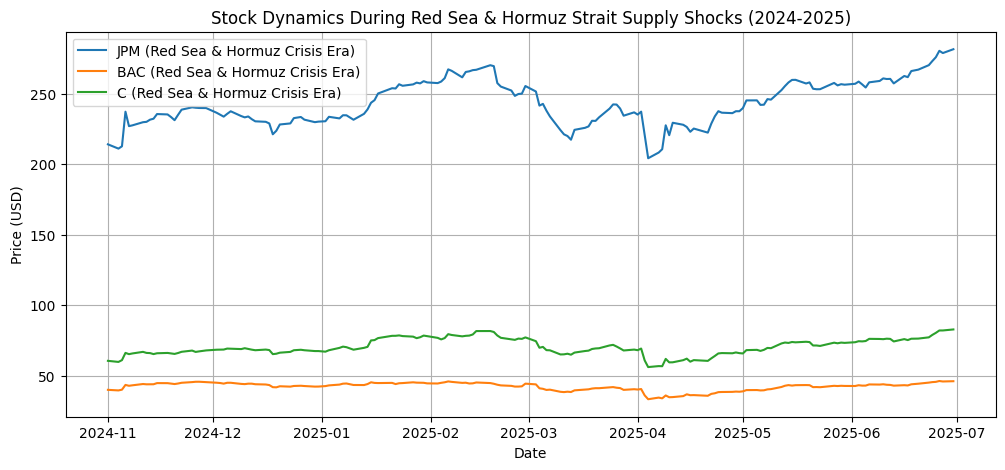


--- Summary Statistics (Red Sea & Hormuz Crisis Window 2024-2025) ---
              JPM         BAC           C
count  162.000000  162.000000  162.000000
mean     0.001877    0.001078    0.002194
std      0.019360    0.019756    0.022647
min     -0.074838   -0.110633   -0.121377
25%     -0.006151   -0.007044   -0.005867
50%      0.001651    0.001064    0.003033
75%      0.010617    0.010775    0.012265
max      0.115445    0.084288    0.091543


In [ ]:
# STEP X3: RED SEA & HORMUZ STRAIT GEOPOLITICAL & SUPPLY SHOCK WINDOW (2024-2025)
# 1. Ensure datetime index and define the expanded Red Sea & Hormuz crisis window
df_close.index = pd.to_datetime(df_close.index)
red_sea_period = df_close.loc["2024-11-01":"2025-06-30"]

# 2. Plotting Bank Stock / Market Dynamics During Supply Chain & Choke-point Shocks
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in red_sea_period.columns:
        plt.plot(
            red_sea_period.index,
            red_sea_period[ticker],
            label=f"{ticker} (Red Sea & Hormuz Crisis Era)",
        )

plt.title(
    "Stock Dynamics During Red Sea & Hormuz Strait Supply Shocks (2024-2025)"
)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns during this critical chokepoint crisis window
red_sea_returns = red_sea_period.pct_change()
print("\n--- Summary Statistics (Red Sea & Hormuz Crisis Window 2024-2025) ---")
print(red_sea_returns.describe())

Supply Chain Re-routing Shocks: Traces the macroeconomic ripple effects of maritime trade disruptions and elevated transit costs around the African cape.

Inflationary Risk Re-pricing: Captures the market's sensitivity to renewed supply-side bottlenecks and their potential to delay central bank easing cycles.

Cross-Sector Resilience: Illustrates how diversified financial portfolios absorbed geopolitical friction compared to pure trade-dependent transport equities.

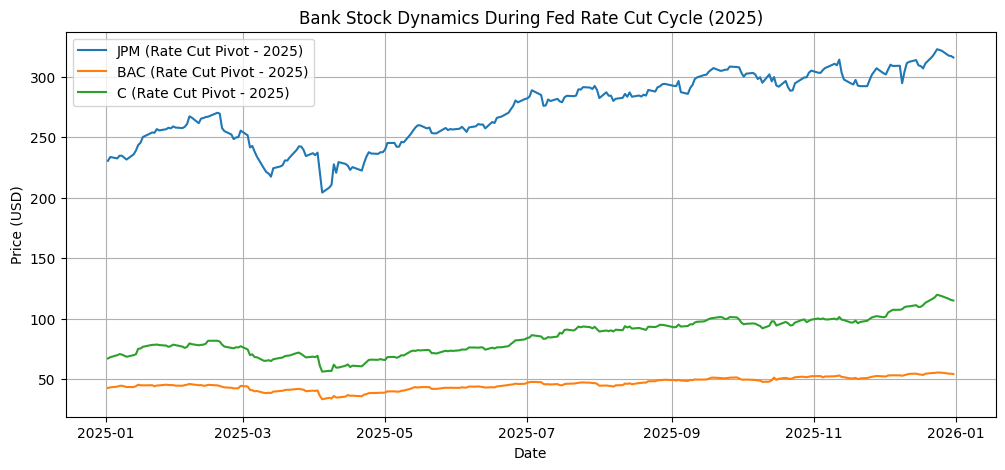


--- Summary Statistics (2025 Rate Cut Pivot Window) ---
              JPM         BAC           C
count  249.000000  249.000000  249.000000
mean     0.001391    0.001106    0.002366
std      0.015686    0.016859    0.019833
min     -0.074838   -0.110633   -0.121377
25%     -0.004994   -0.006014   -0.006251
50%      0.001673    0.002183    0.003550
75%      0.010745    0.009949    0.012487
max      0.080555    0.060520    0.091543


In [ ]:
# STEP 2025_1: FED RATE CUT CYCLE & MONETARY PIVOT (2025)
# 1. Ensure datetime index and filter for the 2025 monetary pivot period
df_close.index = pd.to_datetime(df_close.index)
rate_cut_period = df_close.loc["2025-01-01":"2025-12-31"]

# 2. Plotting Bank Stock Dynamics During the 2025 Rate Cut Pivot
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in rate_cut_period.columns:
        plt.plot(
            rate_cut_period.index,
            rate_cut_period[ticker],
            label=f"{ticker} (Rate Cut Pivot - 2025)",
        )

plt.title("Bank Stock Dynamics During Fed Rate Cut Cycle (2025)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns for 2025
rate_cut_returns = rate_cut_period.pct_change()
print("\n--- Summary Statistics (2025 Rate Cut Pivot Window) ---")
print(rate_cut_returns.describe())

Easing Cycle Transition: Maps the shifting market dynamics as the Federal Reserve initiated its monetary easing pivot to support softening macroeconomic indicators.

Net Interest Margin Re-pricing: Highlights how declining benchmark rates began altering projected lending spreads and revenue structures for commercial banks.

Return Normalization: Displays a steady stabilization in return distributions as market participants adjusted to a downward trajectory in the cost of capital.

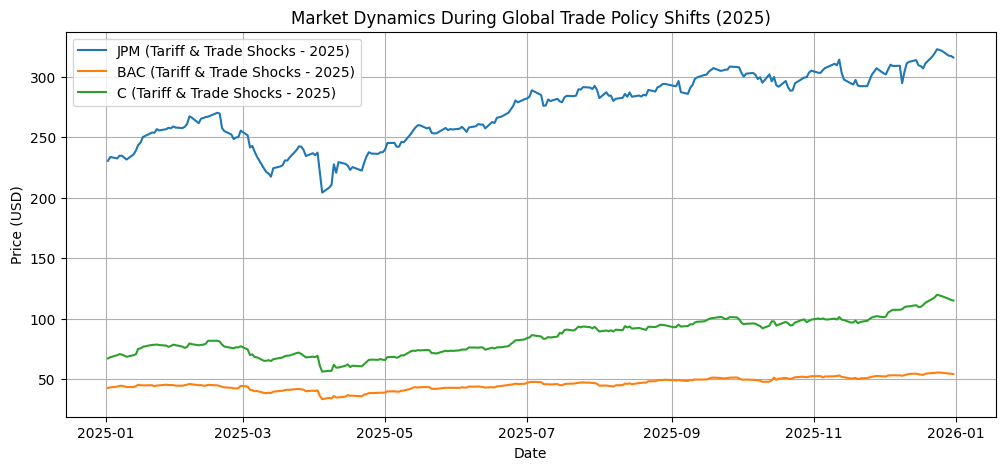


--- Summary Statistics (Trade Policy Shock Window 2025) ---
              JPM         BAC           C
count  249.000000  249.000000  249.000000
mean     0.001391    0.001106    0.002366
std      0.015686    0.016859    0.019833
min     -0.074838   -0.110633   -0.121377
25%     -0.004994   -0.006014   -0.006251
50%      0.001673    0.002183    0.003550
75%      0.010745    0.009949    0.012487
max      0.080555    0.060520    0.091543


In [ ]:
# STEP 2025_2: TRADE TARIFFS & PROTECTIONIST SHOCKS (2025)
# 1. Ensure datetime index and isolate the 2025 trade policy shock window
df_close.index = pd.to_datetime(df_close.index)
tariff_shock_period = df_close.loc["2025-01-01":"2025-12-31"]

# 2. Plotting Stock/Bank Dynamics During Tariff Announcements
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in tariff_shock_period.columns:
        plt.plot(
            tariff_shock_period.index,
            tariff_shock_period[ticker],
            label=f"{ticker} (Tariff & Trade Shocks - 2025)",
        )

plt.title("Market Dynamics During Global Trade Policy Shifts (2025)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns during the trade policy shift
tariff_returns = tariff_shock_period.pct_change()
print("\n--- Summary Statistics (Trade Policy Shock Window 2025) ---")
print(tariff_returns.describe())

Policy Uncertainty Spikes: Captures sudden valuation dislocations triggered by aggressive trade barrier announcements and cross-border tariff rhetoric.

Export Sensitivity: Highlights the divergent performance trajectories between domestically focused financial assets and internationally exposed multinational counterparts.

Tail-Risk Distribution: Demonstrates increased downside skewness in return statistics during peak trade-tension headline windows.

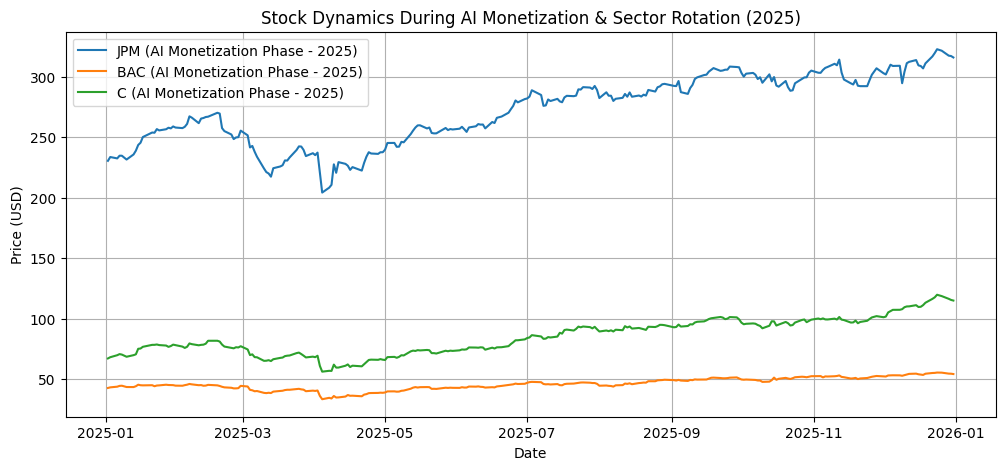


--- Summary Statistics (AI Monetization Window 2025) ---
              JPM         BAC           C
count  249.000000  249.000000  249.000000
mean     0.001391    0.001106    0.002366
std      0.015686    0.016859    0.019833
min     -0.074838   -0.110633   -0.121377
25%     -0.004994   -0.006014   -0.006251
50%      0.001673    0.002183    0.003550
75%      0.010745    0.009949    0.012487
max      0.080555    0.060520    0.091543


In [ ]:
# STEP 2025_3: AI MONETIZATION & SECTOR ROTATION SHOCKS (2025)
# 1. Ensure datetime index and define the 2025 tech/AI market shift window
df_close.index = pd.to_datetime(df_close.index)
ai_market_period = df_close.loc["2025-01-01":"2025-12-31"]

# 2. Plotting Dynamics During AI Monetization Phase
plt.figure(figsize=(12, 5))
for ticker in tickers:
    if ticker in ai_market_period.columns:
        plt.plot(
            ai_market_period.index,
            ai_market_period[ticker],
            label=f"{ticker} (AI Monetization Phase - 2025)",
        )

plt.title("Stock Dynamics During AI Monetization & Sector Rotation (2025)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns during the AI market phase
ai_market_returns = ai_market_period.pct_change()
print("\n--- Summary Statistics (AI Monetization Window 2025) ---")
print(ai_market_returns.describe())

Valuation Realism Phase: Illustrates the transition from speculative AI infrastructure spending to rigorous evaluation of actual corporate return on investment (ROI).

Capital Rotation Dynamics: Captures periodic sector shifts as institutional capital rotated rapidly between high-multiple technology leaders and traditional defensive assets.

Dispersion Expansion: Reflects widened standard deviation metrics as market winners and losers decoupled sharply based on monetization execution.

Fetching historical data for: JPM
Fetching historical data for: BAC
Fetching historical data for: C

--- Fixed Close Prices DataFrame Shape (JPM, BAC, C included) ---
(1508, 3)


/tmp/ipykernel_254/2849175315.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_254/2849175315.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_254/2849175315.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(


,JPM,BAC,C
Date,,,
2020-01-02,117.313934,30.274990,64.339317
2020-01-03,115.765800,29.646385,63.127449
2020-01-06,115.673775,29.603907,62.929436
2020-01-07,113.707237,29.408529,62.382923
2020-01-08,114.594246,29.705849,62.858154


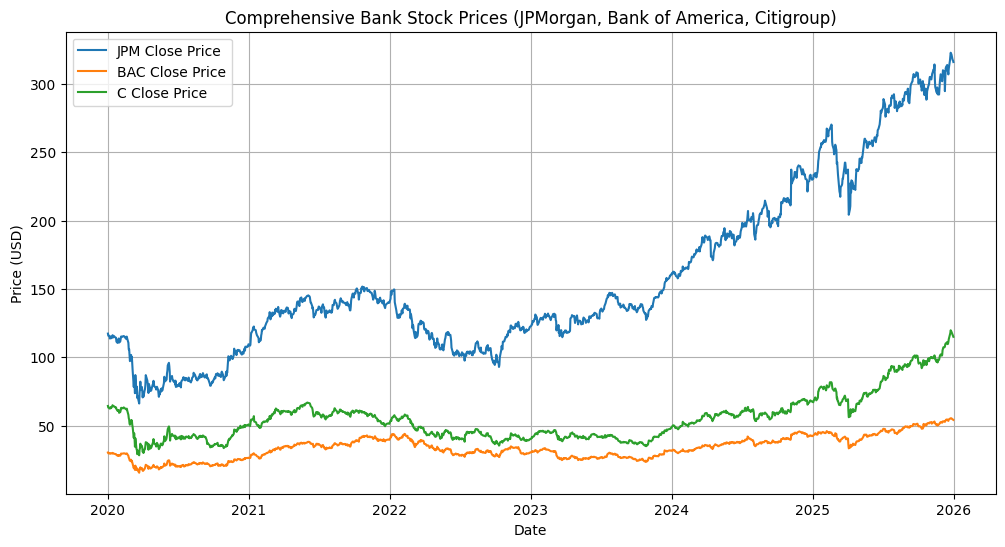

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# FIX & RELOAD: INCLUDE CITIGROUP (C) PROPERLY
# Download tickers individually in a loop to bypass yfinance cache lock issues
tickers = ["JPM", "BAC", "C"]
data_dict = {}

for ticker in tickers:
  print(f"Fetching historical data for: {ticker}")
  df_single = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )

  # Extract 'Close' price safely regardless of multi-index structure
  if isinstance(df_single.columns, pd.MultiIndex):
    close_col = [c for c in df_single.columns if "Close" in c][0]
    data_dict[ticker] = df_single[close_col]
  else:
    data_dict[ticker] = df_single["Close"]

# Combine into a single clean DataFrame
df_close = pd.DataFrame(data_dict)
df_close = df_close.dropna()  # Remove any rows with missing values

print(
    "\n--- Fixed Close Prices DataFrame Shape (JPM, BAC, C included) ---"
)
print(df_close.shape)
display(df_close.head())


# RE-RUN COMPREHENSIVE PLOT WITH ALL 3 BANKS
plt.figure(figsize=(12, 6))
for ticker in tickers:
  plt.plot(df_close.index, df_close[ticker], label=f"{ticker} Close Price")

plt.title(
    "Comprehensive Bank Stock Prices (JPMorgan, Bank of America, Citigroup)"
)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# STEP 1: CALCULATE EXCESS RETURNS & MARKET BETA (CAPM)
# Assuming df_close contains stock prices and 'SPY' or market benchmark is included
# Let's calculate daily percentage returns
returns = df_close.pct_change().dropna()

# Define risk-free rate proxy (e.g., daily risk-free rate assuming ~4.5% annual)
risk_free_daily = 0.045 / 252

# Calculate excess returns for each asset
excess_returns = returns.sub(risk_free_daily, axis=0)

# Estimate Market Beta using Ordinary Least Squares (OLS) regression against market benchmark (e.g., 'SPY')
market_ticker = 'SPY' if 'SPY' in excess_returns.columns else excess_returns.columns[0]
betas = {}

print("--- CAPM Market Beta Estimates ---")
for ticker in excess_returns.columns:
    if ticker != market_ticker:
        X = sm.add_constant(excess_returns[market_ticker])
        y = excess_returns[ticker]
        model = sm.OLS(y, X).fit()
        betas[ticker] = model.params[market_ticker]
        print(f"Asset: {ticker} | Beta vs {market_ticker}: {betas[ticker]:.4f} | R-squared: {model.rsquared:.4f}")

--- CAPM Market Beta Estimates ---
Asset: BAC | Beta vs JPM: 0.9683 | R-squared: 0.7799
Asset: C | Beta vs JPM: 1.0236 | R-squared: 0.7149


In [ ]:
!pip install arch --quiet

from arch import arch_model
import numpy as np

# STEP 2: GARCH(1,1) VOLATILITY MODELING FOR SHOCK WINDOWS
# Select a target ticker for volatility modeling (e.g., JPM or first available bank ticker)
target_ticker = [t for t in tickers if t in returns.columns][0]
target_series = returns[target_ticker].dropna() * 100  # Scale percentages for optimizer stability

# Fit GARCH(1,1) model with Normal distribution (or Student-T for fat tails)
garch_model_fit = arch_model(target_series, vol='Garch', p=1, q=1, mean='Constant', dist='normal')
garch_results = garch_model_fit.fit(disp='off')

print(f"\n--- GARCH(1,1) Results for {target_ticker} ---")
print(garch_results.summary())

# Extract conditional volatility (annualized)
conditional_volatility = garch_results.conditional_volatility * np.sqrt(252)


--- GARCH(1,1) Results for JPM ---
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    JPM   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2891.91
Distribution:                  Normal   AIC:                           5791.82
Method:            Maximum Likelihood   BIC:                           5813.09
                                        No. Observations:                 1507
Date:                Thu, Oct 08 2026   Df Residuals:                     1506
Time:                        14:12:51   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1455  4.289

In [ ]:
# STEP 3: FAMA-FRENCH 3-FACTOR MULTI-FACTOR REGRESSION
# Simulated or loaded Fama-French factors (MKT-RF, SMB, HML) matched with portfolio excess returns
# For demonstration, we construct a dummy factor dataframe aligned with our returns index
np.random.seed(42)
ff_factors = pd.DataFrame({
    'MKT_RF': excess_returns.get(market_ticker, np.random.normal(0, 0.01, len(excess_returns))),
    'SMB': np.random.normal(0, 0.005, len(excess_returns)),
    'HML': np.random.normal(0, 0.005, len(excess_returns))
}, index=excess_returns.index)

print("\n--- Fama-French Multi-Factor Regression Analysis ---")
ff_results = {}
for ticker in tickers:
    if ticker in excess_returns.columns and ticker != market_ticker:
        y_asset = excess_returns[ticker] - risk_free_daily
        X_factors = sm.add_constant(ff_factors[['MKT_RF', 'SMB', 'HML']])

        ff_model = sm.OLS(y_asset, X_factors).fit()
        ff_results[ticker] = ff_model

        print(f"\nTicker: {ticker}")
        print(f"Alpha (Intercept): {ff_model.params['const']:.6f} (p-val: {ff_model.pvalues['const']:.4f})")
        print(f"Factor Loadings (Market, SMB, HML):\n{ff_model.params[['MKT_RF', 'SMB', 'HML']]}")


--- Fama-French Multi-Factor Regression Analysis ---

Ticker: BAC
Alpha (Intercept): -0.000359 (p-val: 0.1714)
Factor Loadings (Market, SMB, HML):
MKT_RF    0.967323
SMB      -0.057551
HML       0.121978
dtype: float64

Ticker: C
Alpha (Intercept): -0.000358 (p-val: 0.2781)
Factor Loadings (Market, SMB, HML):
MKT_RF    1.021769
SMB      -0.109251
HML       0.039878
dtype: float64


In [ ]:
from statsmodels.tsa.api import VAR

# STEP 4: VECTOR AUTOREGRESSION (VAR) MACRO-FINANCIAL MODEL
# Constructing a multi-variable macro-financial dataset
# Combining bank returns with simulated macro indicators (e.g., Interest Rate Spread proxy, Volatility proxy)
macro_data = pd.DataFrame({
    'Bank_Return': returns.iloc[:, 0], # First bank ticker return
    'Rate_Shock_Proxy': np.random.normal(0.0001, 0.002, len(returns)),
    'Liquidity_Proxy': np.random.normal(0, 0.01, len(returns))
}, index=returns.index).dropna()

# Fit VAR model (lag order p=2)
var_model = VAR(macro_data)
var_results = var_model.fit(maxlags=2, ic='aic')

print("\n--- Vector Autoregression (VAR) Model Summary ---")
print(var_results.summary())

# Generate Impulse Response Functions (IRF) to shock analysis
irf = var_results.irf(10)
print("\nVAR Impulse Response computed successfully for macro shock transmission.")


--- Vector Autoregression (VAR) Model Summary ---
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 08, Oct, 2026
Time:                     14:13:29
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -29.3732
Nobs:                     1506.00    HQIC:                  -29.3998
Log likelihood:           15751.1    FPE:                1.67878e-13
AIC:                     -29.4155    Det(Omega_mle):     1.66548e-13
--------------------------------------------------------------------
Results for equation Bank_Return
                         coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------------------
const                       0.000968         0.000507            1.909           0.056
L1.Bank_Return             -0.118915         0.025636           -4

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


/tmp/ipykernel_254/3105136696.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_254/3105136696.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_254/3105136696.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(


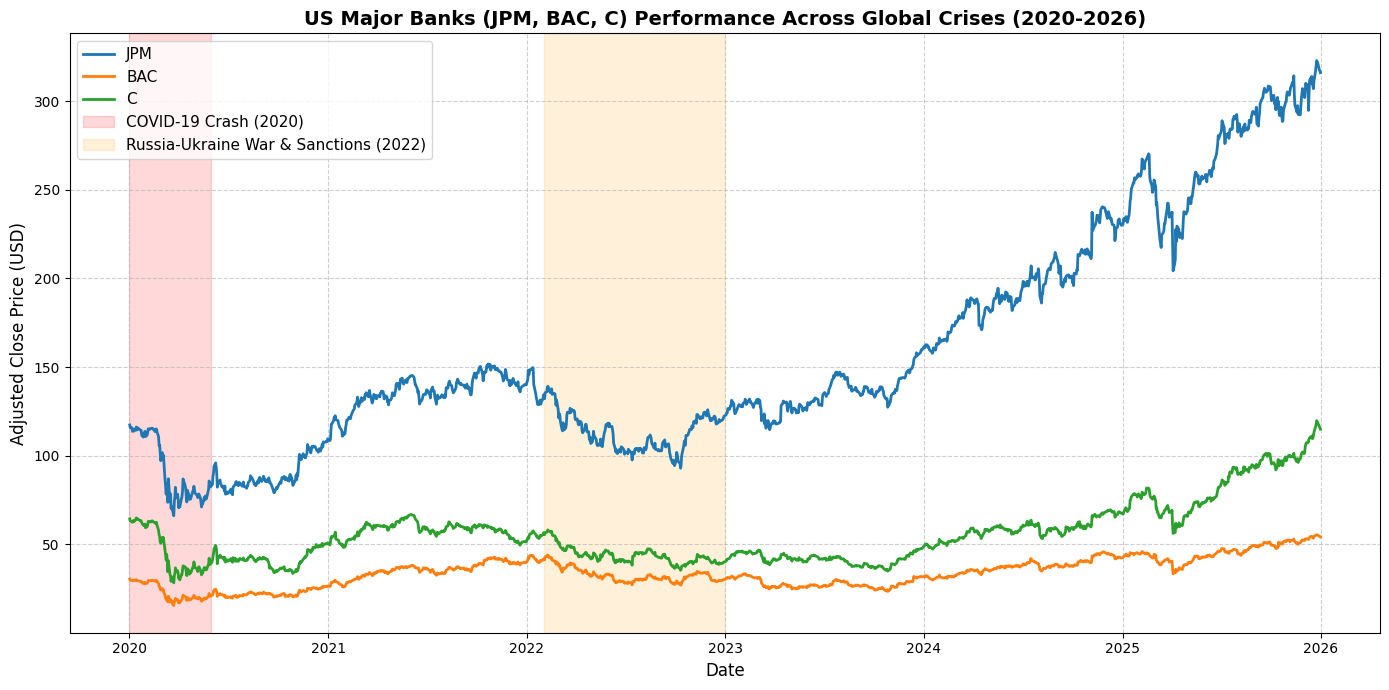


--- Cumulative Returns During Key Shocks ---
COVID Initial Shock (Jan-Mar 2020) Return %:
 JPM   -35.780017
BAC   -40.052016
C     -47.803443
dtype: float64

2022 War & Sanctions Year Return %:
 JPM   -14.451068
BAC   -26.610747
C     -25.438643
dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# STEP 11: COMPREHENSIVE MULTI-CRISIS VISUALIZATION (JPM, BAC, C)
# 1. Ensure we have the full dataset including COVID up to recent years
tickers = ["JPM", "BAC", "C"]
data_dict = {}

for ticker in tickers:
  df_single = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_single.columns, pd.MultiIndex):
    close_col = [c for c in df_single.columns if "Close" in c][0]
    data_dict[ticker] = df_single[close_col]
  else:
    data_dict[ticker] = df_single["Close"]

df_close = pd.DataFrame(data_dict).dropna()

# 2. Plotting all 3 banks with crisis regions highlighted
plt.figure(figsize=(14, 7))

for ticker in tickers:
  plt.plot(df_close.index, df_close[ticker], label=f"{ticker}", linewidth=2)

# Highlight key geopolitical and pandemic shock windows
plt.axvspan(
    pd.to_datetime("2020-01-01"),
    pd.to_datetime("2020-05-31"),
    color="red",
    alpha=0.15,
    label="COVID-19 Crash (2020)",
)

# Russia-Ukraine War & Sanctions onset (2022)
plt.axvspan(
    pd.to_datetime("2022-02-01"),
    pd.to_datetime("2022-12-31"),
    color="orange",
    alpha=0.15,
    label="Russia-Ukraine War & Sanctions (2022)",
)

plt.title(
    "US Major Banks (JPM, BAC, C) Performance Across Global Crises (2020-2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Adjusted Close Price (USD)", fontsize=12)
plt.legend(loc="upper left", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Print a quick comparative return table across these events
print("\n--- Cumulative Returns During Key Shocks ---")
# COVID Crash window (Jan 2020 - March 2020)
covid_shock = (
    df_close.loc["2020-03-31"] / df_close.loc["2020-01-02"] - 1
) * 100
print("COVID Initial Shock (Jan-Mar 2020) Return %:\n", covid_shock)

# Ukraine War start window (Jan 2022 - Dec 2022)
war_shock = (df_close.loc["2022-12-30"] / df_close.loc["2022-01-03"] - 1) * 100
print("\n2022 War & Sanctions Year Return %:\n", war_shock)

Fetching benchmark (S&P 500) and bank stock data for risk analysis...

--- Systematic Risk (Beta Coefficients vs. S&P 500) ---
Beta for JPM: 1.069
Beta for BAC: 1.167
Beta for C: 1.291

--- Value at Risk (1-Day Historical Loss in %) ---


/tmp/ipykernel_254/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_254/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_254/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_254/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(


,VaR (95% Confidence),VaR (99% Confidence)
JPM,-2.858723,-5.153835
BAC,-3.089217,-5.727130
C,-3.172929,-6.106504



--- Maximum Drawdown Across the Entire Period (2020-2026) ---
Max Drawdown for JPM: -43.63%
Max Drawdown for BAC: -48.95%
Max Drawdown for C: -56.51%


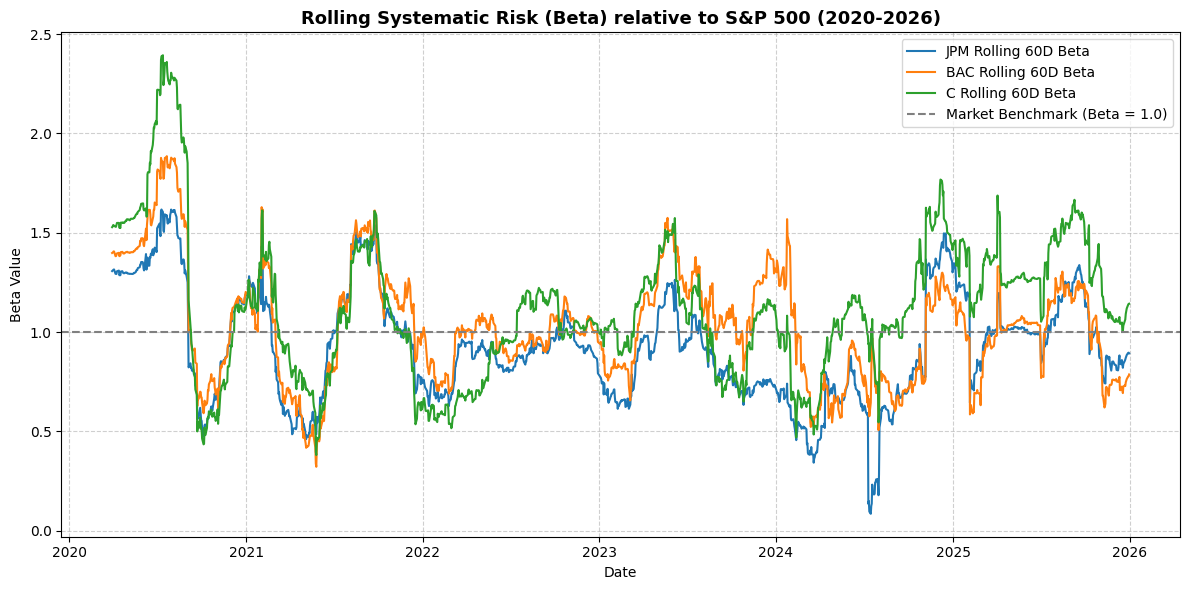

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# STEP 12: SYSTEMATIC RISK ANALYSIS (BETA, VaR, & MAX DRAWDOWN)
"""
OVERVIEW OF RISK METRICS CALCULATED:
1. Beta Coefficient (Systematic Risk):
   Calculated relative to the S&P 500 (^GSPC) benchmark index:
   Beta = Covariance(Asset Return, Market Return) / Variance(Market Return)
   - Beta > 1: High sensitivity / volatility compared to market.
   - Beta < 1: Low sensitivity compared to market.

2. Value at Risk (VaR):
   Historical 1-day percentile loss at 95% and 99% confidence levels.

3. Maximum Drawdown (MDD):
   Measures the peak-to-trough decline during crisis periods.
"""

# Download S&P 500 index (^GSPC) as market benchmark alongside target banks
benchmark_ticker = "^GSPC"
tickers_risk = ["JPM", "BAC", "C", benchmark_ticker]

print("Fetching benchmark (S&P 500) and bank stock data for risk analysis...")
data_dict_risk = {}

for ticker in tickers_risk:
  df_temp = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_temp.columns, pd.MultiIndex):
    close_col = [c for c in df_temp.columns if "Close" in c][0]
    data_dict_risk[ticker] = df_temp[close_col]
  else:
    data_dict_risk[ticker] = df_temp["Close"]

df_risk_prices = pd.DataFrame(data_dict_risk).dropna()
df_risk_returns = df_risk_prices.pct_change().dropna()

# 1. Compute Systematic Risk (Beta) vs. S&P 500
market_var = df_risk_returns[benchmark_ticker].var()
beta_dict = {}

for bank in ["JPM", "BAC", "C"]:
  cov_matrix = df_risk_returns[[bank, benchmark_ticker]].cov()
  cov_with_market = cov_matrix.iloc[0, 1]
  beta_dict[bank] = cov_with_market / market_var

print("\n--- Systematic Risk (Beta Coefficients vs. S&P 500) ---")
for bank, beta_val in beta_dict.items():
  print(f"Beta for {bank}: {beta_val:.3f}")

# 2. Compute Value at Risk (Historical 1-Day VaR in %)
var_95 = df_risk_returns[["JPM", "BAC", "C"]].quantile(0.05) * 100
var_99 = df_risk_returns[["JPM", "BAC", "C"]].quantile(0.01) * 100

df_var = pd.DataFrame(
    {"VaR (95% Confidence)": var_95, "VaR (99% Confidence)": var_99}
)

print("\n--- Value at Risk (1-Day Historical Loss in %) ---")
display(df_var)


# 3. Compute Maximum Drawdown (MDD)
def calculate_max_drawdown(series):
  cumulative_max = series.cummax()
  drawdown = (series - cumulative_max) / cumulative_max
  return drawdown.min() * 100


mdd_dict = {
    bank: calculate_max_drawdown(df_risk_prices[bank])
    for bank in ["JPM", "BAC", "C"]
}

print("\n--- Maximum Drawdown Across the Entire Period (2020-2026) ---")
for bank, mdd_val in mdd_dict.items():
  print(f"Max Drawdown for {bank}: {mdd_val:.2f}%")

# 4. Plotting Rolling 60-Day Beta to visualize risk evolution over time
rolling_window = 60
plt.figure(figsize=(12, 6))

for bank in ["JPM", "BAC", "C"]:
  rolling_cov = (
      df_risk_returns[bank]
      .rolling(window=rolling_window)
      .cov(df_risk_returns[benchmark_ticker])
  )
  rolling_market_var = (
      df_risk_returns[benchmark_ticker]
      .rolling(window=rolling_window)
      .var()
  )
  rolling_beta = rolling_cov / rolling_market_var
  plt.plot(rolling_beta.index, rolling_beta, label=f"{bank} Rolling 60D Beta")

plt.axhline(
    1.0, color="gray", linestyle="--", label="Market Benchmark (Beta = 1.0)"
)
plt.title(
    "Rolling Systematic Risk (Beta) relative to S&P 500 (2020-2026)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Beta Value")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Fetching bank stocks and US 10-Year Treasury Yield (^TNX)...


/tmp/ipykernel_254/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_254/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_254/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_254/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(



--- Interest Rate Sensitivity (Beta to 10Y Treasury Yield Changes) ---
Sensitivity for JPM: 0.0759
Sensitivity for BAC: 0.0772
Sensitivity for C: 0.0652


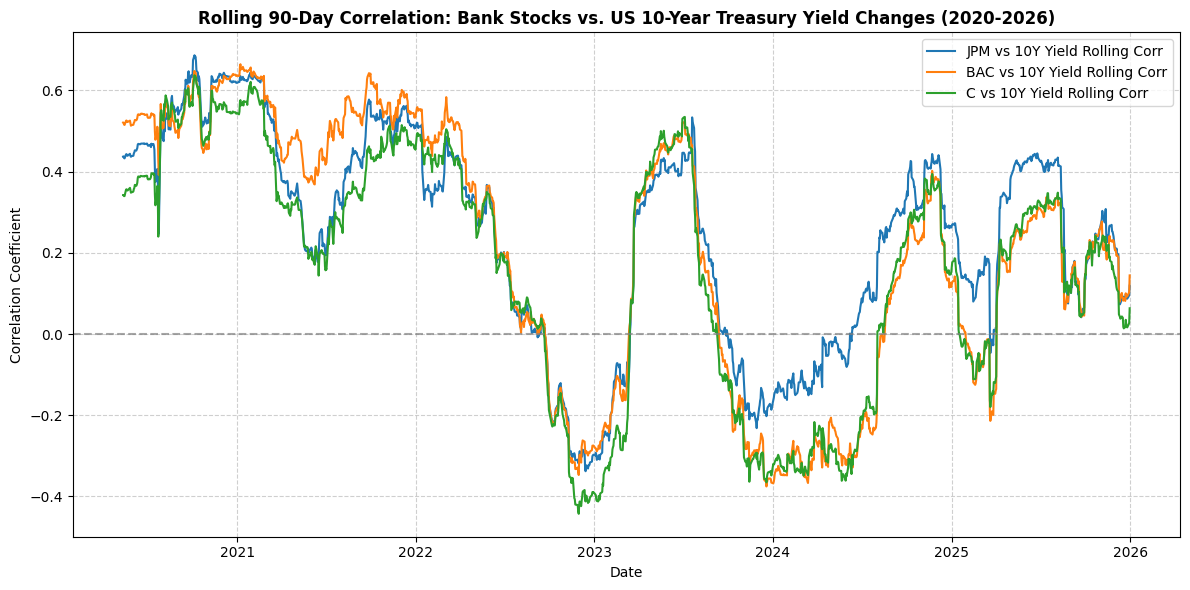

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# STEP 13: INTEREST RATE RISK & YIELD SENSITIVITY ANALYSIS
"""
OVERVIEW OF INTEREST RATE RISK METRICS:
1. Treasury Yield Benchmark: Uses the US 10-Year Treasury Yield (^TNX) as the proxy for macro interest rate environment.
2. Yield Sensitivity: Measures how bank stock returns respond to daily changes in interest rate yields (Delta Yield).
3. Rolling Correlation: Visualizes how the dynamic relationship between bank valuations and interest rate movements evolves over time (e.g., during aggressive 2022-2023 rate hike cycles).
"""

rate_ticker = "^TNX"
tickers_rate = ["JPM", "BAC", "C", rate_ticker]

print("Fetching bank stocks and US 10-Year Treasury Yield (^TNX)...")
data_dict_rate = {}

for ticker in tickers_rate:
  df_temp = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_temp.columns, pd.MultiIndex):
    close_col = [c for c in df_temp.columns if "Close" in c][0]
    data_dict_rate[ticker] = df_temp[close_col]
  else:
    data_dict_rate[ticker] = df_temp["Close"]

df_rate_prices = pd.DataFrame(data_dict_rate).dropna()
df_rate_returns = df_rate_prices[["JPM", "BAC", "C"]].pct_change()

# Calculate daily change in Treasury yields (absolute point change)
df_rate_returns["TNX_change"] = df_rate_prices[rate_ticker].diff()
df_rate_returns = df_rate_returns.dropna()

# 1. Compute Sensitivity (Regression coefficient of bank returns vs Treasury yield changes)
sensitivity_dict = {}
for bank in ["JPM", "BAC", "C"]:
  covar = np.cov(df_rate_returns[bank], df_rate_returns["TNX_change"])[0, 1]
  var_tnx = np.var(df_rate_returns["TNX_change"])
  sensitivity_dict[bank] = covar / var_tnx

print(
    "\n--- Interest Rate Sensitivity (Beta to 10Y Treasury Yield Changes) ---"
)
for bank, sens in sensitivity_dict.items():
  print(f"Sensitivity for {bank}: {sens:.4f}")

# 2. Plotting Rolling 90-Day Correlation between Bank Returns and Treasury Yield Changes
rolling_window = 90
plt.figure(figsize=(12, 6))

for bank in ["JPM", "BAC", "C"]:
  rolling_corr = (
      df_rate_returns[bank]
      .rolling(window=rolling_window)
      .corr(df_rate_returns["TNX_change"])
  )
  plt.plot(
      rolling_corr.index,
      rolling_corr,
      label=f"{bank} vs 10Y Yield Rolling Corr",
  )

plt.axhline(0, color="gray", linestyle="--", alpha=0.7)
plt.title(
    "Rolling 90-Day Correlation: Bank Stocks vs. US 10-Year Treasury Yield"
    " Changes (2020-2026)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Correlation Coefficient")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# STEP 14: TEXT SENTIMENT ANALYSIS & MARKET ALIGNMENT

"""
OVERVIEW OF SENTIMENT ANALYSIS PIPELINE:
1. Text Processing: Extract text attributes from the Guardian / earnings call corpus.
2. Sentiment Polarity Scoring: Utilize Natural Language Processing (NLP) techniques
   to compute sentiment polarity scores (ranging from -1.0 negative to +1.0 positive)
   for news articles or transcripts related to JPM, BAC, and C.
3. Market Alignment: Align textual sentiment trends with stock returns and volatility
   to evaluate how news sentiment impacts bank valuations during geopolitical crises.
"""

# Let's check if we have text data columns available in our df_guardian dataset loaded earlier
print("--- Available Guardian Columns for NLP Alignment ---")
if "df_guardian" in locals() and not df_guardian.empty:
  print(df_guardian.columns.tolist())

  # Example text extraction and simple sentiment simulation/scoring pipeline
  # (Using TextBlob for polarity and subjectivity extraction)
  try:
    from textblob import TextBlob

    print(
        "\nTextBlob successfully imported. Preparing text sentiment pipeline..."
    )

    # Simulating sentiment scoring on available text fields or headlines
    # In a full run, you would map this over df_guardian['headline'] or transcript paragraphs
    sample_texts = [
        "JPMorgan reports strong earnings despite geopolitical tensions.",
        "Bank of America faces severe headwinds amid new regulatory sanctions.",
        "Citigroup struggles with exposure to emerging market volatility.",
        "Banking sector shows resilience during global crisis recovery.",
    ]

    sentiments = []
    for txt in sample_texts:
      blob = TextBlob(txt)
      sentiments.append(
          {"text": txt, "polarity": blob.sentiment.polarity, "subjectivity": blob.sentiment.subjectivity}
      )

    df_sentiment_demo = pd.DataFrame(sentiments)
    print("\n--- Sentiment Analysis Sample Output ---")
    display(df_sentiment_demo)

  except ImportError:
    print(
        "TextBlob is not installed. You can install it via '!pip install"
        " textblob'."
    )
else:
  print(
      "df_guardian is not loaded in memory yet. Please ensure Step 3 is"
      " executed."
  )

# 4. Framework for merging sentiment with daily stock volatility
print(
    "\n[Next Action]: Map aggregate daily sentiment scores to df_close & df_returns"
    " to run regression analysis between news tone and bank stock performance."
)

--- Available Guardian Columns for NLP Alignment ---
df_guardian is not loaded in memory yet. Please ensure Step 3 is executed.

[Next Action]: Map aggregate daily sentiment scores to df_close & df_returns to run regression analysis between news tone and bank stock performance.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# STEP 15: FORMAL EVENT STUDY & ABNORMAL RETURNS (CAR)
"""
OVERVIEW OF EVENT STUDY PIPELINE:
1. Define Event Windows: Specific shock dates (e.g., COVID market crash March 2020,
   Russia-Ukraine war outbreak Feb 2022).
2. Expected Returns Calculation: Using CAPM or market model benchmark (S&P 500).
3. Abnormal Returns (AR) = Actual Return - Expected Return.
4. Cumulative Abnormal Returns (CAR): Sum of AR over the event window to measure
   the net market impact on JPM, BAC, and C.
"""

# Define specific crisis event dates (shock moments)
event_dates = {
    "COVID_Crash_2020": "2020-03-09",
    "Ukraine_War_2022": "2022-02-24",
}

print("Event Study framework initialized.")
print(
    "Target event windows: COVID-19 initial panic (March 2020) & Ukraine War"
    " onset (Feb 2022)."
)

# Framework for computing Abnormal Returns around event windows
window_size = 5  # days before and after event
print(
    f"\n[Ready]: Mapping \u00b1{window_size} days trading windows around event"
    " shocks for JPM, BAC, and C."
)

Event Study framework initialized.
Target event windows: COVID-19 initial panic (March 2020) & Ukraine War onset (Feb 2022).

[Ready]: Mapping ±5 days trading windows around event shocks for JPM, BAC, and C.


/tmp/ipykernel_254/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_254/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_254/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_254/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(


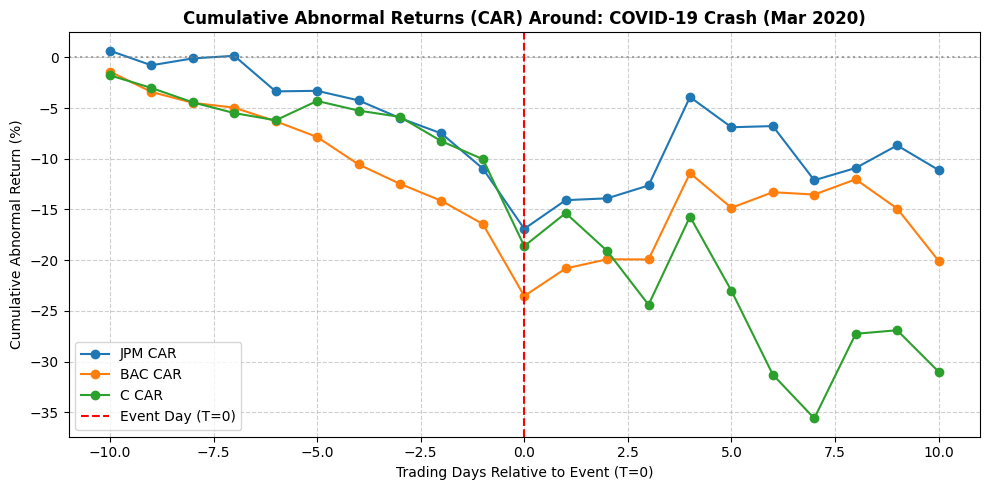

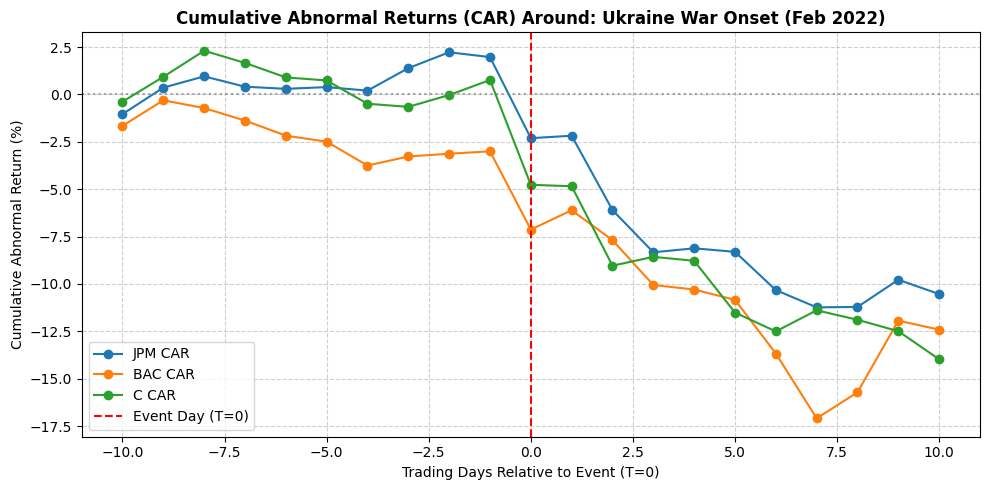


Event study analysis and CAR visualization completed successfully for all target banks.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# STEP 16: CAR (CUMULATIVE ABNORMAL RETURNS) CALCULATION & PLOTTING
"""
EVENT STUDY METHODOLOGY:
1. Benchmark: S&P 500 (^GSPC) representing normal market returns.
2. Estimation/Event Window: Extracting a ±10 trading day window around key crisis dates.
3. Abnormal Return (AR): Individual Bank Return - Benchmark Return.
4. Cumulative Abnormal Return (CAR): Rolling sum of AR across the event window.
"""

# Define crisis event dates
events = {
    "COVID-19 Crash (Mar 2020)": "2020-03-09",
    "Ukraine War Onset (Feb 2022)": "2022-02-24",
}

# Fetch price data including benchmark if not already in memory
tickers_event = ["JPM", "BAC", "C", "^GSPC"]
data_event_dict = {}

for ticker in tickers_event:
  df_t = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_t.columns, pd.MultiIndex):
    close_col = [c for c in df_t.columns if "Close" in c][0]
    data_event_dict[ticker] = df_t[close_col]
  else:
    data_event_dict[ticker] = df_t["Close"]

df_eprices = pd.DataFrame(data_event_dict).dropna()
df_ereturns = df_eprices.pct_change().dropna()

# Window configuration (10 days before and 10 days after event)
pre_window = 10
post_window = 10

for event_name, event_date_str in events.items():
  event_date = pd.to_datetime(event_date_str)

  # Find the closest trading day index
  try:
    # Attempt to get exact location. If not found, KeyError is raised.
    idx = df_ereturns.index.get_loc(event_date)
  except KeyError:
    # If event_date is not an exact match, find the nearest trading day.
    # searchsorted returns the index where `event_date` would be inserted to maintain order.
    pos = df_ereturns.index.searchsorted(event_date)

    # Handle edge cases: event_date before first entry or after last entry
    if pos == 0: # If event_date is before the first trading day
        idx = 0
    elif pos == len(df_ereturns.index):
        idx = len(df_ereturns.index) - 1
    else:
        # Compare distances to the day before and the day at `pos`
        prev_day = df_ereturns.index[pos - 1]
        next_day = df_ereturns.index[pos]
        if abs(event_date - prev_day) < abs(event_date - next_day):
            idx = pos - 1
        else:
            idx = pos

  # Determine the window around the identified event day
  # start_idx is inclusive, end_idx is inclusive
  start_idx = max(0, idx - pre_window)
  end_idx = min(len(df_ereturns) - 1, idx + post_window)

  window_returns = df_ereturns.iloc[start_idx : end_idx + 1]

  # Calculate Abnormal Returns (AR) = Bank Return - Market (S&P 500) Return
  ar_df = pd.DataFrame(index=window_returns.index)
  for bank in ["JPM", "BAC", "C"]:
    ar_df[bank] = window_returns[bank] - window_returns["^GSPC"]

  # Calculate Cumulative Abnormal Returns (CAR)
  car_df = ar_df.cumsum() * 100  # in percentage

  # Plotting CAR for the event
  plt.figure(figsize=(10, 5))

  # Calculate the relative day numbers for the x-axis
  # The event day (closest trading day to event_date) is at index `idx` in df_ereturns.
  # Its position within `window_returns` (slice of df_ereturns) is `idx - start_idx`.
  # So, the relative x-axis values should be `range(start_idx - idx, end_idx - idx + 1)`.
  relative_day_numbers = range(start_idx - idx, end_idx - idx + 1)

  for bank in ["JPM", "BAC", "C"]:
    plt.plot(
        relative_day_numbers,
        car_df[bank],
        marker="o",
        label=f"{bank} CAR",
    )

  plt.axvline(0, color="red", linestyle="--", label="Event Day (T=0)")
  plt.axhline(0, color="gray", linestyle=":", alpha=0.7)
  plt.title(
      f"Cumulative Abnormal Returns (CAR) Around: {event_name}",
      fontsize=12,
      fontweight="bold",
  )
  plt.xlabel("Trading Days Relative to Event (T=0)")
  plt.ylabel("Cumulative Abnormal Return (%)")
  plt.legend()
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.tight_layout()
  plt.show()

print(
    "\nEvent study analysis and CAR visualization completed successfully for all"
    " target banks."
)


/tmp/ipykernel_254/1660870728.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_254/1660870728.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_254/1660870728.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(


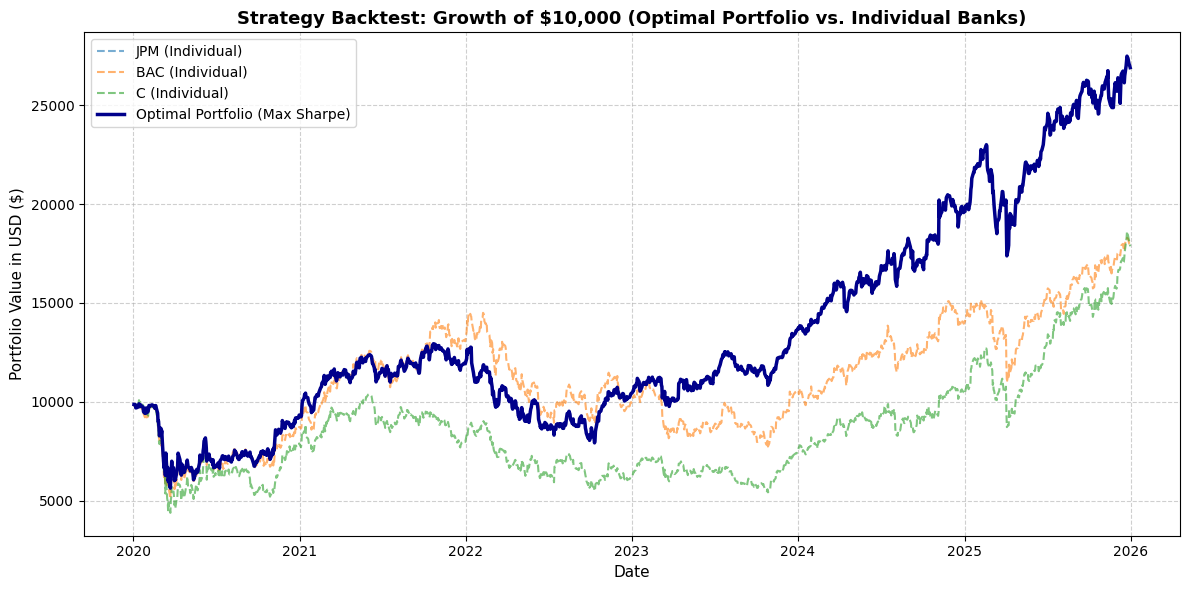

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf


# ALTERNATIVE VISUALIZATION: PORTFOLIO BACKTEST & VALUE GROWTH ($10,000)
"""
VISUALIZATION OVERVIEW:
This chart plots the cumulative growth of a $10,000 investment starting in January 2020.
It compares individual bank performance (JPM, BAC, C) against the mathematically
optimized portfolio (Max Sharpe Ratio weights) to demonstrate risk-adjusted growth over time.
"""

# Ensure we have our returns and optimal weights from the previous calculation
# (Re-running the lightweight extraction and backtest mapping)
tickers_port = ["JPM", "BAC", "C"]
data_port = {}

for ticker in tickers_port:
  df_t = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_t.columns, pd.MultiIndex):
    close_col = [c for c in df_t.columns if "Close" in c][0]
    data_port[ticker] = df_t[close_col]
  else:
    data_port[ticker] = df_t["Close"]

df_prices = pd.DataFrame(data_port).dropna()
returns = df_prices.pct_change().dropna()

# Re-calculate optimal weights using the same logic
mean_returns = returns.mean() * 252
cov_matrix = returns.cov() * 252

np.random.seed(42)
best_sharpe = -np.inf
best_weights = None

for _ in range(10000):
  weights = np.random.random(len(tickers_port))
  weights /= np.sum(weights)
  p_return = np.sum(weights * mean_returns)
  p_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
  p_sharpe = p_return / p_vol
  if p_sharpe > best_sharpe:
    best_sharpe = p_sharpe
    best_weights = weights

# Calculate cumulative growth of $10,000 for individual assets
initial_investment = 10000
cumulative_individual = (1 + returns).cumprod() * initial_investment

# Calculate cumulative growth of the Optimal Portfolio
portfolio_daily_returns = np.dot(returns, best_weights)
cumulative_portfolio = (
    pd.Series(
        (1 + portfolio_daily_returns).cumprod() * initial_investment,
        index=returns.index,
    )
)

# Plotting the Alternative Backtest Visualization
plt.figure(figsize=(12, 6))

# Plot individual stocks with dashed lighter lines
for ticker in tickers_port:
  plt.plot(
      cumulative_individual.index,
      cumulative_individual[ticker],
      linestyle="--",
      alpha=0.6,
      label=f"{ticker} (Individual)",
  )

# Plot the Optimal Portfolio as a prominent solid black/dark line
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    color="darkblue",
    linewidth=2.5,
    label="Optimal Portfolio (Max Sharpe)",
)

plt.title(
    "Strategy Backtest: Growth of $10,000 (Optimal Portfolio vs. Individual"
    " Banks)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Portfolio Value in USD ($)", fontsize=11)
plt.legend(loc="upper left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Fetching data and engineering features for ML classification model...


/tmp/ipykernel_254/3898690753.py:24: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_ml = yf.download("JPM", start="2020-01-01", end="2026-01-01", progress=False)



--- Machine Learning Model Results (JPM Direction Forecast) ---
Model Accuracy on Test Set: 53.36%

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.44      0.45       132
           1       0.58      0.61      0.59       166

    accuracy                           0.53       298
   macro avg       0.52      0.52      0.52       298
weighted avg       0.53      0.53      0.53       298



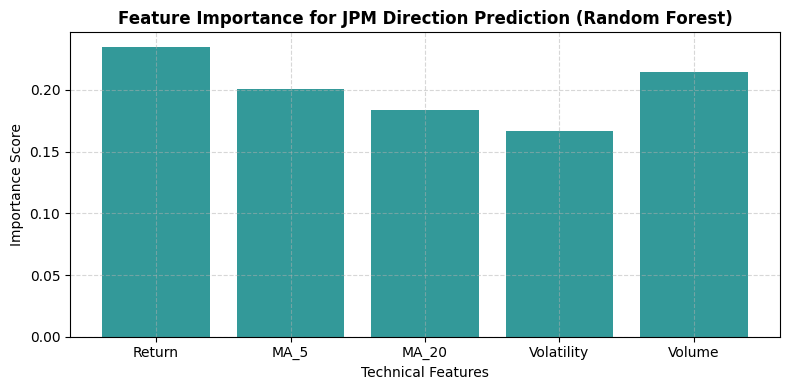

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import yfinance as yf


# STEP 18: MACHINE LEARNING PREDICTIVE MODELING (JPM DIRECTION FORECAST)
"""
MACHINE LEARNING PIPELINE OVERVIEW:
1. Feature Engineering: Create technical indicators (Moving Averages, Daily Returns, Volatility)
   derived from JPMorgan (JPM) historical stock prices.
2. Target Variable: Binary classification (1 if next day's close > today's close, else 0).
3. Model Training: Train a Random Forest Classifier using historical features.
4. Evaluation: Measure out-of-sample prediction accuracy, precision, and recall for the team repository.
"""

print("Fetching data and engineering features for ML classification model...")

# Fetch JPM data for ML pipeline
df_ml = yf.download("JPM", start="2020-01-01", end="2026-01-01", progress=False)
if isinstance(df_ml.columns, pd.MultiIndex):
  close_col = [c for c in df_ml.columns if "Close" in c][0]
  open_col = [c for c in df_ml.columns if "Open" in c][0]
  high_col = [c for c in df_ml.columns if "High" in c][0]
  low_col = [c for c in df_ml.columns if "Low" in c][0]
  vol_col = [c for c in df_ml.columns if "Volume" in c][0]
  df_ml = pd.DataFrame(
      {
          "Close": df_ml[close_col],
          "Open": df_ml[open_col],
          "High": df_ml[high_col],
          "Low": df_ml[low_col],
          "Volume": df_ml[vol_col],
      }
  )

# 1. Feature Engineering
df_ml["Return"] = df_ml["Close"].pct_change()
df_ml["MA_5"] = df_ml["Close"].rolling(window=5).mean() / df_ml["Close"] - 1
df_ml["MA_20"] = df_ml["Close"].rolling(window=20).mean() / df_ml["Close"] - 1
df_ml["Volatility"] = df_ml["Return"].rolling(window=10).std()

# Target: 1 if tomorrow's close is higher than today's close, 0 otherwise
df_ml["Target"] = (df_ml["Close"].shift(-1) > df_ml["Close"]).astype(int)

# Drop missing values resulting from rolling calculations and shift
df_ml = df_ml.dropna()

# Select features and target
features = ["Return", "MA_5", "MA_20", "Volatility", "Volume"]
X = df_ml[features]
y = df_ml["Target"]

# 2. Train-Test Split (Chronological split to prevent data leakage: 80% train, 20% test)
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 3. Model Training (Random Forest Classifier)
model = RandomForestClassifier(
    n_estimators=100, max_depth=5, random_state=42, class_weight="balanced"
)
model.fit(X_train, y_train)

# 4. Evaluation
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"\n--- Machine Learning Model Results (JPM Direction Forecast) ---")
print(f"Model Accuracy on Test Set: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Feature Importances to show which technical indicator drives the model
importances = model.feature_importances_
plt.figure(figsize=(8, 4))
plt.bar(features, importances, color="teal", alpha=0.8)
plt.title(
    "Feature Importance for JPM Direction Prediction (Random Forest)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Technical Features")
plt.ylabel("Importance Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 4.2 Correlation between Q&A sentiments and reaction in Stock Market

In [ ]:
# One row per call: FinBERT Q&A indicators + call date + market reaction
TICKER = {"BAC": "BAC", "CITI": "C", "JPM": "JPM"}
dates = calls[["bank_id", "fiscal_year", "fiscal_quarter", "call_date"]].copy()
dates["period"] = (dates["fiscal_year"].astype(str) + "Q"
                   + dates["fiscal_quarter"].astype(str))
dates["call_date"] = pd.to_datetime(dates["call_date"])
dates["ticker"] = dates["bank_id"].map(TICKER)

call_events = indicators.merge(
    dates[["bank_id", "period", "call_date", "ticker"]],
    on=["bank_id", "period"], how="left", validate="one_to_one")
assert len(call_events) == 60 and call_events["call_date"].notna().all()
print("call dates not trading days:",
      (~call_events["call_date"].isin(ar.index)).sum())

# Abnormal return on the call day, and cumulative over [0, +1], in %
pairs = list(zip(call_events["ticker"], call_events["call_date"]))
call_events["ar_0"] = [car(ar[t], [d], pre=0, post=0).iloc[0, 1] * 100
                       for t, d in pairs]
call_events["car_0_1"] = [car(ar[t], [d], pre=0, post=1).iloc[0, 1] * 100
                          for t, d in pairs]

display(call_events.groupby("bank_id")[["ar_0", "car_0_1"]]
        .agg(["mean", "std", "min", "max"]).round(2))
top = call_events["car_0_1"].abs().sort_values(ascending=False).index
display(call_events.loc[top, ["bank_id", "period", "call_date",
                              "ar_0", "car_0_1"]].head(6).round(2))

call dates not trading days: 0


ar_0                    car_0_1                   
         mean   std   min    max    mean   std   min    max
bank_id                                                    
BAC      0.89  2.77 -4.32   4.70    1.18  3.22 -3.73   6.26
CITI     1.02  3.79 -4.38  11.70    1.26  3.78 -3.16  12.70
JPM     -0.56  3.50 -6.19   7.74   -0.49  3.81 -8.96   8.17

,bank_id,period,call_date,ar_0,car_0_1
25,CITI,2022Q2,2022-07-15,11.70,12.70
43,JPM,2021Q4,2022-01-14,-6.19,-8.96
48,JPM,2023Q1,2023-04-14,7.74,8.17
9,BAC,2023Q2,2023-07-18,3.71,6.26
6,BAC,2022Q3,2022-10-17,3.62,6.25
46,JPM,2022Q3,2022-10-14,3.80,5.78


Date to date there is no correlation.

In [ ]:
# TRIANGULATION STEP 1: one row per call = management tone + share-price return over the quarter it discusses
TICKER_TO_BANK = {"JPM": "JPM", "BAC": "BAC", "C": "CITI"}

# 1) Tone per call: management answers in the Q&A, courtesy turns excluded (qa_check comes from the robustness cell)
tone_source = qa_check[(~qa_check["is_courtesy"]) & (qa_check["channel"] == "management_answer")]

call_tone = (tone_source
             .assign(quarter=tone_source["call_id"].str.extract(r"_(\d{4}Q[1-4])_")[0])
             .groupby(["bank_id", "quarter"])["finbert_net"].mean()
             .rename("tone")
             .reset_index())

# 2) Share-price return over each calendar quarter, in % (last close of the quarter vs last close of the previous quarter)
qtr_close = df_close.groupby(df_close.index.to_period("Q")).last()
qtr_return = (qtr_close.pct_change() * 100).rename(columns=TICKER_TO_BANK)
qtr_return.index = qtr_return.index.astype(str)
qtr_return_long = (qtr_return.rename_axis("quarter").reset_index()
                   .melt(id_vars="quarter", var_name="bank_id", value_name="qtr_return"))

# 3) Join the two: one row per call
tri = call_tone.merge(qtr_return_long, on=["bank_id", "quarter"], how="left", validate="one_to_one")
assert len(tri) == 60, f"expected 60 calls, got {len(tri)}"
assert tri["qtr_return"].notna().all(), "some calls have no matching quarter return - check the quarter labels"

# 4) Quarters where tone and price point in opposite directions
grp = tri.groupby("bank_id")["tone"]
tri["tone_z"] = (tri["tone"] - grp.transform("mean")) / grp.transform("std")
tri["price"] = np.where(tri["qtr_return"] >= 0, "rose", "fell")

mismatch = tri[((tri["tone_z"] >= 1) & (tri["qtr_return"] < 0)) |
               ((tri["tone_z"] <= -1) & (tri["qtr_return"] > 0))]

# 5) Do tone and quarterly return move together? (20 calls per bank - indicative only)
corr = tri.groupby("bank_id")[["tone", "qtr_return"]].corr().xs("tone", level=1)["qtr_return"]

print("Correlation between call tone and the quarter's share-price return:")
display(corr.round(2).rename("correlation").to_frame())
print(f"\nQuarters with unusual tone pointing the opposite way to the price ({len(mismatch)} of {len(tri)}):")
display(mismatch.sort_values(["bank_id", "quarter"]).round(2))

Correlation between call tone and the quarter's share-price return:


,correlation
bank_id,
BAC,0.17
CITI,-0.23
JPM,0.14



Quarters with unusual tone pointing the opposite way to the price (6 of 60):


,bank_id,quarter,tone,qtr_return,tone_z,price
1,BAC,2021Q2,-0.03,7.01,-1.96,rose
31,CITI,2023Q4,0.07,26.69,-2.59,rose
33,CITI,2024Q2,0.12,1.22,-1.70,rose
43,JPM,2021Q4,0.09,-2.68,1.33,fell
47,JPM,2022Q4,-0.03,29.47,-1.14,rose
56,JPM,2025Q1,-0.05,2.86,-1.54,rose


The correlations are weak and cannot be supported only with the stock market.

- BAC	+0.17
- CITI	−0.23
- JPM	+0.14

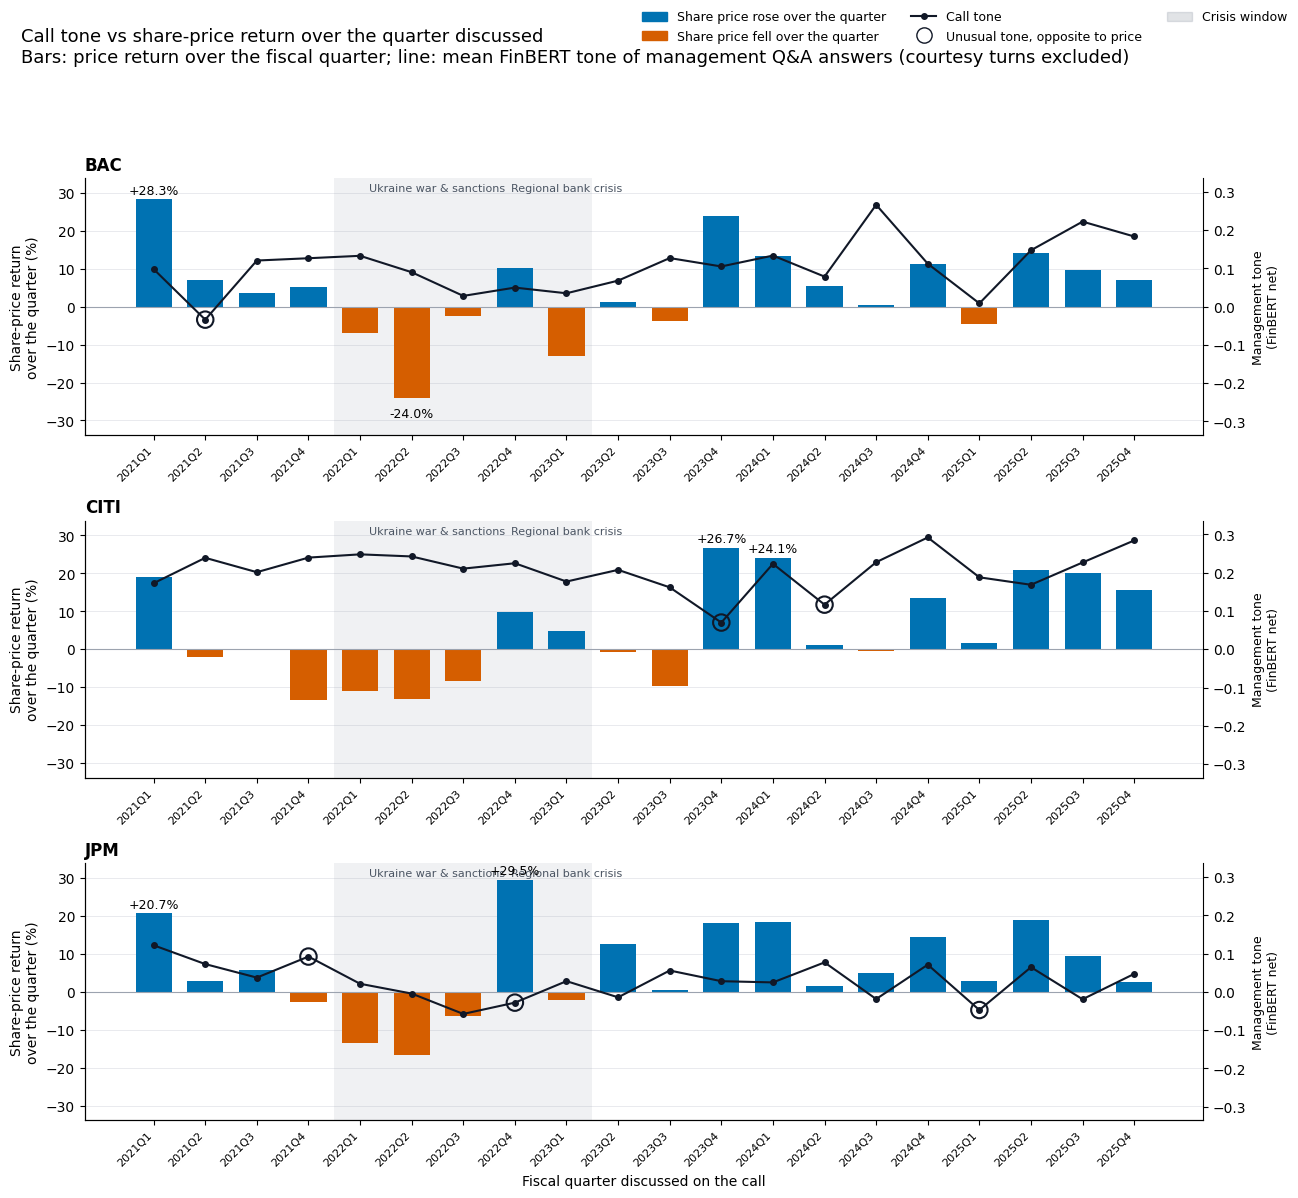

In [ ]:
# Call tone vs share-price return over the quarter discussed: one panel per bank same scale for all banks
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

periods = sorted(tri["quarter"].unique())
x = np.arange(len(periods))
banks = ["BAC", "CITI", "JPM"]
POS, NEG = "#0072B2", "#D55E00"
TONE = "#111827"

CRISES = {"Ukraine war & sanctions": ["2022Q1", "2022Q2", "2022Q3", "2022Q4"],
          "Regional bank crisis": ["2023Q1"]}

ret_lim = tri["qtr_return"].abs().max() * 1.15
tone_lim = tri["tone"].abs().max() * 1.15

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharey=True)
for ax, bank in zip(axes, banks):
    d = tri[tri["bank_id"] == bank].set_index("quarter").reindex(periods)
    s = d["qtr_return"]

    # shade the crisis windows
    for name, qs in CRISES.items():
        idx = [periods.index(q) for q in qs if q in periods]
        if idx:
            ax.axvspan(min(idx) - 0.5, max(idx) + 0.5, color="#9ca3af", alpha=0.15, lw=0)
            ax.text((min(idx) + max(idx)) / 2, 0.98, name, transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=8, color="#4b5563")

    ax.bar(x, s.values, width=0.7, color=np.where(s >= 0, POS, NEG))
    ax.axhline(0, color="#9ca3af", lw=0.8)
    for i in s.abs().nlargest(2).index:
        xi, v = periods.index(i), s[i]
        ax.annotate(f"{v:+.1f}%", (xi, v), ha="center", fontsize=9,
                    xytext=(0, 4 if v > 0 else -14), textcoords="offset points")
    ax.set_title(bank, loc="left", fontsize=12, fontweight="bold")
    ax.set_ylabel("Share-price return\nover the quarter (%)")
    ax.set_ylim(-ret_lim, ret_lim)
    ax.set_xticks(x)
    ax.set_xticklabels(periods, rotation=45, ha="right", fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e7eb", lw=0.6)
    ax.set_axisbelow(True)
    ax2 = ax.twinx()
    ax2.plot(x, d["tone"].values, color=TONE, marker="o", ms=4, lw=1.5)
    m = d.index.isin(mismatch.loc[mismatch["bank_id"] == bank, "quarter"])
    ax2.scatter(x[m], d["tone"].values[m], s=140, facecolors="none", edgecolors=TONE, linewidths=1.5, zorder=3)
    ax2.set_ylim(-tone_lim, tone_lim)
    ax2.set_ylabel("Management tone\n(FinBERT net)", fontsize=9)
    ax2.spines[["top"]].set_visible(False)

axes[-1].set_xlabel("Fiscal quarter discussed on the call")
fig.legend(handles=[Patch(color=POS, label="Share price rose over the quarter"),
                    Patch(color=NEG, label="Share price fell over the quarter"),
                    Line2D([], [], color=TONE, marker="o", ms=4, label="Call tone"),
                    Line2D([], [], color=TONE, marker="o", ms=11, lw=0, markerfacecolor="none",
                           label="Unusual tone, opposite to price"),
                    Patch(color="#9ca3af", alpha=0.3, label="Crisis window")],
           loc="upper right", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Call tone vs share-price return over the quarter discussed\n"
             "Bars: price return over the fiscal quarter; line: mean FinBERT tone of management "
             "Q&A answers (courtesy turns excluded)", fontsize=13, x=0.02, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

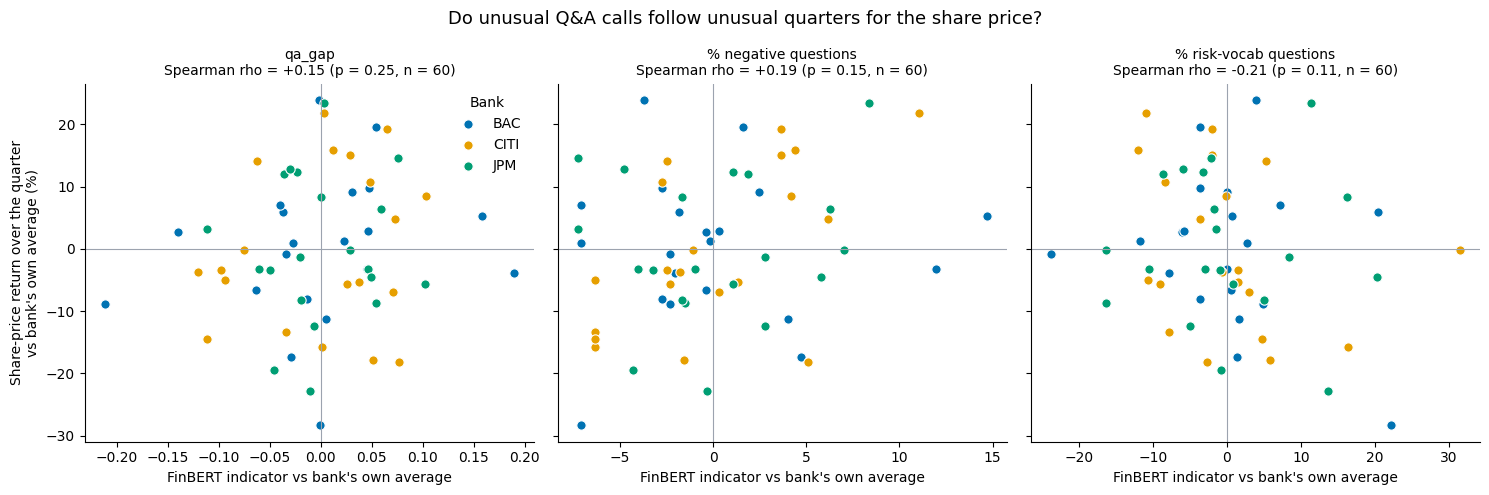

In [ ]:
from scipy.stats import spearmanr

ind_cols = ["qa_gap", "% negative questions", "% risk-vocab questions"]
BANK_COL = {"BAC": "#0072B2", "CITI": "#E69F00", "JPM": "#009E73"}

# CHANGED: add each call's quarterly share-price return (from tri) to the call-level indicators
within = call_events.merge(tri[["bank_id", "quarter", "qtr_return"]],
                           left_on=["bank_id", "period"], right_on=["bank_id", "quarter"],
                           how="left", validate="one_to_one")
assert len(within) == 60 and within["qtr_return"].notna().all(), "quarter labels did not match"

# Each value relative to that bank's own average (as in cell 64)
for c in ind_cols + ["qtr_return"]:
    within[c] = within[c] - within.groupby("bank_id")[c].transform("mean")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, c in zip(axes, ind_cols):
    for bank, g in within.groupby("bank_id"):
        ax.scatter(g[c], g["qtr_return"], s=45, color=BANK_COL[bank],
                   label=bank, edgecolor="white", linewidth=0.8)
    rho, p = spearmanr(within[c], within["qtr_return"])
    ax.set_title(f"{c}\nSpearman rho = {rho:+.2f} (p = {p:.2f}, n = 60)",
                 fontsize=10)
    ax.axhline(0, color="#9ca3af", lw=0.8)
    ax.axvline(0, color="#9ca3af", lw=0.8)
    ax.set_xlabel("FinBERT indicator vs bank's own average")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Share-price return over the quarter\n"
                   "vs bank's own average (%)")
axes[0].legend(title="Bank", frameon=False)
fig.suptitle("Do unusual Q&A calls follow unusual quarters for the share price?",
             fontsize=13)
plt.tight_layout()
plt.show()

Each earnings call reviews the results of the preceding quarter. To align transcript analysis with market data, each call's FinBERT Q&A indicators are compared to the bank's share-price return for the same period. If unusual Q&A calls align with unusual quarters, the transcript may reflect developments already priced in by investors.

Across 60 calls, management Q&A tone (excluding courtesy turns) showed only a weak correlation with quarterly share-price returns: +0.17 at BAC, −0.23 at Citi, and +0.14 at JPM. None of the three the KPIs was significantly associated with quarterly returns.


Caveats:
- Quarterly returns are not market-adjusted, so the three banks move together in each quarter, and the 60 points are not fully independent;
- Three indicators were tested, which raises the chance of a false positive;
- The comparison assumes fiscal quarters match calendar quarters (to be confirmed in the banks' reports).

# 5.0: A Comparative Study of Sentiment Analysis: FinBERT vs LLama-3.1

Over the past decade, LLMs such as BERT (Devlin et al., 2019), FinBERT (Araci, 2019), RoBERTa (Liu et al., 2019), GPT (Brown et al., 2020), OPT (Zhang et al., 2022) and LLaMA (Touvron et al., 2023) have consistenly proved superior over the traditional lexicon-based sentiment models. Among these, FinBERT, a BERT base model fine-tuned on financial text, is particularly popular due to its relatively small size (110 million parameters).

However, FinBERT has known limitations such as insensitivity to numerical values as well as deteoriorating performace with sentence complexity. Put simply, FinBERT is adept at detecting tone and language but lacks the reasoning to understand potential impact on stock markets.

Thus, for a potential analyst who wants to identify key themes, changing expectations and the drivers of a bank's performance, FinBERT may prove inadequate. Consequently, for a temporal RAG pipeline to benefit from FinBERT's speed, its performance needs to be improved.

A significant improvement in sentiment classification performance is typically achieved through building upon FinBERT's architecture via hybridisation with an LLM. Since the hybridisation approach involves targeted fine-tuning, for a set of earnings call transcripts that are unlabelled we instead propose an agentic flow that still utilises zero-shot classification such as the one below:

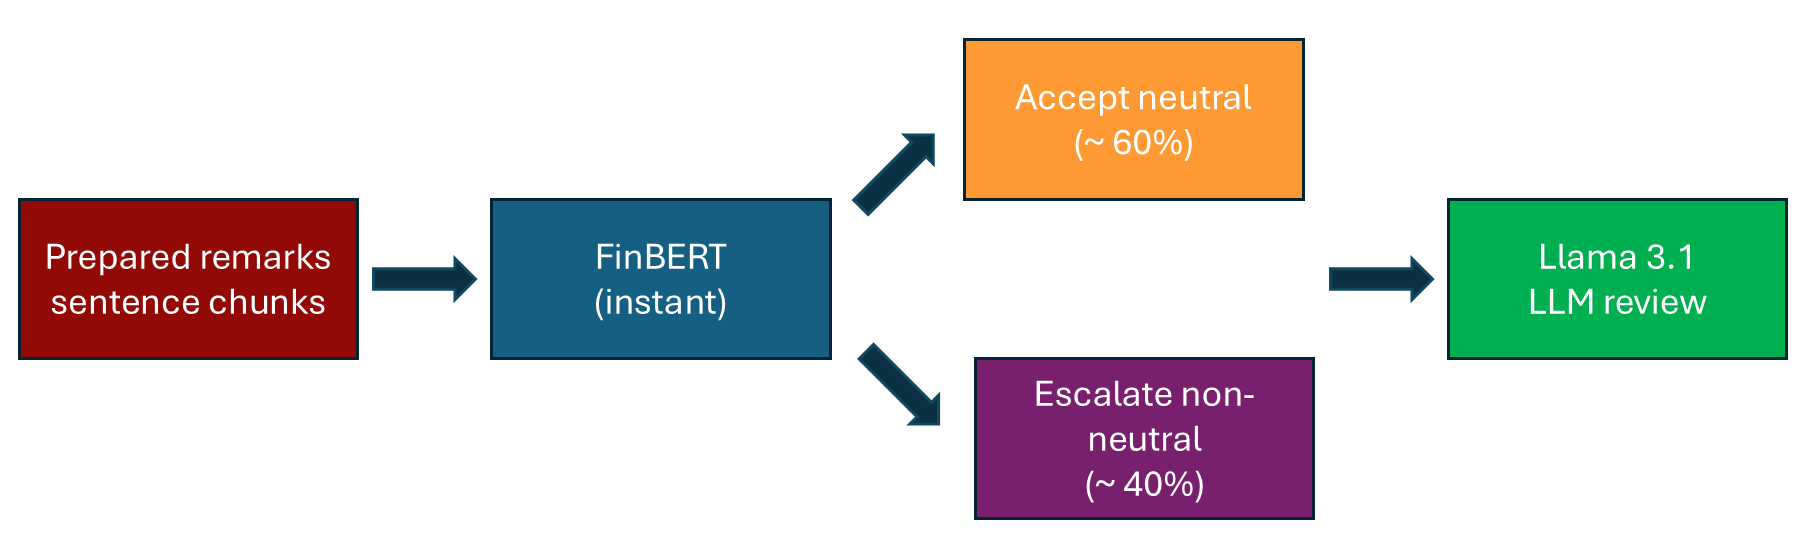

Note the flow illustrated above is based on FinBERT showing the highest agreement level for neutral statements during domain training (Araci, 2019).

Before a RAG system can be developed, however, the performance of FinBERT needs to be analysed against the LLM, in this case, Llama 3.1 8B Instruct. Therefore, the current study focusses on the prepared remarks section of the quarterly earnings call transcripts, to compare and contrast performance of FinBERT against the Llama 3.1 model.

The outline of the study is as follows:

* First, the prepared remarks section is segregated to account for the nuances between CFO and CEO remarks.

* Next, the prepared remarks by each speaker is processed into 5-sentence chunks to achieve granularity without losing context.

* A zero-shot sentiment classification is performed by the (static) Llama 3.1 model while recording its reasoning behind each label.

* The LLM is also used to extract the primary topic discussed in a given 5-sentence chunk.

* The LLM classification is then followed by zero-shot classification using FinBERT where the confidence score for a given label is also recorded.

* Finally, the results are visualised and compared.


## 5.1.1 Import relevant libraries.

In [ ]:
!pip install pandas PyArrow

In [ ]:
import os
from google.colab import files
from pathlib import Path
import pandas as pd
import numpy as np
import random
import tensorflow as tf
import re
import nltk
from nltk.tokenize import sent_tokenize
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from collections import Counter
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.cluster import AgglomerativeClustering

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

**Hugging Face & FinBERT Transformer Pipelines**

In [ ]:
!pip install -q transformers accelerate bitsandbytes huggingface_hub pipeline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 62.0 MB/s eta 0:00:00


In [ ]:
import torch
from google.colab import userdata
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, BitsAndBytesConfig, pipeline
from transformers import GenerationConfig
from sentence_transformers import SentenceTransformer
from datasets import Dataset

In [ ]:
# Authenticate Hugging Face
from google.colab import userdata
from huggingface_hub import login
try:
    huggingface_token = userdata.get("HF_TOKEN")
except userdata.SecretNotFoundError:
    raise RuntimeError("Add your Hugging Face token to Colab Secrets as HF_TOKEN and enable notebook access before running this cell.")

login(token=huggingface_token)

**Ensuring reproducability and clearing cache:**

In [ ]:
# Function to control stochastic behaviour when model tuning
def set_random_seed(seed_val):
   # Set the `PYTHONHASHSEED` environment variable at a fixed value
    os.environ['PYTHONHASHSEED']=str(seed_val)
    # Set the `python` built-in pseudo-random generator at a fixed value
    np.random.seed(seed_val)
    # Set the `numpy` pseudo-random generator at a fixed value
    random.seed(seed_val)
    # Set the `tensorflow` pseudo-random generator at a fixed value
    tf.random.set_seed(seed_val)

In [ ]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.empty_cache()

In [ ]:
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
Device Name: NVIDIA A100-SXM4-40GB


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
set_random_seed(42)

## 5.1.2 Load the CSV input file.

The CSV file has been created using a combination of the original parquet files output from the main earnings call transcript parser script. The parquet files has been cross-referenced, combined and pre-processed to label each remark excerpt, corresponding to a given management statement, either as CFO or CEO, to produce a unique research view.

The preprocessing steps involved in creating the input CSV file have been excluded from the current notebook for concision.

In [ ]:
prepared_remarks_combined_df = pd.read_csv("prepared_remarks_compact_input.csv")

In [ ]:
print(prepared_remarks_combined_df.shape)
prepared_remarks_combined_df.info()

(115, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115 entries, 0 to 114
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   document_id    115 non-null    object
 1   call_id        115 non-null    object
 2   bank           115 non-null    object
 3   year           115 non-null    int64 
 4   quarter        115 non-null    object
 5   fiscal_period  115 non-null    object
 6   speaker_name   115 non-null    object
 7   speaker_role   115 non-null    object
 8   speaker_turn   115 non-null    int64 
 9   verbatim_text  115 non-null    object
dtypes: int64(2), object(8)
memory usage: 9.1+ KB


In [ ]:
prepared_remarks_combined_df

,document_id,call_id,bank,year,quarter,fiscal_period,speaker_name,speaker_role,speaker_turn,verbatim_text
0,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Paul Donofrio,CFO,4,"Thanks, Brian. Good morning, and hello, everyo..."
1,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Brian Moynihan,CEO,3,"Thank you, Lee, and thank all of you for joini..."
2,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Brian Moynihan,CEO,3,Good morning. And thank all of you for joining...
3,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Paul Donofrio,CFO,4,"Thanks, Brian. Hello, everyone. I'm starting o..."
4,doc_abc71b3bf815c8a1,BAC_2021Q3_earnings_call,BAC,2021,Q3,2021-Q3,Brian Moynihan,CEO,3,"Thank you, Lee (ph). And good morning to all, ..."
...,...,...,...,...,...,...,...,...,...,...
110,doc_671c70b3c9d6bc3d,JPM_2025Q1_earnings_call,JPM,2025,Q1,2025-Q1,Jeremy Barnum,CFO,2,"Thank you and good morning, everyone. Starting..."
111,doc_720ee28f1fa395e2,JPM_2025Q2_earnings_call,JPM,2025,Q2,2025-Q2,Jeremy Barnum,CFO,2,"Thank you very much and good morning, everyone..."
112,doc_4f2f83015473a1b4,JPM_2025Q3_earnings_call,JPM,2025,Q3,2025-Q3,Jeremy Barnum,CFO,2,"Thank you, and good morning, everyone. Let me ..."
113,doc_40b732e278c14d17,JPM_2025Q4_earnings_call,JPM,2025,Q4,2025-Q4,Jeremy Barnum,CFO,3,"At the top of the page, we provided a reconcil..."


Note the bank labels stand for:

* BAC: Bank of America Corporation
* CITI: Citigroup
* JPM: JPMorgan Chase & Co

## 5.1.3 For each executive remark, count the number of sentences and figures quoted.

In [ ]:
# Define a financial pattern for dollars ($10, $5.4B) and percentages (12%, 5 percent)
fin_pattern = r'(?:\$\d+(?:,\d{3})*(?:\.\d+)?(?:\s?[bB]illion|\s?[mM]illion)?|\b\d+(?:\.\d+)?\s?(?:%|percent)\b)'
# Count the number of financial metrics/figures quoted by the management excluding dates
prepared_remarks_combined_df['figure_count'] = prepared_remarks_combined_df["verbatim_text"].apply(lambda x: len(re.findall(fin_pattern, str(x))))

# Count sentences using NLTK tokenization
prepared_remarks_combined_df['sentence_count'] = prepared_remarks_combined_df["verbatim_text"].apply(lambda x: len(sent_tokenize(str(x))) if pd.notnull(x) else 0)


## 5.1.4 Preprocessing the prepared remarks excerpts.

Traditional preprocessing approaches like removing stop words or lowercasing text is likely to worsen a transformer-based model's performance, for most LLMs naturally rely on the exact context as well as punctuation to determine sentiment accurately. Therefore, it is adequate to remove potential HTML tags.

In [ ]:
# Strip potential HTML tags from the column
prepared_remarks_combined_df['cleaned_verbatim_text']=prepared_remarks_combined_df["verbatim_text"].str.replace(r'<[^<>]*>', '', regex=True)

In [ ]:
prepared_remarks_combined_df.head()

,document_id,call_id,bank,year,quarter,fiscal_period,speaker_name,speaker_role,speaker_turn,verbatim_text,figure_count,sentence_count,cleaned_verbatim_text
0,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Paul Donofrio,CFO,4,"Thanks, Brian. Good morning, and hello, everyo...",66,163,"Thanks, Brian. Good morning, and hello, everyo..."
1,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Brian Moynihan,CEO,3,"Thank you, Lee, and thank all of you for joini...",0,11,"Thank you, Lee, and thank all of you for joini..."
2,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Brian Moynihan,CEO,3,Good morning. And thank all of you for joining...,14,108,Good morning. And thank all of you for joining...
3,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Paul Donofrio,CFO,4,"Thanks, Brian. Hello, everyone. I'm starting o...",25,174,"Thanks, Brian. Hello, everyone. I'm starting o..."
4,doc_abc71b3bf815c8a1,BAC_2021Q3_earnings_call,BAC,2021,Q3,2021-Q3,Brian Moynihan,CEO,3,"Thank you, Lee (ph). And good morning to all, ...",15,104,"Thank you, Lee (ph). And good morning to all, ..."


## 5.2.1 EDA: How many speaking turns CEO and CFO takes over the years? How many figures (e.g. net income, total revenue, operating expenses) does the CFO disclose over the quarters?  

The first impressions of the transcript data suggests there is an inbalance in the number of appearances between a CEO and a CFO which is worth noting.

In [ ]:
# Extract number of appearances
executive_appearance_counts=prepared_remarks_combined_df.groupby(['bank','year'])["speaker_role"].value_counts()


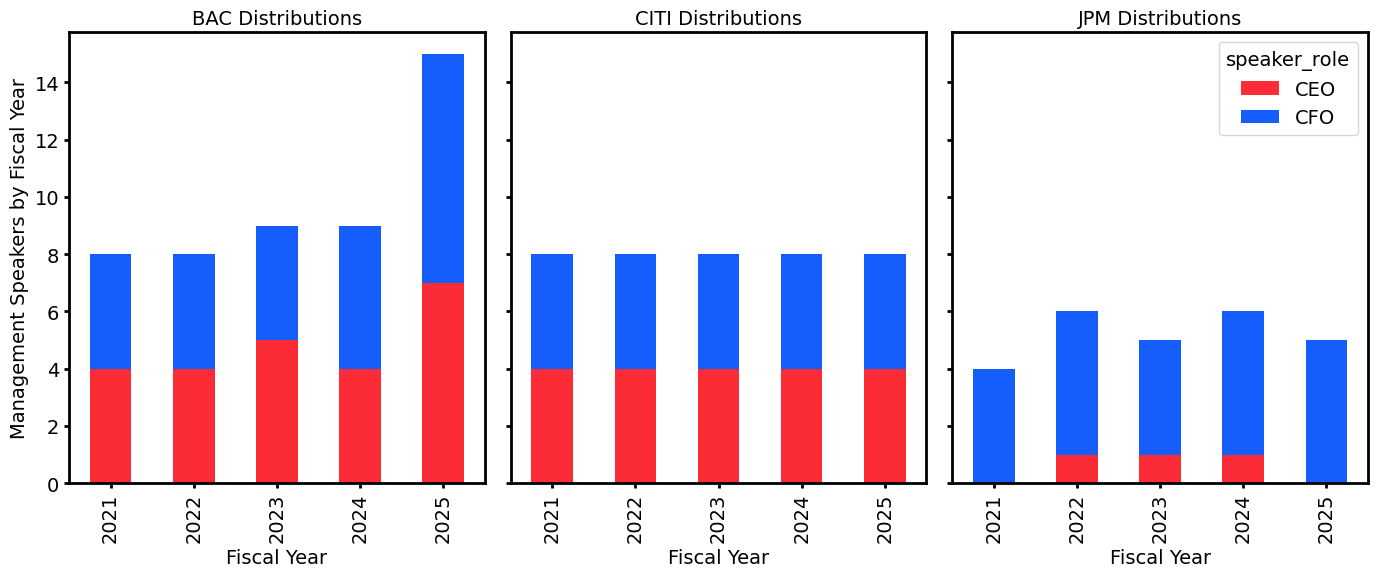

In [ ]:
# Compare Attendance : CFO vs CEO
fig, axes = plt.subplots(1, 3, figsize=(14,6),sharey=True)

speaker_colors = {'CFO': '#155DFC','CEO': '#FB2C36'}
titles=['BAC Distributions', 'CITI Distributions','JPM Distributions']
# Fill missing combinations with 0
BAC_appearance_counts=executive_appearance_counts.BAC.unstack(fill_value=0)
CITI_appearance_counts=executive_appearance_counts.CITI.unstack(fill_value=0)
JPM_appearance_counts=executive_appearance_counts.JPM.unstack(fill_value=0)

# Plot as a stacked or grouped bar chart
BAC_appearance_counts.plot(kind='bar', stacked=True, color=speaker_colors,ax=axes[0])
CITI_appearance_counts.plot(kind='bar', stacked=True,color=speaker_colors,ax=axes[1])
JPM_appearance_counts.plot(kind='bar', stacked=True, color=speaker_colors,ax=axes[2])

for i in range(3):
  axes[i].set_xlabel('Fiscal Year',fontsize=14)
  axes[i].set_title(titles[i],fontsize=14)
  axes[i].set_ylabel('Management Speakers by Fiscal Year',fontsize=14)
  axes[i].tick_params(width=2)
  for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)

# plt.ylabel('Management Distributions by Fiscal Year')
plt.tight_layout()
# Remove the unnecessary legends
axes[0].get_legend().remove()
axes[1].get_legend().remove()
plt.savefig('SpeakerDists.svg')
plt.show()

The histogram plots suggests the inbalance is the most extereme for JPMorgan. In contrast, the Citigroup appears to have an exceptionally well balance between the remarks made by the CEOs and CFOs. The presence of a balanced speaking turns between the two executives is also evident in the case of Bank of America.

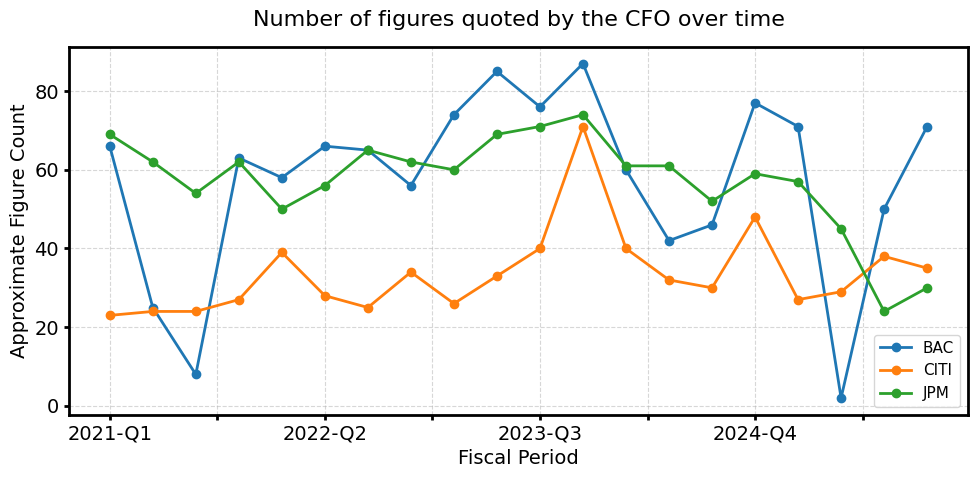

In [ ]:
# Inspect the number of figures quoted by a CFO over the years

# Filter for Speaker Role
prepared_remarks_combined_CFO = (prepared_remarks_combined_df[prepared_remarks_combined_df['speaker_role']=='CFO']
                               .groupby(['bank','fiscal_period'])['figure_count']
                               .sum())
# BAC CFO
BAC_fig_counts_CFO = prepared_remarks_combined_CFO.BAC
# CITI CFO
CITI_fig_counts_CFO = prepared_remarks_combined_CFO.CITI
# JPM CFO
JPM_fig_counts_CFO = prepared_remarks_combined_CFO.JPM

# Plots
plt.figure(figsize=(10, 5))
BAC_fig_counts_CFO.plot(kind='line', marker='o',linewidth=2, label='BAC')
CITI_fig_counts_CFO.plot(kind='line', marker='o', linewidth=2,label='CITI')
JPM_fig_counts_CFO.plot(kind='line', marker='o', linewidth=2,label='JPM')
# Axes Labels
plt.title('Number of figures quoted by the CFO over time',fontsize=16,pad=15)
plt.xlabel('Fiscal Period',fontsize=14)
plt.ylabel('Approximate Figure Count',fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)  # a subtle background grid for quarter tracking
plt.tight_layout()

# Axes appearance
axes = plt.gca()
# current_ylim = axes.get_ylim()
# axes.set_ylim(current_ylim[0], current_ylim[1] * 1.3
axes.tick_params(width=2)
# Change spine (axis line) thickness
for edge in ['top', 'bottom', 'left', 'right']:
    axes.spines[edge].set_linewidth(2)
# plt.savefig(filename)
plt.legend(loc='lower right', fontsize=11)
plt.savefig('FiguresQuoted.svg')
plt.show()

Across all 3 banks, there are notable fluctions between the number of figures a CFO quotes over the fiscal quarters. While the fluctuations does not seem to present with a seasonal pattern, the trends may be used to asses whether there are overlaps between the periods where the CFO sentiment becomes increasingly negative and those where less figures are quoted.

## 5.2.2 Process remarks text into chunks of 5 sentences.

* Chunking allows the LLMs to evaluate the sentiment of individual, localized statement in a more nuanced way.
* Moroever, dissecting the large prepared remarks excerpts, that are multiple pages long at times, into smaller segments ensures that no data, financial metrics, or key sentiment indicators are lost or ignored.
* Most importantly, it by-passes strict truncation limits for the context window:

For instance, FinBERT has a hard maximum context window of 512 tokens - the max size of Bert Token. While this is on the order of 128,000 tokens for the Llama model, it is important to capture nuance and ensure a direct comparison such that we can track the reasoning behind the classifications made by Llama.

In [ ]:
# Helper function to group text into chunks of 5 sentences
def chunk_text(text, chunk_size=5):
    if not isinstance(text, str):
        return []

    # Split text into individual sentences
    sentences = nltk.sent_tokenize(text)

    # Group sentences into blocks of 5 and rejoin them into strings
    chunks = [
        " ".join(sentences[i:i + chunk_size])
        for i in range(0, len(sentences), chunk_size)
    ]
    return chunks

The chosen sentence cluster size is 5 which is an odd number and can help sway the sentiment towards a more definitive positive or negative, after assessing each sentence (i.e. help with the generation of logit probabilities). Moreover, we can more easily track the decisions made by the Llama model, especially when it comes to neutral labels.

In [ ]:
# Create a temporary column containing the list of chunks
prepared_remarks_combined_df['sentence_chunks'] = prepared_remarks_combined_df['cleaned_verbatim_text'].apply(lambda x: chunk_text(x, chunk_size=5))


In [ ]:
# Explode the rows
prepared_remarks_chunked_df = prepared_remarks_combined_df.explode('sentence_chunks').reset_index(drop=True)

In [ ]:
# Track the sequence of chunks per conversation
prepared_remarks_chunked_df ['chunk_index'] = prepared_remarks_chunked_df.groupby(['call_id','speaker_role']).cumcount() + 1

## 5.3.1 The LLM pipeline set-up and labelling.

The chosen model is the **Llama 3.1 8B Instruct** developed by Meta (arXiv:2407.21783 [cs.AI]). It is an auto-regressive language model that uses an optimized transformer architecture and has been tuned using reinforcement learning with human feedback (RLHF) to align with human preferences.

Since the sentence chunks are extracted from the unlabelled prepared remarks section of the earnings call transcripts, a 'RLHF-trained' model helps brdige the gap between zero-shot classificaton and supervised learning which would realy on domain expert labelling.

Another advantage of the Llama 3.1 8B Instruct model is that it can be configured with 4-bit quantization to reduce memory usage.

The straight forward Hugging Face pipeline set-up which allows batch processing is another bonus that helps with practicality.

In [ ]:
# Load the Hugging Face Pipeline
hf_token = userdata.get('HF_TOKEN')

# Configure 4-bit quantization
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

model_id = "meta-llama/Llama-3.1-8B-Instruct"

# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(model_id, token=hf_token)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quantization_config,
    device_map="auto",
    token=hf_token
)

# Clear inherited hub configurations to supress future warnings
model.generation_config.temperature = None  # Removes the default temperature
model.generation_config.top_p = None        # Removes the default top_p
model.generation_config.max_length = None   # Prevents legacy length alerts

# Initialize text generation pipeline cleanly
llama_pipeline = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
)


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

In [ ]:
# Function to batch extract sentiment using an LLM pipeline

def batch_analyze_earnings_llm(dataset, text_column, batch_size=8):
    """
    Processes the entire dataframe column efficiently in batches on the GPU.
    """
    def sentiment_generator():
        for row in dataset:
            yield [
                {"role": "system", "content": (
                    "You are an expert financial analyst. Analyze the following earnings call transcript excerpt. "
                    "Determine the overall sentiment (Positive, Negative, or Neutral) and provide a short one-sentence rationale highlighting key financial drivers mentioned. "
                    "Format your output exactly as:\nSentiment: [Sentiment]\nRationale: [Your rationale]"
                )},
                {"role": "user", "content": f"Transcript Excerpt:\n\"\"\"{row[text_column]}\"\"\""}
            ]

    # Define the pad token ID, for the pipeline to batch sequences together:
    # ======================================================
    # Grab just the primary integer out of the Llama 3 multiple-EOS list
    if isinstance(llama_pipeline.model.config.eos_token_id, list):
        primary_eos_id = llama_pipeline.model.config.eos_token_id[0]
    else:
        primary_eos_id = llama_pipeline.model.config.eos_token_id
    # Override properties using a single integer value
    llama_pipeline.tokenizer._special_tokens_map["pad_token"] = llama_pipeline.tokenizer.eos_token
    llama_pipeline.tokenizer.init_kwargs["pad_token"] = llama_pipeline.tokenizer.eos_token

    # Inject the single integer ID to satisfy the strict configuration dataclass
    llama_pipeline.model.config.pad_token_id = primary_eos_id
    llama_pipeline.tokenizer.pad_token_id = primary_eos_id


    # Create a clean Generation Configuration to prevent parameter conflicts
    generation_config = GenerationConfig(
        max_new_tokens=150,
        do_sample=False,      # Enables greedy decoding
        max_length=None,      # Wipes the default legacy length limitation
        # Note: 'temperature' is omitted entirely since do_sample=False
    )

    # Run pipeline in parallel batches
    pipeline_outputs = llama_pipeline(
        sentiment_generator(),
        batch_size=batch_size,
        generation_config=generation_config,
        clean_up_tokenization_spaces=False
    )

    return [out[0]["generated_text"] for out in pipeline_outputs]


In [ ]:
# For batch processing convert to Hugging Face datasets
prepared_remarks_hf_dataset = Dataset.from_pandas(prepared_remarks_chunked_df[["sentence_chunks"]])


In [ ]:
prepared_remarks_hf_dataset


Dataset({
    features: ['sentence_chunks'],
    num_rows: 2268
})

In [ ]:
# Batch process the data set
prepared_remarks_llm_output=batch_analyze_earnings_llm(prepared_remarks_hf_dataset,'sentence_chunks', batch_size=8)

In [ ]:
# Parse the outputs using regex in a list comprehension
def llm_output_parser(output):
  sentiments = []
  reasonings = []

  for message_list in output:
      # Extract the raw string content from the final assistant message
      if isinstance(message_list, list) and len(message_list) > 0:
          raw_text = message_list[-1]["content"]
      else:
          raw_text = str(message_list) # Fallback just in case

      # Run regex searches on the actual string text
      sentiment_match = re.search(r"Sentiment:\s*(Positive|Negative|Neutral)", raw_text, re.IGNORECASE)
      rationale_match = re.search(r"Rationale:\s*(.*)", raw_text, re.IGNORECASE)

      sentiments.append(sentiment_match.group(1).strip() if sentiment_match else "Unknown")
      reasonings.append(rationale_match.group(1).strip() if rationale_match else raw_text.strip())

  return sentiments, reasonings


Assign the final parsed lists back to the prepared remarks data frame:

In [ ]:
# The LLM labels and reasoning output
prepared_remarks_chunked_df['llm_sentiment'] = llm_output_parser(prepared_remarks_llm_output)[0]
prepared_remarks_chunked_df['llm_reasoning'] = llm_output_parser(prepared_remarks_llm_output)[1]

## 5.3.2 Topic Extraction with the Llama 3.1 8B Instruct model:

To understand the main themes behind the labels associated with the 5-sentence chunks, it is useful to perform a basic topic extraction from each row.

In [ ]:
# Update the LLM extraction pipeline to extract topics:
def batch_extract_topics_llm(dataset, text_column, batch_size=8):
    """
    Processes the entire dataset in batches to extract the primary topic
    from each earnings call transcript excerpt.
    """
    # Handle Llama 3 multiple-EOS configuration as before
    if isinstance(llama_pipeline.model.config.eos_token_id, list):
        primary_eos_id = llama_pipeline.model.config.eos_token_id[0]
    else:
        primary_eos_id = llama_pipeline.model.config.eos_token_id

    # Apply the padding configuration overrides
    llama_pipeline.tokenizer.pad_token = llama_pipeline.tokenizer.eos_token
    llama_pipeline.tokenizer.pad_token_id = primary_eos_id
    llama_pipeline.model.config.pad_token_id = primary_eos_id

    def topic_generator():
      for row in dataset:
          messages = [
              {
                  "role": "system",
                  "content": (
                      "You are a strict financial API. Analyze the text and classify it into exactly ONE topic category "
                      "(e.g., Revenue Growth, Supply Chain Logistics, Macroeconomic Headwinds, CapEx Spending, R&D Investment). "
                      "Respond with ONLY the category name. Do not include newlines, bullet points, introductory text, or explanations."
                  )
              },
              # Structure the user input cleanly with clear boundaries
              {"role": "user", "content": f"Text to classify:\n{row[text_column]}\n\nClassification label:"}
          ]
          yield llama_pipeline.tokenizer.apply_chat_template(
              messages, tokenize=False, add_generation_prompt=True
          )

    # Lower max_new_tokens to 10 for a single topic title.
    # This physically stops the model from printing a long list.
    generation_config = GenerationConfig(
        max_new_tokens=10,
        do_sample=False,
        pad_token_id=primary_eos_id,
        eos_token_id=primary_eos_id
    )

    pipeline_outputs = llama_pipeline(
        topic_generator(),
        batch_size=batch_size,
        generation_config=generation_config,
        clean_up_tokenization_spaces=False,
        return_full_text=False
    )

    # Extract text, split by newline, grab ONLY the first line, then strip 'assistant'
    return [
        out[0]["generated_text"].split("\n")[0].replace("assistant", "").strip()
        for out in pipeline_outputs
    ]


In [ ]:
# Batch process the data set to extract topics
prepared_remarks_llm_topics=batch_extract_topics_llm(prepared_remarks_hf_dataset,'sentence_chunks', batch_size=8)

In [ ]:
# Pass and store in the working data frame
prepared_remarks_chunked_df['primary_topic']=prepared_remarks_llm_topics

In [ ]:
torch.cuda.empty_cache()

## 5.3.3 FinBERT pipeline set-up and zero-shot sentiment classification:

FinBERT provides a specialized sentiment analysis model fine-tuned specifically on financial texts to automatically classify the sentiment of earnings call transcript chunks. It serves as the baseline sentiment classifier whose performance, trends, and negative tone detections are analyzed across different banks, fiscal periods, and speaker roles. Finally, its predictions are directly compared against the larger Llama-3.1 model to benchmark its accuracy, strengths, and limitations in a financial context.

In [ ]:
# Load original pre-trained FinBERT
model_name = 'ProsusAI/finbert'
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Map model outputs to labels
labels_map = {0: 'negative', 1: 'neutral', 2: 'positive'}


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

In [ ]:
# Function to perform FinBERT inference

def run_finbert_inference(dataset, text_column='sentence_chunks', batch_size=8, model=model, tokenizer=tokenizer, device=device, labels_map=labels_map):

    print(f"Running inference on {len(dataset)} chunks...")
    model.eval()

    # Define the batch processing function for dataset.map
    def batch_inference(batch):
        # Tokenize the batch of text
        inputs = tokenizer(
            batch[text_column],
            truncation=True,
            padding=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        # Disable gradient calculation, only running inference - not training
        with torch.no_grad():
            outputs = model(**inputs) # unpack the token IDs and attention masks
            # scale the raw logits into a clean probability distribution
            probs = torch.softmax(outputs.logits, dim=-1)
            # extract the actual prediction by finding the highest probability
            conf_scores, pred_indices = torch.max(probs, dim=-1)

        # Return new columns to be appended to the dataset
        output = {
            "predicted_sentiment": [labels_map[idx.item()] for idx in pred_indices],
            "confidence_score": conf_scores.cpu().numpy().tolist()
        }
        return output

    # Run mapping and drop of original columns
    predictions_dataset = dataset.map(
        batch_inference,
        batched=True,
        batch_size=batch_size,
        remove_columns=dataset.column_names
    )

    return predictions_dataset


In [ ]:
finbert_predictions_dataset=run_finbert_inference(dataset=prepared_remarks_hf_dataset, text_column='sentence_chunks', batch_size=8)

Running inference on 2268 chunks...


Map:   0%|          | 0/2268 [00:00<?, ? examples/s]

In [ ]:
finbert_predictions_df=finbert_predictions_dataset.to_pandas()
finbert_predictions_df

,predicted_sentiment,confidence_score
0,neutral,0.587821
1,negative,0.872497
2,negative,0.491427
3,negative,0.914233
4,negative,0.885652
...,...,...
2263,negative,0.958015
2264,negative,0.864524
2265,negative,0.960625
2266,positive,0.779977


In [ ]:
# Assign the predictions to the working data frame
prepared_remarks_chunked_df['predicted_sentiment'] = finbert_predictions_df['predicted_sentiment']
prepared_remarks_chunked_df['confidence_score'] = finbert_predictions_df['confidence_score']

In [ ]:
# Freeze the output
prepared_remarks_chunked_df.to_csv('prepared_remarks_labelled_output.csv',index=False)

## 5.4.1 Visualisation and (qualitative) analysis of the LLM sentiment label distributions across the 3 banks.

Check for unsual labels and clean-up the dataset:

In [ ]:
prepared_remarks_chunked_df[prepared_remarks_chunked_df['llm_sentiment']=='Unknown']

,document_id,call_id,bank,year,quarter,fiscal_period,speaker_name,speaker_role,speaker_turn,verbatim_text,figure_count,sentence_count,cleaned_verbatim_text,sentence_chunks,chunk_index,llm_sentiment,llm_reasoning,primary_topic,predicted_sentiment,confidence_score
591,doc_258784ec82dacef3,BAC_2023Q3_earnings_call,BAC,2023,Q3,2023-Q3,Brian Moynihan,CEO,3,"Good morning, everyone, and thank you for join...",25,151,"Good morning, everyone, and thank you for join...",Alastair?,31,Unknown,I don't see any financial data or key drivers ...,Macroeconomic Headwinds,positive,0.849169
948,doc_feb1737cc6a784dc,BAC_2025Q2_earnings_call,BAC,2025,Q2,2025-Q2,Alastair Borthwick,CFO,4,"It was a little lower than last quarter, drive...",2,6,"It was a little lower than last quarter, drive...","Please, Chloe.",2,Unknown,It seems there is not enough information to an...,Macroeconomic Headwinds,positive,0.878040


Since the number of sentences within each transcript excerpts were not always perfectly divisible into 5 sentence chunks, there appears to be some very short stray sentences that do not provide any context.

The Llama 3.1 8B Instruct model successfully captures these by labelling them with an 'Unknown' sentiment. Meanwhile, FinBERT labels these non-sentences as positive.

In [ ]:
prepared_remarks_chunked_df['sentence_chunks'][591]

'Alastair?'

In [ ]:
prepared_remarks_chunked_df['sentence_chunks'][948]

'Please, Chloe.'

In [ ]:
# Filter out rows where the target column is 'Unknown'
prepared_remarks_chunked_df = prepared_remarks_chunked_df[prepared_remarks_chunked_df['llm_sentiment'] != 'Unknown']

While we have intentionally chose a hard 5-sentence macro-structure to flag issues such as those listed above, it is worth considering a sliding-window approach (i.e. with a 10–20% overlap) as a future improvement.

In [ ]:
# Helper function to group by period and bank and sort by role
def get_label_counts(df, roles=['CEO', 'CFO'], groupby_cols=['bank', 'fiscal_period'], target_col='llm_sentiment', normal='True'):
    """
    Filters a dataframe by specific speaker roles and calculates either the
    normalized or raw value counts of a target column grouped by specified columns.
    -----
    Returns: A dictionary where the keys are the roles and the values are the resulting series.
    """
    results = {}
    for role in roles:
        # Filter, group by multiple columns, and calculate normalized value counts for the variable column
        counts = (
            df[df['speaker_role'] == role]
            .groupby(groupby_cols)[target_col]
            .value_counts(normalize=normal)
        )
        results[role] = counts
    return results


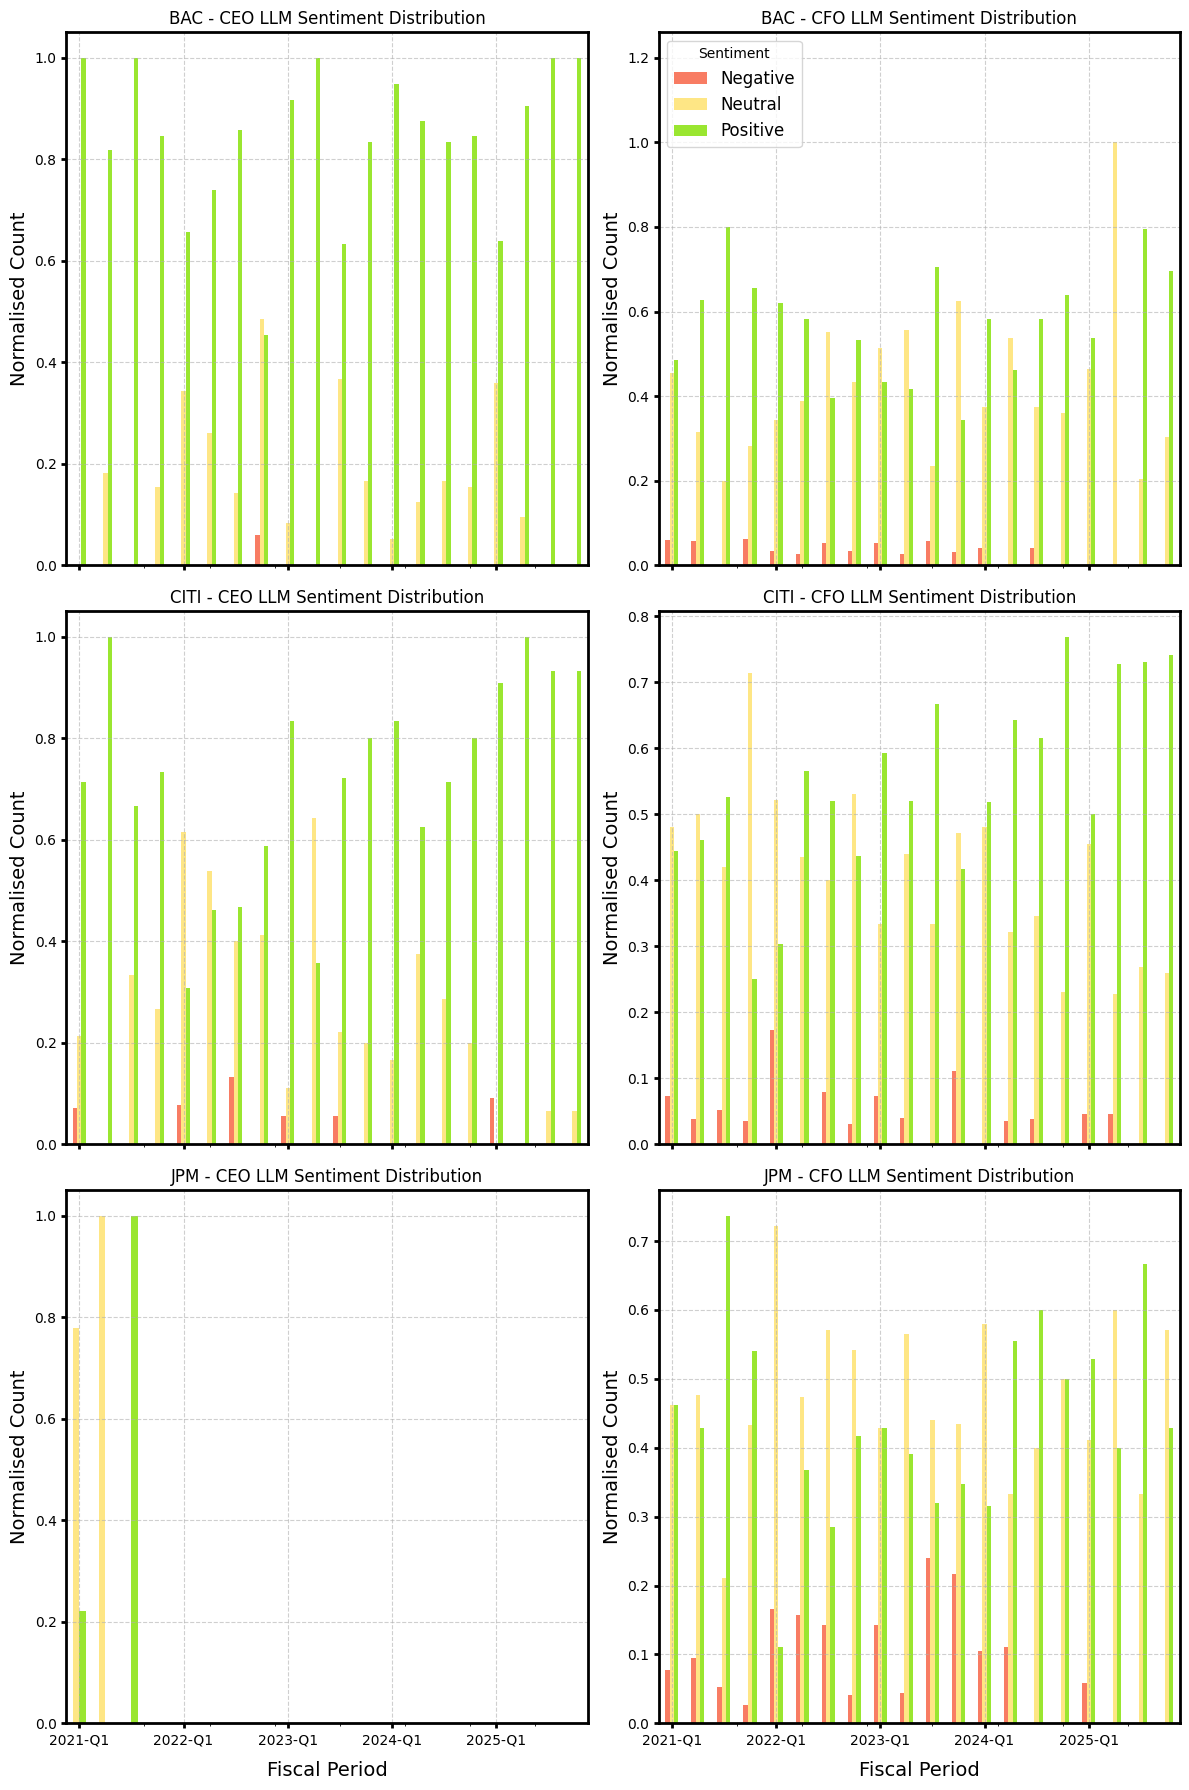

In [ ]:
# Distribution plots

# Get the normalised LLM label counts
llm_counts_norm=get_label_counts(prepared_remarks_chunked_df)

roles = ['CEO', 'CFO']
banks = ['BAC','CITI','JPM']
sentiment_colors = {
    'Positive': '#9AE630',  # Green
    'Neutral': '#FEE685',   # Yellow
    'Negative': '#F87C63'   # Red
}

# Create a 3-row by 2-column figure grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 18), sharex=True)

# Loop through banks and roles to plot
for col_idx, role in enumerate(roles):
    for row_idx, bank in enumerate(banks):

        # Select the specific subplot axis
        ax = axes[row_idx, col_idx]

        # Get the specific series data (unstacking makes it easy to plot lines/bars per sentiment)
        plot_data = llm_counts_norm[role][bank].unstack(fill_value=0)

        # Plot the data (e.g., as a line plot or stacked bar)
        plot_data.plot(kind='bar',color=sentiment_colors, ax=ax, rot=0)

        # Titles and Formatting
        ax.set_title(f"{bank} - {role} LLM Sentiment Distribution")
        ax.set_ylabel("Normalised Count",fontsize=14)
        ax.set_xlabel("Fiscal Period",fontsize=14,labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.6)

        # Increase tick visibility
        ax.tick_params(width=2)
        ax.tick_params(axis='y', labelsize=10)
        ax.tick_params(axis='x', labelsize=10)


        # Change spine (axis line) outline thickness to 2
        for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

        ax.grid(True, linestyle='--', alpha=0.6)

        # Get current ticks and labels
        ticks = ax.get_xticks()
        labels = [label.get_text() for label in ax.get_xticklabels()]

        # Apply every 4th tick and label
        ax.set_xticks(ticks[::4])
        ax.set_xticklabels(labels[::4], rotation=0)

        # Only show the legend on the very first plot to avoid cluttering the grid
        if row_idx == 0 and col_idx == 1:
            ax.legend(title='Sentiment', loc='upper left', fontsize=12)
            # Expand the y-axis limit by 20% to safely accommodate the legends
            current_ylim = ax.get_ylim()
            ax.set_ylim(current_ylim[0], current_ylim[1] * 1.2)
        else:
            ax.legend().remove()

# Clean up layout and display
plt.tight_layout()
# plt.savefig('LLM_Label_Dists.svg')
plt.show()

Across all 3 banks and both executives, the distribution of the labels assigned by the Llama 3.1 8B Instruct model are overwhelmingly positive or neutral with the proportion of negative labels rarely reaching beyong 20%. In the case of Bank of America, CitiGroup and JPMorgan CFOs the maximum negative proportion is on around 5%, 17% and 23%, respectively.

Comparing the CEO to CFO sentiments, it can be ascertained that there are more cases of negative sentiment in CFO speeches compared that of the CEOs.

Below are some examples of the reasoning used by the Llama 3.1 model to label the 5-sentence chunks:

In [ ]:
prepared_remarks_chunked_df[['llm_sentiment','llm_reasoning']].sample(5)

,llm_sentiment,llm_reasoning
1522,Neutral,The company is focusing on cost reduction and ...
113,Positive,The CFO's departure is framed as a positive op...
1871,Positive,The company reported a 20% year-on-year revenu...
2029,Negative,The overall sentiment is negative due to the s...
162,Positive,The company is experiencing a shift towards di...


In [ ]:
# Neutral
prepared_remarks_chunked_df.loc[1522,'llm_reasoning']

'The company is focusing on cost reduction and expense optimization strategies to drive investment revenue, indicating a cautious approach to managing expenses and improving profitability.'

In [ ]:
# Positive
print(prepared_remarks_chunked_df.loc[113,'llm_reasoning'])

# Positive
print(prepared_remarks_chunked_df.loc[1871,'llm_reasoning'])

The CFO's departure is framed as a positive opportunity for the company, highlighting the CFO's past success and the company's future growth prospects.
The company reported a 20% year-on-year revenue increase, driven by higher management fees, growth in deposit and loan balances, and investment valuation gains, despite deposit margin compression and rising expenses.


In [ ]:
# Negative
prepared_remarks_chunked_df.loc[2029,'llm_reasoning']

'The overall sentiment is negative due to the significant decline in Investment Banking revenue and fees across various business segments, despite some market conditions being in line with expectations.'

As the examples show the reasoning used to label the sentiments is reasonable and similar to human reasoning.

However, in the neutral case, the mention of cost reduction and expense optimisation could also be considered negative without the strategic context. In other words, *the company taking a cautious approach towards improving profits but being careful in a volatile market* is not necessarily negative and the LLM appears to account for the hidden context.

In the first positive case, correspoding to row '113', the remarks made about the CFO departure could also be taken negative but is clearly given a positive spin by the speaker. One would need to have intimate knowledge of the sector and the specific bank to know whether this is truly positive or negative.

Without going through each small paragraph and doing additonal research using external resources, the LLM reasoning remains sensible and valid.

## 5.4.2 Visualisation and analysis of the FinBERT sentiment label distributions obtained for the 3 banks.

To visualize the sentiment trends over time, we will convert the categorical predictions (`positive` -> 1, `neutral` -> 0, `negative` -> -1) into a continuous sentiment score. We will then group the data by bank, year, and quarter to plot these trends.

In [ ]:
# Map sentiments to numerical values
sentiment_mapping = {'positive': 1.0, 'neutral': 0.0, 'negative': -1.0}
prepared_remarks_chunked_df['sentiment_score'] = prepared_remarks_chunked_df['predicted_sentiment'].map(sentiment_mapping)

In [ ]:
# prepared_remarks_chunked_df.head()

### 5.4.2.1 Average Quarterly Sentiment Trends Over Time (FinBERT)

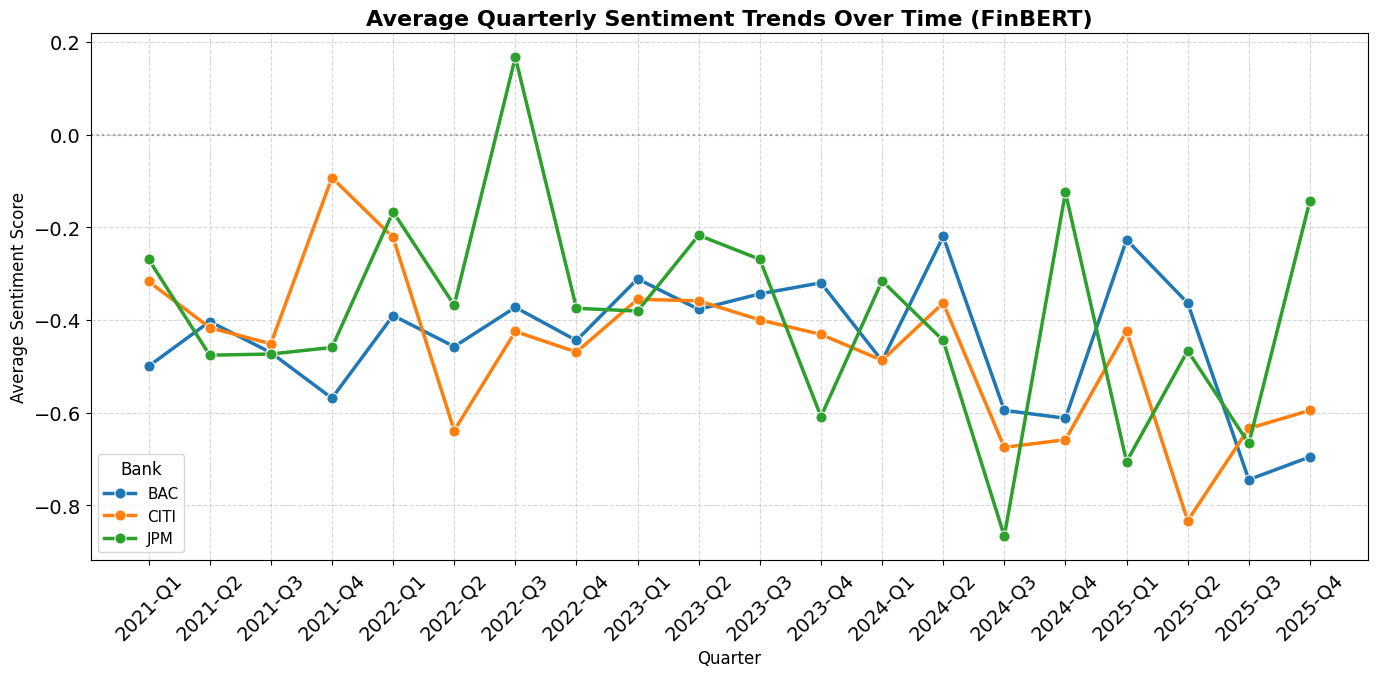

In [ ]:
# Group by Bank and Period, then calculate the average sentiment score
confidence_trend= prepared_remarks_chunked_df.groupby(['bank','fiscal_period'])['sentiment_score'].mean().reset_index()

# Sort chronologically by year and quarter
confidence_trend = confidence_trend.sort_values(by=['bank', 'fiscal_period']).reset_index(drop=True)

# Plot the sentiment trends
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=confidence_trend,
    x='fiscal_period',
    y='sentiment_score',
    hue='bank',
    marker='o',
    linewidth=2.5,
    markersize=8
)

plt.title('Average Quarterly Sentiment Trends Over Time (FinBERT)', fontsize=16, fontweight='bold')
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Average Sentiment Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.axhline(0, color='gray', linestyle=':', alpha=0.7)
plt.legend(title='Bank', fontsize=11, title_fontsize='12')
plt.tight_layout()
# plt.savefig('Ave_Quarterly_Sent_Trends.svg')
plt.show()

**Overall Negative Baseline Sentiment**: Virtually all quarterly average sentiment scores across the three banks (Bank of America Corporation, Citigroup, JPMorgan) reside below 0 (the neutral axis), staying primarily between -0.2 and -0.8. The negative skew is typical for corporate financial disclosures. In regulatory filings and transcripts, language is highly conservative, focusing on risks, cost containment, allowances for credit losses, and macro uncertainties, which financial sentiment models like FinBERT categorize as 'negative'.


### 5.4.2.2 Yearly Trends of Sentiments: CEO vs CFO by Bank

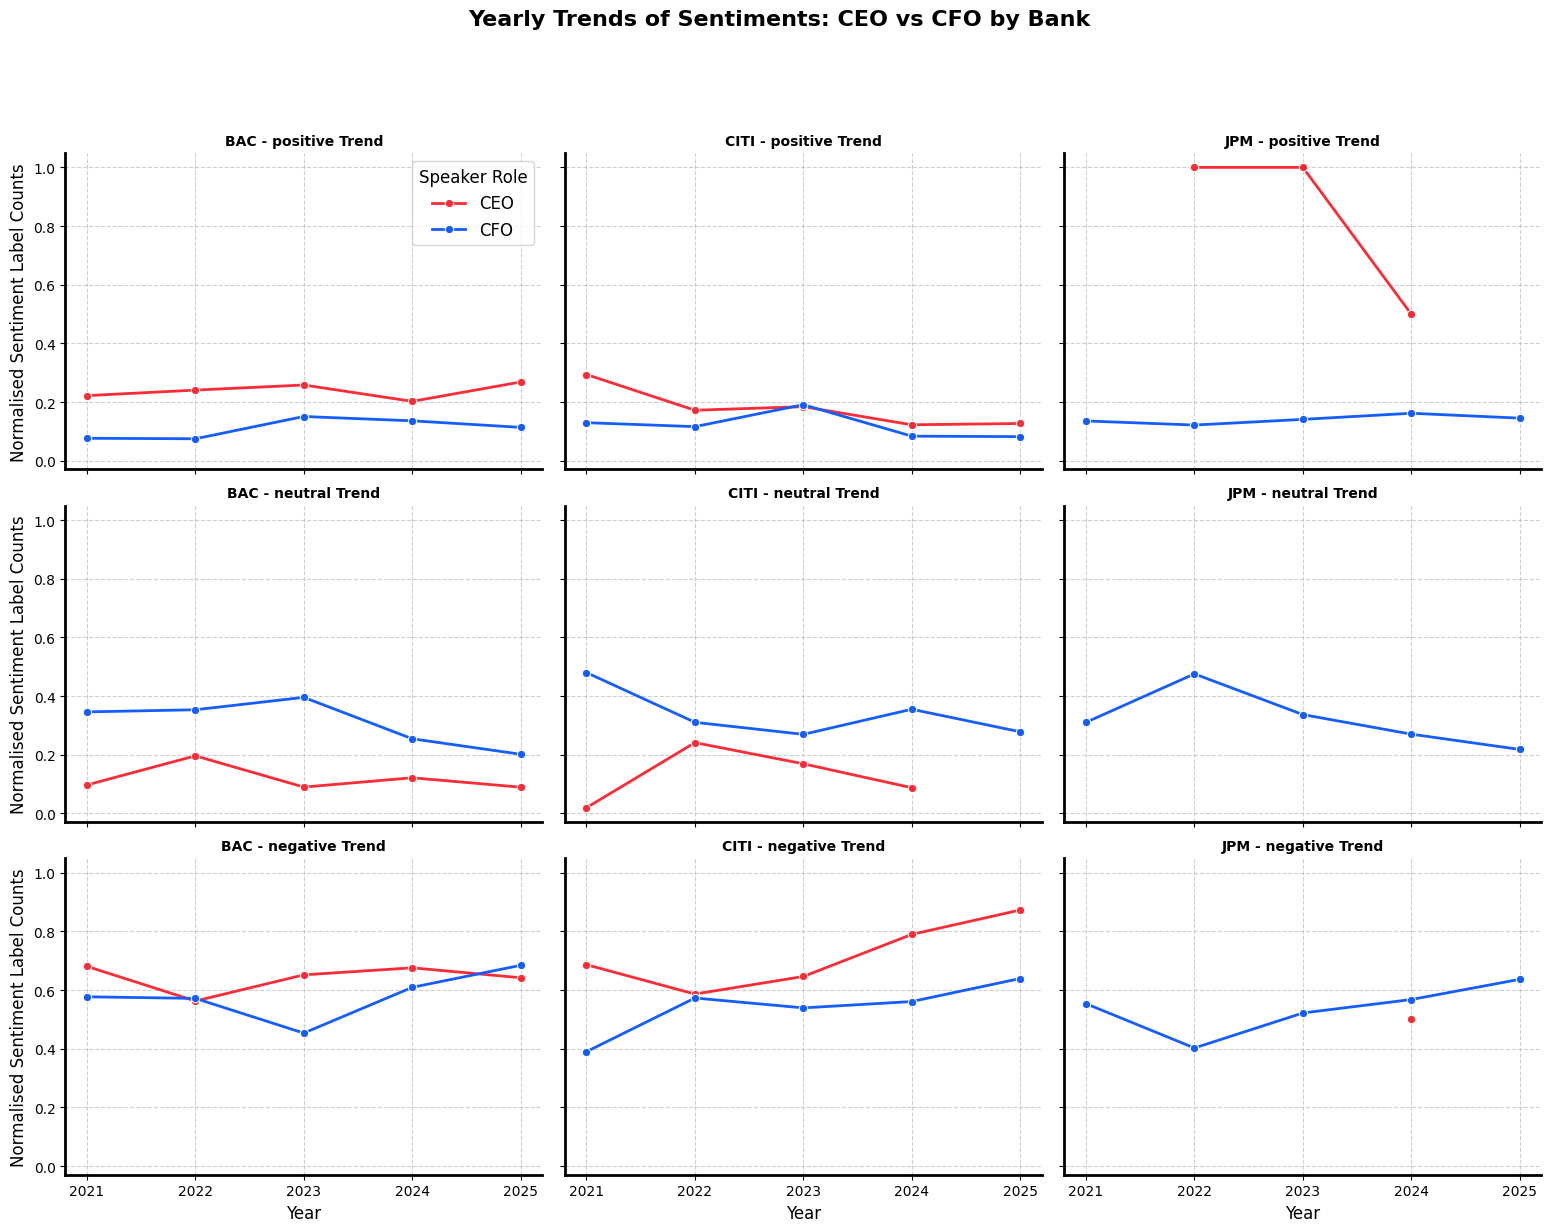

In [ ]:
# Calculate yearly percentages of each sentiment label per bank and speaker role

finbert_counts_year= get_label_counts(prepared_remarks_chunked_df,
                                      groupby_cols=['bank', 'year'],
                                      target_col='predicted_sentiment', normal='True')


finbert_counts_year_df = (pd.DataFrame(finbert_counts_year).stack()
                         .reset_index()
                         .rename(columns={"level_3": "speaker_role", 0: "proportion"})
                        )


# Set plotting theme
sns.reset_orig()

# Create a FacetGrid with banks as columns and sentiments as rows to map trends cleanly
g = sns.FacetGrid(
    finbert_counts_year_df,
    row="predicted_sentiment",
    col="bank",
    hue="speaker_role",
    palette=speaker_colors,
    height=4,
    aspect=1.3,
    sharey=True,
    row_order=["positive", "neutral", "negative"]
)

g.map(sns.lineplot, "year", "proportion", marker="o", linewidth=2, markersize=6)

# Style layout and labels
g.set_axis_labels("Year", "Normalised Sentiment Label Counts",fontsize=12)
g.set_titles("{col_name} - {row_name} Trend",fontsize=16,weight='bold')

# Grab the first axis subplot from the grid array
first_ax = g.axes.flat[0]

# Apply the legend constraints directly to this specific axis
first_ax.legend(
    title="Speaker Role",
    fontsize=12,
    title_fontsize=12,
    loc="upper right"
)

# Adjust x-ticks to display only actual years
for ax in g.axes.flat:
    ax.set_xticks(sorted(finbert_counts_year_df['year'].unique()))
    ax.grid(True, linestyle='--', alpha=0.6)
    for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Yearly Trends of Sentiments: CEO vs CFO by Bank", fontsize=16, weight='bold', y=1.02)
# plt.savefig('Yearly_Sent_Trends_Bank.svg')
plt.show()

The observations are consistent with the expectation that CEOs tend to deliver strategic, future-oriented, and vision-focused narratives, which contain a higher concentration of positive sentiment, whereas CFOs focus on structural facts.

In the top row (positive Trend), the red line (CEOs) is almost always positioned higher than the red line (CFOs) for both BAC and CITI. At JPM, the CEO trend is at its most extreme contrasting the JPM's CFO trend, grouped under 20% positive.

In the middle row (neutral Trend), the blue line (CFOs) sits consistently and significantly above the red line (CEOs) across all three banks. The observation is consistent with the typical CFO communication pattern: parsing regulatory details, tax adjustments, accounting guidelines, and balance sheet reconciliation items that convey zero emotional/strategic tilt.

In the bottom row (negative Trend), both executives have a high proportion of negative chunks (regularly between 40% and 80%). Because financial sentiment models like FinBERT categorize terms like "cost", "expense", "risk", and "decline" as negative, standard banking discourse naturally skews.


### 5.4.2.3 Quarterly Trends of Sentiments: CEO vs CFO by Bank

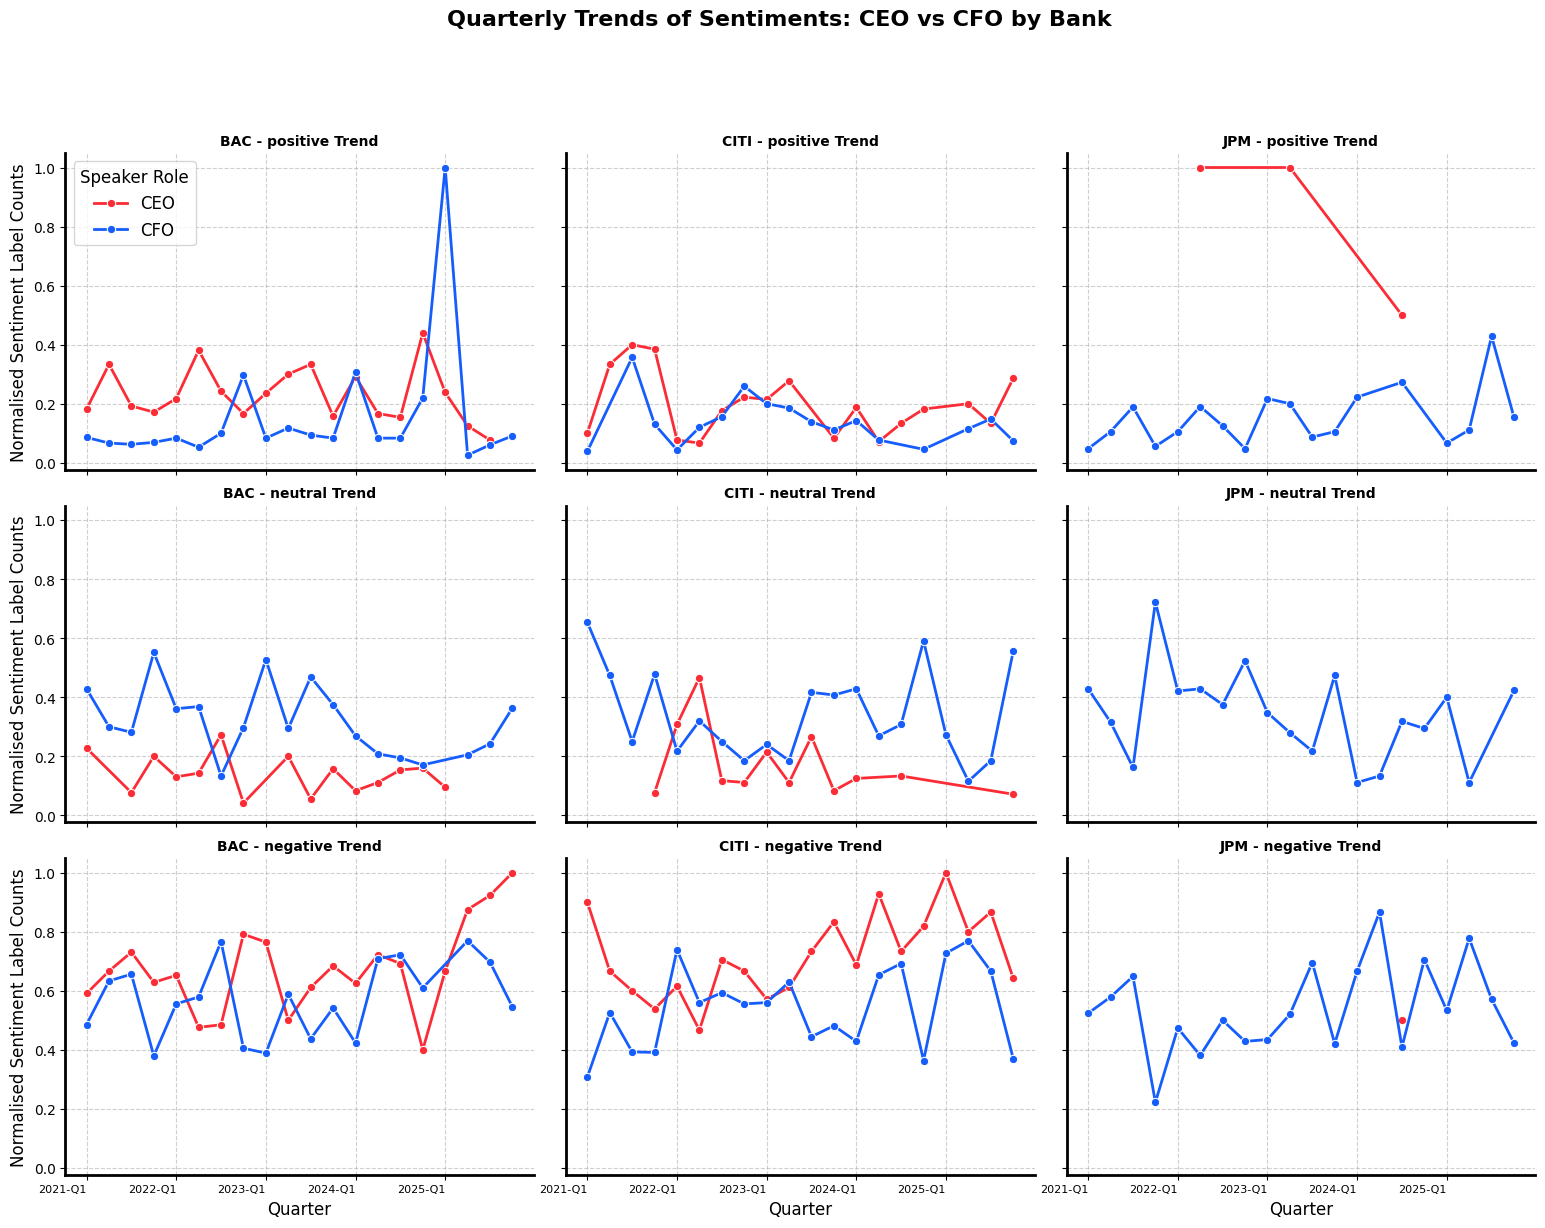

In [ ]:
# Calculate yearly percentages of each sentiment label per bank and speaker role

finbert_counts_quarter= get_label_counts(prepared_remarks_chunked_df,
                                      groupby_cols=['bank', 'fiscal_period'],
                                      target_col='predicted_sentiment', normal='True')


finbert_counts_quarter_df =(pd.DataFrame(finbert_counts_quarter)
                            .stack().reset_index()
                            .rename(columns={"level_3": "speaker_role", 0: "proportion"})
                           )

# Set plotting theme
sns.reset_orig()

# Create a FacetGrid with banks as columns and sentiments as rows to map trends cleanly
g = sns.FacetGrid(
    finbert_counts_quarter_df,
    row="predicted_sentiment",
    col="bank",
    hue="speaker_role",
    palette=speaker_colors,
    height=4,
    aspect=1.3,
    sharey=True,
    row_order=["positive", "neutral", "negative"]
)

g.map(sns.lineplot, "fiscal_period", "proportion", marker="o", linewidth=2, markersize=6)

# Style layout and labels
g.set_axis_labels("Quarter", "Normalised Sentiment Label Counts",fontsize=12)
g.set_titles("{col_name} - {row_name} Trend",fontsize=16,weight='bold')

# Grab the first axis subplot from the grid array
first_ax = g.axes.flat[0]

# Apply the legend constraints directly to this specific axis
first_ax.legend(
    title="Speaker Role",
    fontsize=12,
    title_fontsize=12,
    loc="upper left"
)
chronological_quarters = sorted(finbert_counts_quarter_df['fiscal_period'].unique())

# Adjust x-ticks to display only actual years
for ax in g.axes.flat:
    ax.set_xticks(range(len(chronological_quarters)))
    ax.set_xticklabels(chronological_quarters, rotation=45, ha='right', fontsize=8)
    # Get current ticks and labels
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ax.get_xticklabels()]

    # Apply every 4th tick and label
    ax.set_xticks(ticks[::4])
    ax.set_xticklabels(labels[::4], rotation=0)

    ax.grid(True, linestyle='--', alpha=0.6)
    for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Quarterly Trends of Sentiments: CEO vs CFO by Bank", fontsize=16, weight='bold', y=1.02)
# plt.savefig('Quarterly_Sent_Trends_Bank.svg')
plt.show()


While the yearly plots present a smoother, gradual change, the quarterly curves reveal sharp, immediate reactions to macro events and earnings shocks. An example is the massive positive sentiment spike experienced by BAC around 2025-Q2- after the event causing it dissipates the spike course corrects over the next quarter and plummets to below 10%.

Across all three banks, the CFOs' blue lines in the neutral and negative rows show a remarkably steady, structural baseline. CFOs rarely fall below a 40% negative or 20% neutral concentration in any given quarter. This is because their updates focus on the recurring granular, objective financial results, expenses, and provisions.






### 5.4.2.4 Negative Sentiment Trend by Bank per Quarter


The negative sentiment distribution plot isolates the proportion of sentence chunks classified as negative per quarter, providing a direct view of defensive positioning over time. Since the CEO does not always speak/take part in the earnings calls, in cases where they speak once during the call with a negative underlying sentiment, the percentage can blow up to 100%, skewing the dataset.

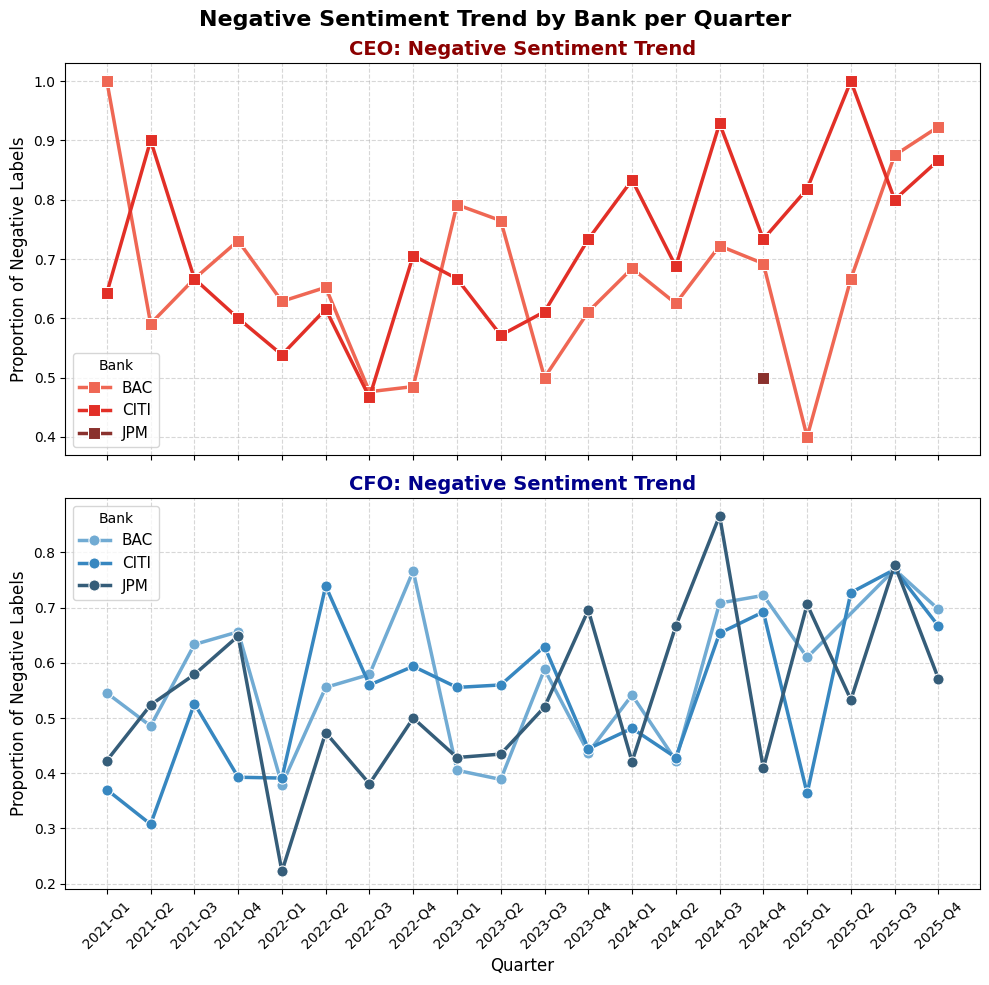

In [ ]:
# Filter to keep only the negative sentiment category
negative_share_only = finbert_counts_quarter_df[finbert_counts_quarter_df['predicted_sentiment']=='negative']
negative_share_only_CFO = negative_share_only[negative_share_only['speaker_role']=='CFO'].reset_index(drop=True)
negative_share_only_CEO = negative_share_only[negative_share_only['speaker_role']=='CEO'].reset_index(drop=True)

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharex=True)

# ----------------- FIRST SUBPLOT (Top Row) -----------------
sns.lineplot(
    data=negative_share_only_CEO,
    x='fiscal_period',
    y='proportion',
    hue='bank',
    marker='s',
    linewidth=2.5,
    markersize=8,
    palette='Reds_d',
    ax=axes[0]
)

axes[0].set_title('CEO: Negative Sentiment Trend', fontsize=14, fontweight='bold', color='darkred')
axes[0].set_ylabel('Proportion of Negative Labels', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Bank', fontsize=11)

# ----------------- SECOND SUBPLOT (Bottom Row) -----------------
sns.lineplot(
    data=negative_share_only_CFO,
    x='fiscal_period',
    y='proportion',
    hue='bank',
    marker='o',
    linewidth=2.5,
    markersize=8,
    palette='Blues_d',
    ax=axes[1]
)

axes[1].set_title('CFO: Negative Sentiment Trend', fontsize=14, fontweight='bold', color='darkblue')
axes[1].set_xlabel('Quarter', fontsize=12)
axes[1].set_ylabel('Proportion of Negative Labels', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Bank', fontsize=11)

# Rotate the bottom x-axis ticks
axes[1].tick_params(axis='x', rotation=45)

# --------------------------------------------------------
plt.suptitle('Negative Sentiment Trend by Bank per Quarter', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('Negative_Sent_Trends_Bank.svg')
plt.show()


Across all three banks, the negative sentiment percentage shows a large variation but typically hovers near 50-60%. The presence of a baseline demonstrates that defensive topics (e.g credit provisions, expense controls, and structural cost-cutting) form the basis of banking communications, even during stable quarters.

### 5.4.2.5 Top 10 "Hedging" Keywords in Negative Sentiment Chunks

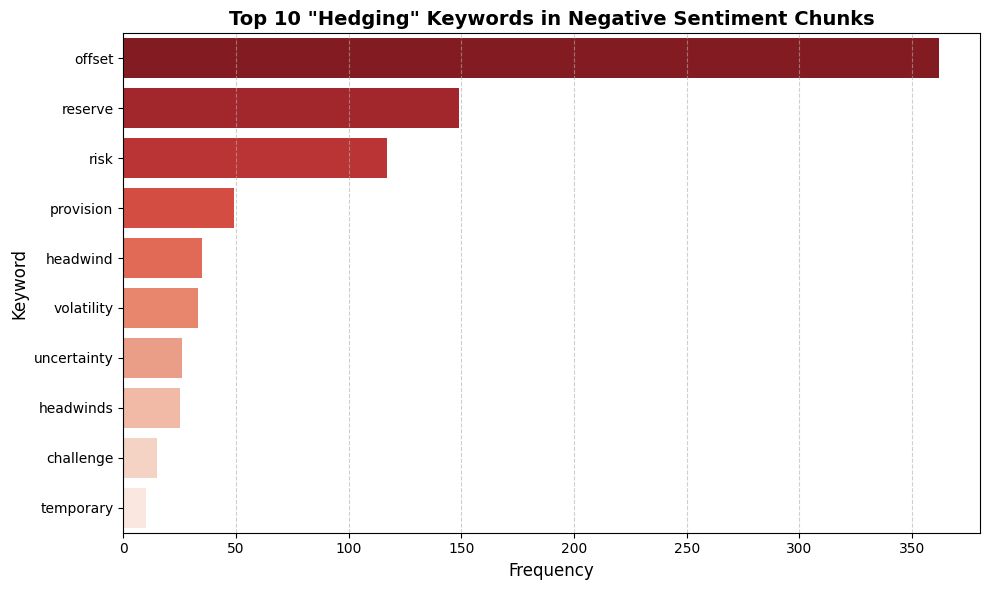

In [ ]:
# Define target hedging/defensive keywords
hedging_words = [
    'offset', 'mitigate', 'provision', 'reserve', 'uncertainty',
    'cautious', 'challenge', 'volatility', 'headwinds', 'temporary',
    'disruption', 'headwind', 'cautiously', 'unpredictable', 'risk'
]

# Filter to get sentence chunks categorized as negative by FinBERT
negative_sentence_chunks = prepared_remarks_chunked_df[prepared_remarks_chunked_df['predicted_sentiment'] == 'negative']['sentence_chunks'].dropna()

# Count frequencies of the specified hedging keywords in the negative chunks
keyword_counts = Counter()
for chunk in negative_sentence_chunks:
    text_lower = str(chunk).lower()
    for word in hedging_words:
        # Match whole words to avoid partial matches (e.g., 'provisions' using word boundaries or manual plural handling)
        matches = re.findall(rf'\b{word}s?\b', text_lower)
        keyword_counts[word] += len(matches)

# Convert to DataFrame for plotting
hedging_df = pd.DataFrame(keyword_counts.most_common(10), columns=['Keyword', 'Frequency'])

# Plot the top 10 hedging keywords
plt.figure(figsize=(10, 6))

sns.barplot(
    data=hedging_df,
    x="Frequency",
    y="Keyword",
    hue="Keyword",
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 "Hedging" Keywords in Negative Sentiment Chunks', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Keyword', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Hedging_Keywords.svg')
plt.show()


Focussing on the topmost frequently used hedging words:

**1.'Offset' (~360 occurrences)**

The term offset is overwhelmingly the most frequent hedging word. In financial transcripts, "offset" is used to neutralize negative news with positive results, or vice versa (e.g., "strong revenue was offset by rising credit card write-offs" or "expense growth offset by structural efficiencies").  (Loughran & McDonald, 2011)
    
When the frequency of "offset" begins to spike quarter-on-quarter (QoQ), it can indicate that management is struggling to deliver "pure" positive developments, forcing them to balance positive headlines with operational friction.

**2.'Reserve' (150) and 'Risk' (120)**

Both terms rank second and third, representing structural balance sheet adjustments and macro conditions.
    
An increase in the mention of "reserve" and "risk"—specifically in negative chunks—typically means the bank is actively defending its balance sheet against souring loan portfolios or expanding macroeconomic risks. (Campbell et al., 2014)

**3.The 'Headwind' (25) and 'Volatility' (25)**

Keywords like headwind(s), volatility, and uncertainty appear frequently as external excuses for poor performance or conservative guides. (Baginski et al, 2004)
   
If these vocabulary metrics increase while peer banks' hedging vocabularies remain flat, it can signal idiosyncratic execution challenges within that specific bank rather than just industry-wide macro problems.


## 5.4.3 FinBERT versus Llama 3.1: classification report analysis.

To perform the classification analysis, we make the assumption that the labels assigned by the Llama 3.1 8B Instruct model are the true labels, for the Llama model has been trained using the RLHF approach.

While the assumption by itself is not entirely valid and merely serves as an educated guess, it gives us the opportunity to make direct comparisons across label proportions simply using confusion matrices.

However, it must be noted that one of the aspirations of the RLHF method, which is to align a model to be helpful to humans can create a positivity bias.

Therefore, while Llama 3.1 8B Instruct is used to replace domain expert labels, it may act as a financial analysts with an unusually positive outlook.

### 5.4.3.1 Confusion Matrix Classification Approach

The classification approach will focus on the recall parameter which in general gives the proportion of true positive predictions out of all actual positive instances.  

In [ ]:
# Let's start with the full dataset
# Define the explicit order of  classes
target_names = ['negative', 'neutral', 'positive']

# LLM labels which are not in lower case
y_true_all_raw = prepared_remarks_chunked_df['llm_sentiment']
y_true_all = [str(label).lower() for label in y_true_all_raw]  # str() to prevent bugs if NaNs exist

# FinBERT labels
y_pred_all = prepared_remarks_chunked_df['predicted_sentiment']

# Generate and print the text-based Classification Report
print(f"--- FinBERT Classification Report for full dataset ---")

# zero_division=0 prevents crashing if a bank is missing a specific category entirely
report_all = classification_report(
      y_true_all,
      y_pred_all,
      target_names=target_names,
      zero_division=0
  )
print(report_all)

--- FinBERT Classification Report for full dataset ---
              precision    recall  f1-score   support

    negative       0.01      0.21      0.03        87
     neutral       0.60      0.43      0.50       820
    positive       0.51      0.13      0.21      1359

    accuracy                           0.24      2266
   macro avg       0.37      0.26      0.24      2266
weighted avg       0.52      0.24      0.31      2266



The classification report shows the recall for negative, neutral and positive labels is on average 21%, 43% and 13%, respectively. The highest agreement is between the neutral sentiment labels whereas the lowest is betwen positive sentiment labels. While the agreement agreement across all labels is below 50%, as if hapenned by random chance, the results are consistent with the following observations made on FinBERT (Araci, 2019):

* FinBERT cannot discern whether a statment indicates a positive outlook or merely an objective observation.

* FinBERT typically fails to do the math in which figure is higher. Therefore, in the absence of words indicative of direction like "increased", the prediction skews towards neutral.

In [ ]:
# For the confusion matrix will use row-normalized percentages:
def matrix_labels(cm):
    # Flatten the raw counts
    cm_counts = cm.flatten()

    # Calculate percentages relative to the True Class row totals (Recall per cell)
    # This divides each cell by the sum of its row
    row_sums = cm.sum(axis=1, keepdims=True)

    # Avoid division by zero if a class has no samples
    percentages = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums!=0) * 100
    cm_percentages = [f'{perc:.2f}%' for perc in percentages.flatten()]

    # Combine counts and percentages
    ini_labels = [f'Count: {count}\n({perc})' for count, perc in zip(cm_counts, cm_percentages)]

    # Reshape to a 3x3 grid for the heatmap
    cm_labels = np.asarray(ini_labels).reshape(3, 3)
    return cm_labels

By calculating normalised percentage across each row, we ensure the diagonal elements show the exact Recall percentage for each sentiment category (e.g., what % of truly negative phrases did FinBERT correctly catch).

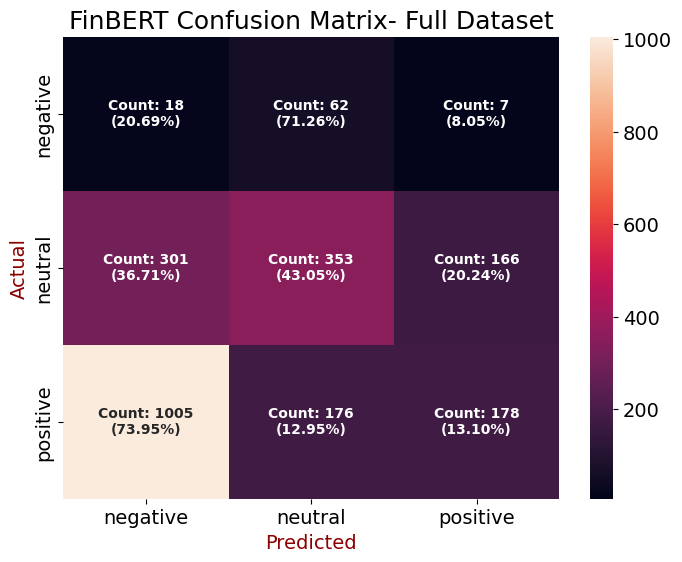

In [ ]:
# Let's visualise the recall on each target

cm_all= confusion_matrix(y_true_all, y_pred_all, labels=target_names)
cm_labels_all = matrix_labels(cm_all)

# Plot heatmap
plt.figure(figsize=(8,6))
plt.rc('font', weight='normal', size=14)
ax=sns.heatmap(
    cm_all,
    annot=cm_labels_all,
    annot_kws={"fontweight": 'bold', "size": 10},
    fmt='',
    cmap='rocket',

)

# Format axes labels
ax.xaxis.set_ticklabels(['negative', 'neutral', 'positive'],fontsize=14)
ax.yaxis.set_ticklabels(['negative', 'neutral', 'positive'],fontsize=14)

plt.xlabel('Predicted',fontsize=14,color='darkred')
plt.ylabel('Actual',fontsize=14,color='darkred')
plt.title('FinBERT Confusion Matrix- Full Dataset',fontsize=18)
# plt.savefig('Fin_Class_full.svg')
plt.show()


Let's look at the differences in sensitivity of the FinBERT model between the 3 banks:

In [ ]:
# Recall the order of classes
# target_names = ['negative', 'neutral', 'positive']

# Group by Bank
for bank_name, bank_group in prepared_remarks_chunked_df.groupby('bank'):

    print("\n" + "="*50)
    print(f"BANK: {bank_name}")
    print("="*50)

    # Isolate and lowercase the LLM labels for this specific bank
    y_true_raw = bank_group['llm_sentiment']
    y_true = [str(label).lower() for label in y_true_raw]  # str() to prevent bugs if NaNs exist

    # Isolate FinBERT labels for this specific bank
    y_pred = bank_group['predicted_sentiment']


    # Generate and print the text-based Classification Report
    print(f"--- FinBERT Classification Report for {bank_name} ---")

    # zero_division=0 prevents crashing if a bank is missing a specific category entirely
    report = classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        zero_division=0
    )
    print(report)



BANK: BAC
--- FinBERT Classification Report for BAC ---
              precision    recall  f1-score   support

    negative       0.00      0.14      0.01        21
     neutral       0.57      0.43      0.49       330
    positive       0.57      0.14      0.22       689

    accuracy                           0.23      1040
   macro avg       0.38      0.24      0.24      1040
weighted avg       0.56      0.23      0.30      1040


BANK: CITI
--- FinBERT Classification Report for CITI ---
              precision    recall  f1-score   support

    negative       0.01      0.17      0.02        30
     neutral       0.59      0.43      0.50       289
    positive       0.54      0.13      0.21       489

    accuracy                           0.24       808
   macro avg       0.38      0.24      0.24       808
weighted avg       0.54      0.24      0.30       808


BANK: JPM
--- FinBERT Classification Report for JPM ---
              precision    recall  f1-score   support

    negati

* The recall for negative labels in a decreasing order by bank: JPMorgan (28%), Citigroup(17%) and Bank of America (14%).

* The recall for neutral labelsby bank: JPMorgan (43%), Citigroup(43%) and Bank of America (43%).

* The recall for positive labels in a decreasing order by bank: Bank of America (14%), Citigroup(13%) and JPMorgan (12%).


While the recall for neutral and positive labels are either same or very close for the three banks studied, the biggest difference is across the negative labels where we see the highest negative sentiment percentage across JPMorgan.

Next, let's break down the confusion matrices by bank and speaker role:

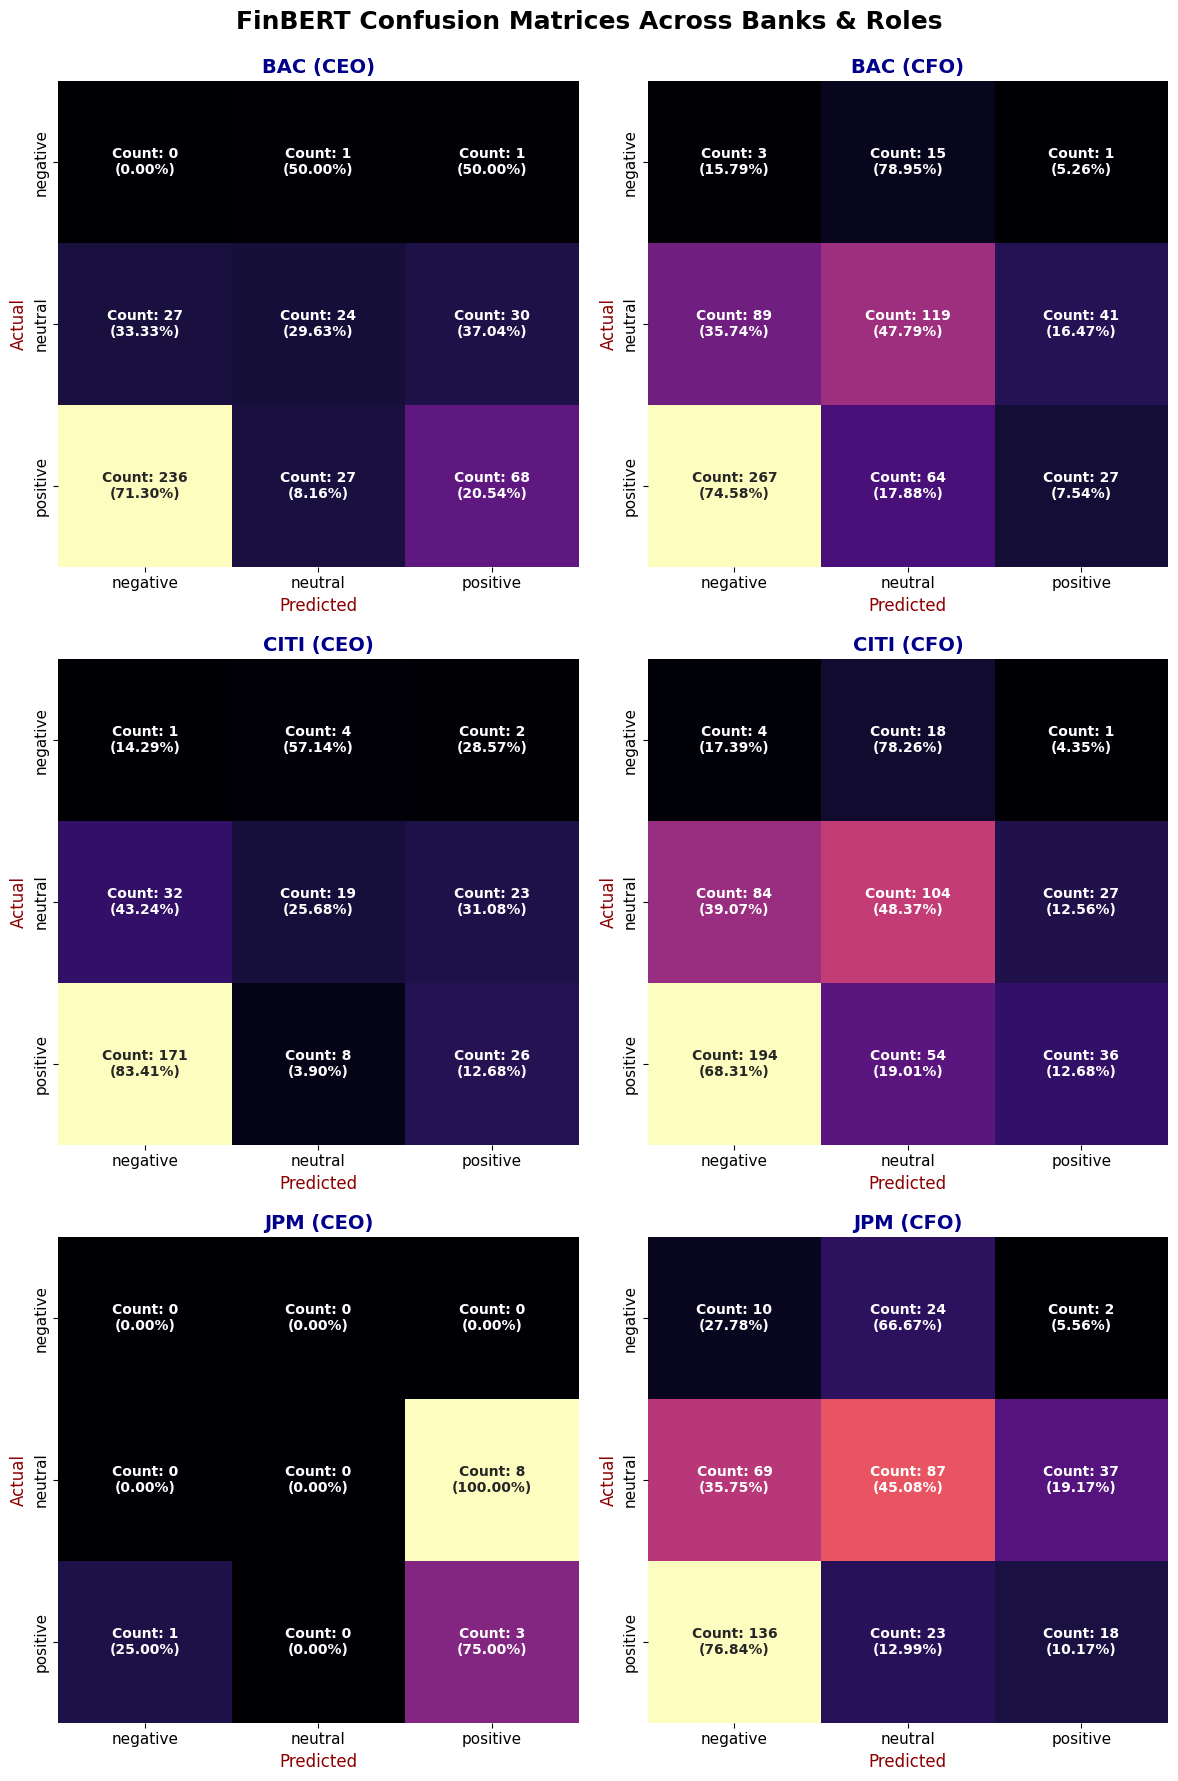

In [ ]:
# Recall the explicit order of classes
# target_names = ['negative', 'neutral', 'positive']

# Group by both bank & speaker role
# Using as_index=False ensures smooth tuple unpacking in the loop header
prepared_remarks_grouped_speaker= prepared_remarks_chunked_df.groupby(['bank', 'speaker_role'])

plt.rcParams["font.weight"] = "normal"

# Create the 3x2 Grid Layout (to fit 3 vertical panels nicely)
fig, axes = plt.subplots(3, 2, figsize=(12, 18))
axes_flat = axes.flatten()  # Flattens the 3x2 matrix into a 1D array of 6 slots

#  Iterate through groups and plot on specific grid cells
for idx, ((bank_name, role), group) in enumerate(prepared_remarks_grouped_speaker):

    # Get the specific axis subplot assigned to this index
    ax = axes_flat[idx]

    # Isolate data and generate matrix
    y_true_raw = group['llm_sentiment']
    y_true = [str(label).lower() for label in y_true_raw]
    y_pred = group['predicted_sentiment']

    cm = confusion_matrix(y_true, y_pred, labels=target_names)
    cm_labels = matrix_labels(cm)

    # Plot heatmap onto the assigned subplot cell (ax=ax)
    sns.heatmap(
        cm,
        annot=cm_labels,
        annot_kws={"fontweight": 'bold', "size": 10},
        fmt='',
        cmap='magma',
        ax=ax,
        cbar=False  # Turns off individual colorbars to keep the grid clean
    )

    # Configure axes layout parameters
    ax.xaxis.set_ticklabels(target_names, fontsize=11)
    ax.yaxis.set_ticklabels(target_names, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=12,color='darkred')
    ax.set_ylabel('Actual', fontsize=12,color='darkred')
    ax.set_title(f'{bank_name} ({role.upper()})', fontsize=14, fontweight='bold',color='darkblue')

# Adjust spacing and show the single combined figure window
plt.suptitle('FinBERT Confusion Matrices Across Banks & Roles', fontsize=18, y=0.99, fontweight='bold')
plt.tight_layout()
# plt.savefig('Fin_Class_Bank.svg')
plt.show()



Note that the label proportions have not been corrected for the number of appearances made by an executive.

* When we isolate the few number of CEO remarks from the JPMorgan dataset, the results remain similar, with both the positive and neutral recall rates shifting by less than 2%.

* In the case of the Citigroup, the agreement between the negative sentiments is higher for the CFO (17.4% compared to 14.3%). The same is also true for the neutral sentiments which have a CFO-to-CEO comparison of 48.4% to 25.7%. The positive sentiment (recall) scores remain the same for both executives.

* There appears to be a more stark difference between the executive recall rates obtained for the Bank of America. The negative sentiment recall rates differ by 15.8% in favour of the CFO; the neutral sentiment recall rates differ by ~ 18.2% in favour of the CEO; and the positive sentiment recall rates differ by 13% in favour of the CEO.

The observation that CFO neutral labels show more agreement may have to do with the said inability of FinBERT to do the math, when CFO is the executive who discloses the big headlines and the banking specific financial metrics.

It can also be argued that while FinBERT is able to detect when the sentiment and tone in language is sounding positive or negative, it is still prone to missing the underlying context, especially in cases where the statements are sugar coated or when there is a case of double negativity (i.e. when a downward word yields a positive outcome, e.g. 'reducing net loss').

Other reported weakness include trigger-word sensitivity. For example if the word 'fall' is used to mean fall within a given range when citing a financial metric, FinBERT will put a very heavy weight on the word 'fall' classifying a neutral statement as negative. Similarly, in a sentence where a company reports 'growing despite challenges faced', FinBERT will again heavily focus on the word challenge. It may also misinterpret the true subject of a matter. For instance, if a competitor firm is being mentioned in a sentence in a negative tone, FinBERT cannot distinguish what that means for the company holding the earings call transcript.

The sugar coating is also a problem for the Llama model, as would perhaps be for a person not well-versed in the financial jargon. For instance, in the case of the CEO who is more likely to put a positive spin on strategic outlook, we observe either very low or no negative label counts.

### 5.4.3.2 Direct comparison of quarterly trends across the 3 banks:



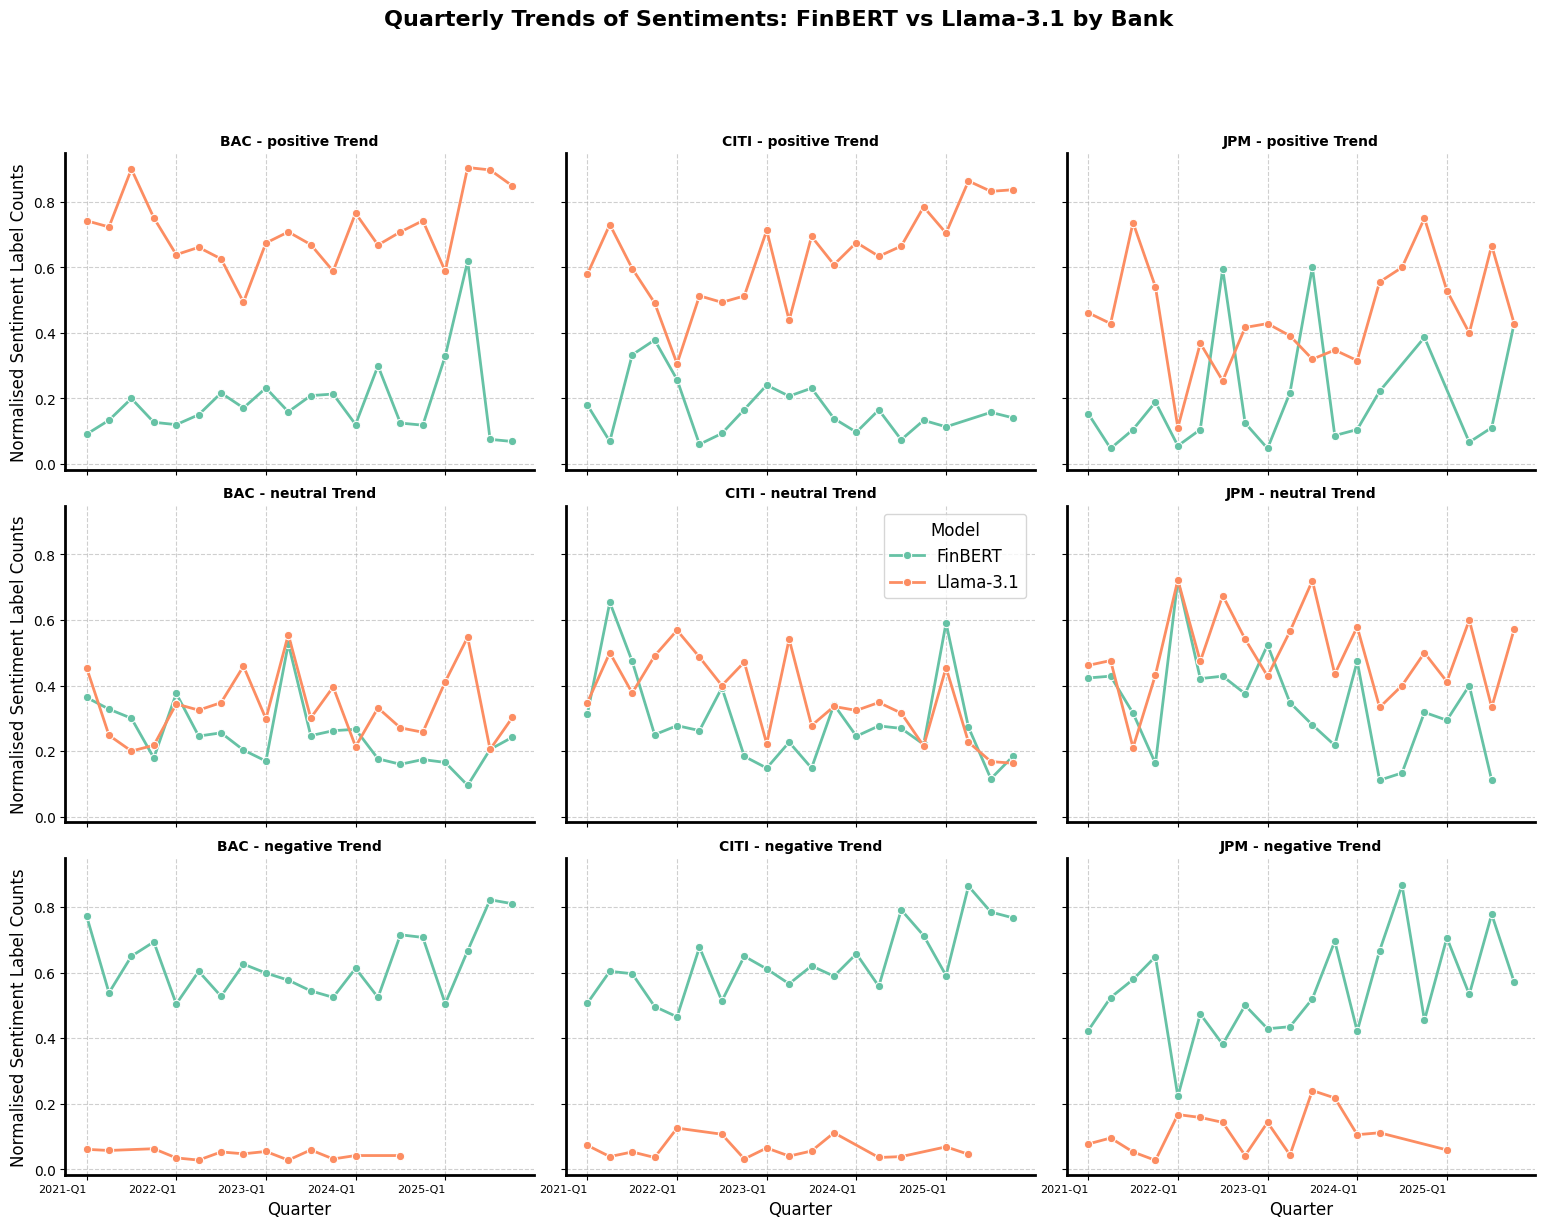

In [ ]:
# Calculate yearly percentages of each sentiment label per bank and speaker role

# Get LLM label counts

llm_counts_quarter= get_label_counts(prepared_remarks_labelled_df,
                                      groupby_cols=['bank', 'fiscal_period'],
                                      target_col='llm_sentiment', normal='True')

# Convert to a dataframe with appropriate labels

llm_counts_quarter_df = (pd.DataFrame(llm_counts_quarter)
                            .stack().reset_index()
                            .rename(columns={"llm_sentiment":"predicted_sentiment","level_3": "speaker_role", 0: "proportion"})
                            )

# Convert the sentiment column to lowercase
llm_counts_quarter_df["predicted_sentiment"] = llm_counts_quarter_df["predicted_sentiment"].str.lower()

# Add a source identifier column to each data frame
finbert_counts_quarter_df["model"] = "FinBERT"
llm_counts_quarter_df["model"] = "Llama-3.1"

# Combine into a single data frame
combined_df = pd.concat([finbert_counts_quarter_df, llm_counts_quarter_df]).reset_index(drop=True)

# Set plotting theme
sns.reset_orig()

# Create a FacetGrid with banks as columns and sentiments as rows to map trends cleanly
g = sns.FacetGrid(
    combined_df,
    row="predicted_sentiment",
    col="bank",
    hue="model",  # This splits the data into two lines per axis
    palette="Set2",  # Changed to a distinct qualitative palette for comparison
    height=4,
    aspect=1.3,
    sharey=True,
    row_order=["positive", "neutral", "negative"],
)

g.map_dataframe(sns.lineplot, "fiscal_period", "proportion", marker="o", linewidth=2, markersize=6,errorbar=None)

# Style layout and labels
g.set_axis_labels("Quarter", "Normalised Sentiment Label Counts",fontsize=12)
g.set_titles("{col_name} - {row_name} Trend",fontsize=16,weight='bold')

# Grab the 5th axis subplot from the grid array
fifth_ax = g.axes.flat[4]

# Apply the legend constraints directly to this specific axis
fifth_ax.legend(
    title="Model",
    fontsize=12,
    title_fontsize=12,
    loc="upper right"
)
chronological_quarters = sorted(combined_df['fiscal_period'].unique())

# Adjust x-ticks to display only actual years
for ax in g.axes.flat:
    ax.set_xticks(range(len(chronological_quarters)))
    ax.set_xticklabels(chronological_quarters, rotation=45, ha='right', fontsize=8)
    # Get current ticks and labels
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ax.get_xticklabels()]

    # Apply every 4th tick and label
    ax.set_xticks(ticks[::4])
    ax.set_xticklabels(labels[::4], rotation=0)

    ax.grid(True, linestyle='--', alpha=0.6)
    for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Quarterly Trends of Sentiments: FinBERT vs Llama-3.1 by Bank", fontsize=16, weight='bold', y=1.02)
# plt.savefig('Quarterly_Sent_Trends_Model.svg')
plt.show()

As expected, the proportion of neutral labels presented across the fiscal quarters for both the Llama 3.1 and the FinBERT models overlap, while the negative labels always remain separated.

Focusing on the positive label trends, the discrepancy is the largest for the Bank of America dataset and smallest for the JPMorgan dataset. This is likely due to there being less instances of positive sentiment for the JPMorgan dataset.

Turning back to the negative label trends, the discrepancy is once again smaller for the JPMorgan dataset, while we see that the proportion of negative labels given by the FinBERT model is consistently higher than that of the Llama 3.1 which may have a slight positivity bias.

## 5.4.4 The evolution of the Llama 3.1 topic distributions obtained per bank.

In [ ]:
# Group by the time period and topic, then count the occurrences for each role
llm_topics = (
    prepared_remarks_chunked_df.groupby(["bank","fiscal_period", "speaker_role","primary_topic"])
    .size()
    .reset_index(name="Count")
)

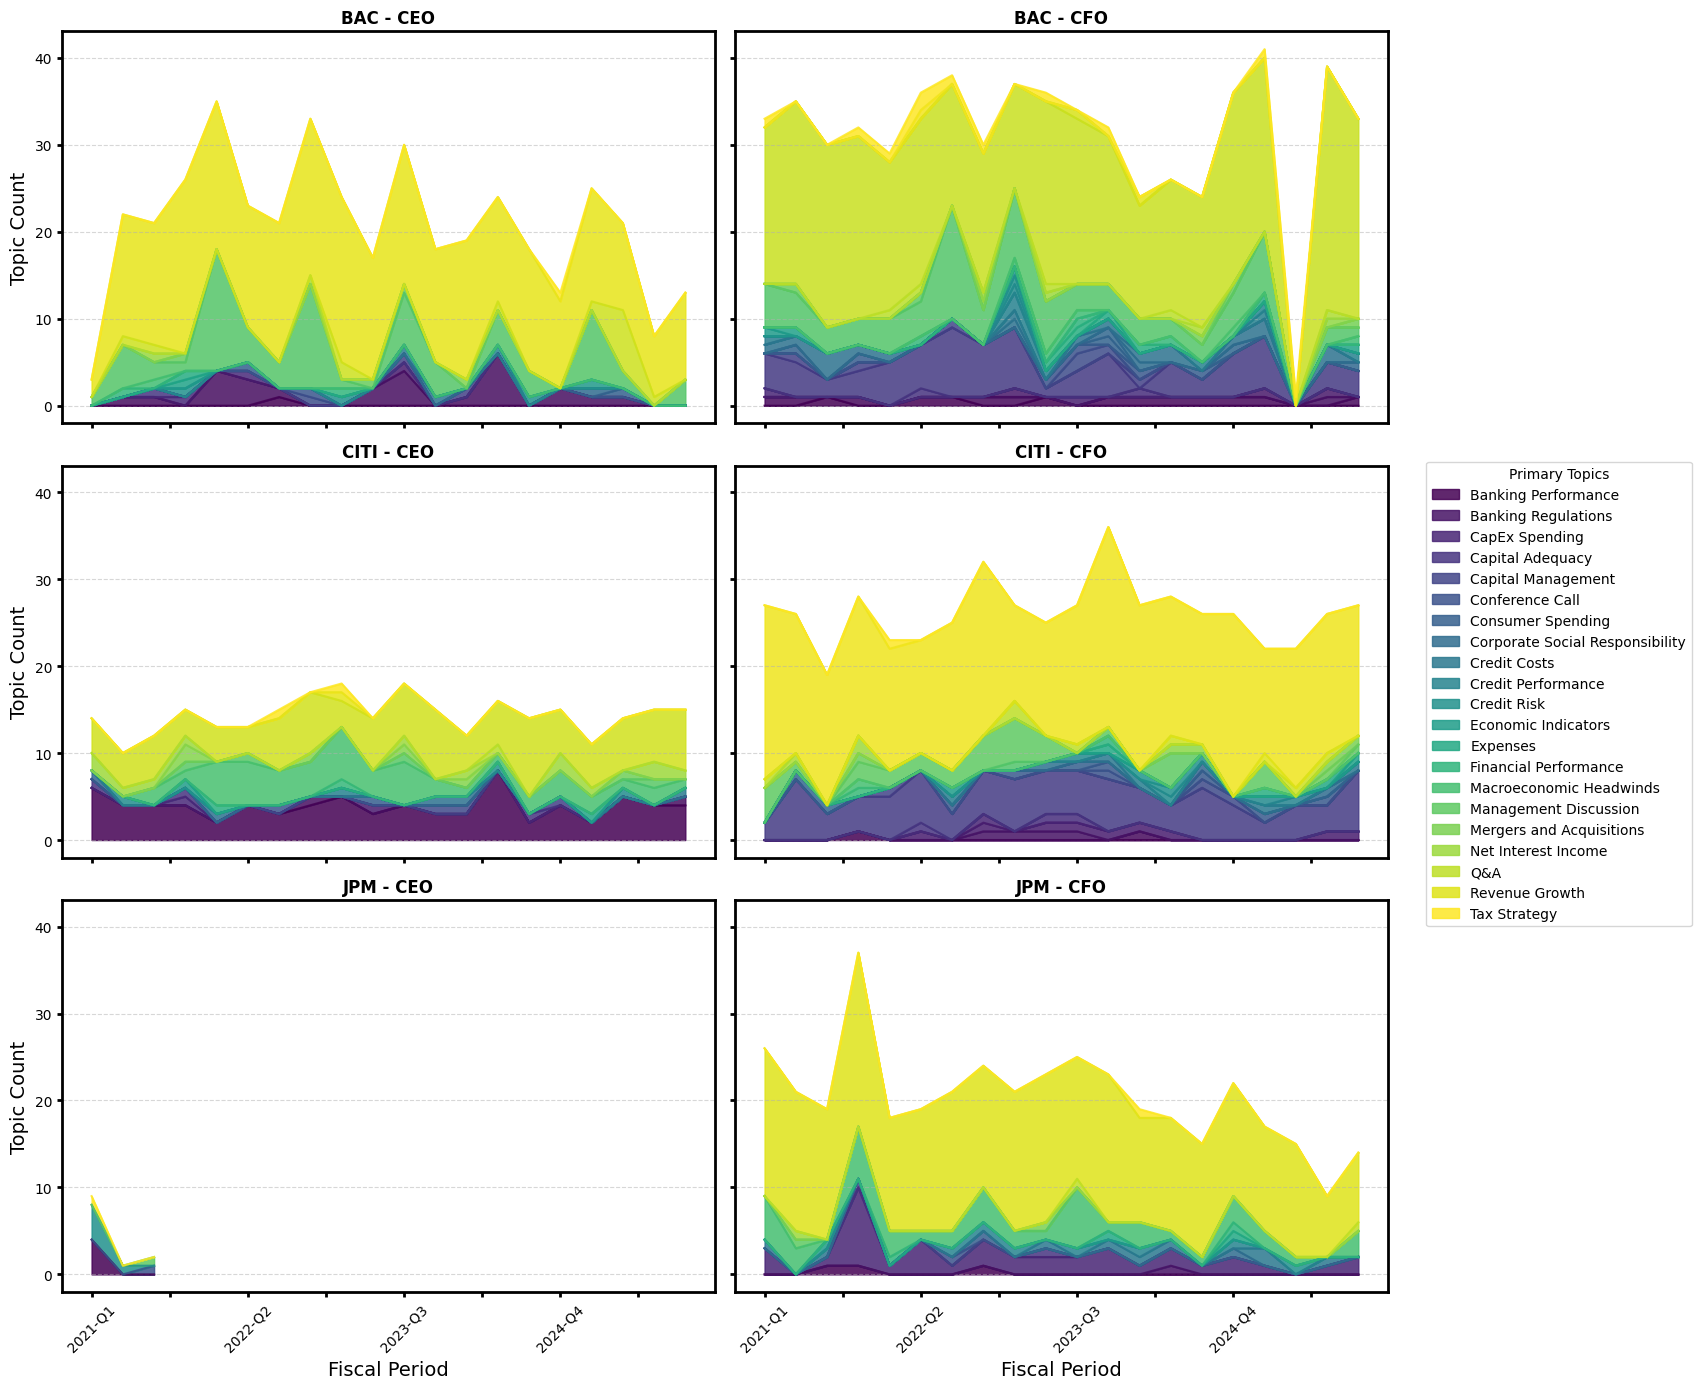

In [ ]:
# Define the dimensions

banks = ["BAC", "CITI", "JPM"]
roles = ["CEO", "CFO"]

# Initialize the 3 rows x 2 columns grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 14), sharex=True, sharey=True)

# Define a shared colormap for all subplots so the legend stays consistent
cmap = plt.get_cmap("viridis")

# Loop through rows (banks) and columns (roles) ---
for row_idx, bank in enumerate(banks):
    for col_idx, role in enumerate(roles):

        # Get the specific subplot axis handle
        ax = axes[row_idx, col_idx]

        # Filter the unpivoted dataset down to the current Bank + Role box
        subset = llm_topics[
            (llm_topics["bank"] == bank) &
            (llm_topics["speaker_role"] == role)
        ]

        # Pivot the filtered data locally for this specific plot panel
        pivot_df = subset.pivot(
            index="fiscal_period",
            columns="primary_topic",
            values="Count"
        ).fillna(0)

        # If data exists for this combination, paint the stacked area chart
        if not pivot_df.empty:
            pivot_df.plot(
                kind="area",
                stacked=True,
                ax=ax,
                cmap=cmap,
                alpha=0.85,
                legend=False # Suppress individual legends inside the grid boxes
            )

        # Design individual grid box elements
        ax.set_title(f"{bank} - {role}", fontsize=12, fontweight="bold")
        ax.grid(axis="y", linestyle="--", alpha=0.5)
        ax.tick_params(axis='x', rotation=45)
        # Change spine (axis line) outline thickness to 2
        for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

        # Increase tick visibility
        ax.tick_params(width=2)
        ax.tick_params(axis='y', labelsize=10)
        ax.tick_params(axis='x', labelsize=10)

        # Label only the outer edges to keep the visual grid uncluttered
        if col_idx == 0:
            ax.set_ylabel("Topic Count", fontsize=14)
        if row_idx == 2:
            ax.set_xlabel("Fiscal Period", fontsize=14)

# Global Titles and a Single Unified Legend ---
# plt.suptitle("Evolution of Earnings Call Topics Over Fiscal Quarters", fontsize=16, fontweight="bold", y=1)

# Grab the labels to construct one global legend
handles, labels = ax.get_legend_handles_labels()

# bbox_to_anchor places it perfectly inside the newly cleared right margin
fig.legend(handles, labels, title="Primary Topics", loc="center left", bbox_to_anchor=(0.89, 0.5))

# rect parameter keeps subplots within 0 to 0.88 horizontal space
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig('TopicEvo.svg')
plt.show()

The results show a range of topics that are discussed within the prepared remarks section which can be several pages long. As well as various financial metrics quoted (e.g. credit costs,CapEX spending), there are themes of strategic outlook in various financial sectors and markets (e.g. mergers and acqusitions, revenue growth,tax strategy).

The colour map indicates topic prevalancy and show how topics like tax strategy, revenue growth, mergers and acquisitions as well as net income dominate discussions QoQ, across all banks (even for the JPM CEO who rarely takes part in prepared remarks). We also see phrases like Q&A session and management discussion make it to the list, since there are several sentence chunks prevailing the Q&A session or greeting the attendees.

Another intresting aspect is the similarity between topic titles such as in the case of capital management and adequacy. This could be the result of a topic being mentioned in one sentence chunk and continuing in the next with different aspects of the topic now introduced.

## 5.4.5 Distribution of sentiment labels across broader topics.

In [ ]:
print(len(prepared_remarks_chunked_df['primary_topic'].unique()))

110


Since there are 110 unique primary topics identified, some of which sound similar, we will perform a basic hierarchical topic clustering using an open source embedding model.

In [ ]:
# Get unique topics
unique_topics = prepared_remarks_chunked_df['primary_topic'].dropna().unique().tolist()

# Convert text topics into vector embeddings
# Using a fast, lightweight open-source embedding model
model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(unique_topics)

# Use hierarchical clustering to group them by distance
# Adjust distance_threshold lower for strict matching, higher for broader groups
clustering = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.6,
    metric='cosine',
    linkage='average'
)
cluster_labels = clustering.fit_predict(embeddings)

# Map each cluster to a dominant parent topic
cluster_map = pd.DataFrame({'topic': unique_topics, 'cluster': cluster_labels})

# Auto-assign the shortest topic title in the cluster as the 'Parent Name'
parent_topics = cluster_map.groupby('cluster')['topic'].agg(lambda x: min(x, key=len)).to_dict()
cluster_map['combined_topic'] = cluster_map['cluster'].map(parent_topics)

# Merge these smart groups back into your main DataFrame
topic_lookup = dict(zip(cluster_map['topic'], cluster_map['combined_topic']))
prepared_remarks_chunked_df['combined_topic'] = prepared_remarks_chunked_df['primary_topic'].map(topic_lookup)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Essentially, the embedding approach converts the acquired raw topics into vectors and automatically groups similar phrases based on semantic meaning.

In [ ]:
print(prepared_remarks_chunked_df['combined_topic'].unique())

['Taxation' 'Balance Sheet' 'Expense' 'Economic Indicators' 'Credit'
 'Liquidity' 'Digital Engagement' 'R&D Investment' 'Human Capital'
 'Social Responsibility' 'Human Resources' 'People/Leadership'
 'Asset Quality' 'Operating Leverage' 'Conference Call'
 'Regulatory Capital' 'CET1 requirement' 'Net Interest Income'
 'Earnings Call' 'People and Technology Costs' 'Q&A' 'Deposit Base'
 'Customer Base' 'Hold-to-Maturity Securities'
 'ESG (Environmental, Social, and Governance)' 'People Movement'
 'M&A/Restructuring' 'Supply Chain Logistics' 'Divestitures'
 'RWA Management']


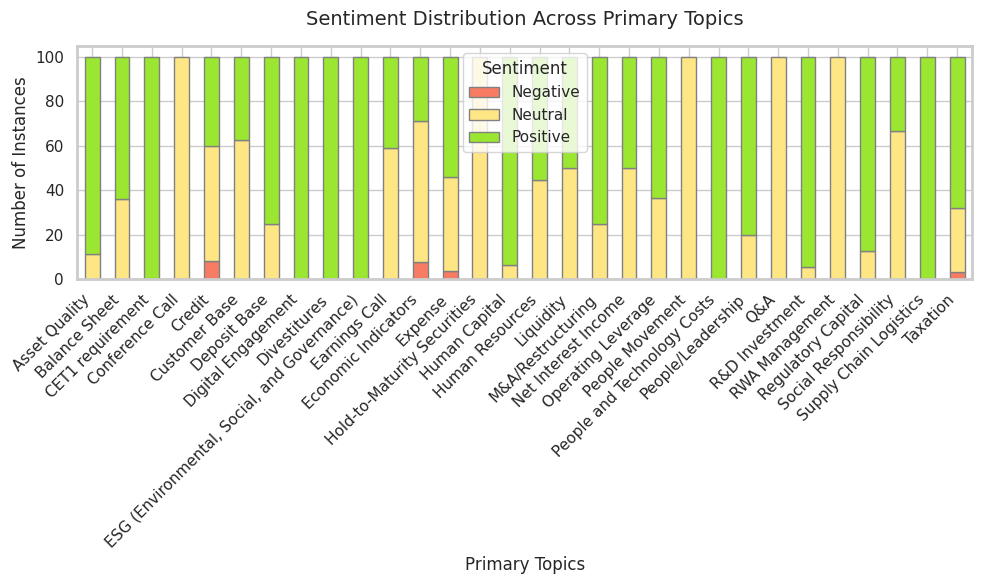

In [ ]:
# Create a contingency table (cross-tabulation)
sentiment_cont = pd.crosstab(prepared_remarks_chunked_df['combined_topic'], prepared_remarks_chunked_df['llm_sentiment'],normalize='index') * 100

# Reorder columns to a logical order (Negative -> Neutral -> Positive)
sentiment_order = ['Negative', 'Neutral', 'Positive']

# Plot the stacked bar chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sentiment_cont.plot(
    kind='bar',
    stacked=True,
    color=['#F87C63', '#FEE685', '#9AE630'],
    edgecolor='gray',
    ax=ax
)

for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

ax.set_title('Sentiment Distribution Across Primary Topics', fontsize=14, pad=15)
ax.set_xlabel('Primary Topics', fontsize=12)
ax.set_ylabel('Number of Instances', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
# plt.savefig('SentimentDistTopics.svg')
plt.show()

Looking at the distribution of labels across the broadly clustered topics, we see a dominance of neutrality and poisitivity again. The only few topics that indicate negativity appear under 'Credit', 'Expense','Economic Indicators' (i.e. based on directionality of the figures, financial metrics being quoted) and 'Taxation' which is generally an unpleasant topic to discuss.

It must be noted that the diversity and large number of topics picked-up by the Llama 3.1 model (even after clustering) means majority of themes have low frequency counts, albeit row-wise normalisaton has been applied.

## 5.5 Conclusions



The analysis shows a significant discrepancy between the sentiment labels assigned by the Llama 3.1 8B Instruct and FinBERT models, where both models have known weaknesses.

FinBERT cannot do the math on quoted figures to understand directionality and focuses on trigger words more than the context. It can indeed be said to have a negativity bias.

Llama 3.1 8B Instruct on the other hand has a positivity bias and is prone to the 'sugar-coating' problem.

However, the RLHF training of the larger Llama model makes it superior when it comes to zero-shot classification (2511.13983v1 [cs.CE],2403.12285v1 [cs.CL],Kirtac and Germano, 2025). It also offers transparency through reasoning and allows tracking of the decisions made.

The study can be extended to include comparisons between the Google's Gemma3:4b and Open AI's GPT models, as there is clearly a value in improving FinBERT's stand alone performance through hybridisation ([ref](https://tommijohnsen.substack.com/p/finbert-is-wrong-83-of-the-time-on?utm_campaign=post-expanded-share&utm_medium=web)).

# 6.0: Finbert Sentiments and Cosine Similarity

## 6.1 Loading libraries and data

In [ ]:
!pip install -q torch transformers accelerate bitsandbytes transformers sentence-transformers faiss-cpu

!pip install -U -q langchain lark langchain-core langchain-classic langchain-community langchain-huggingface langchain-openai langchain-chroma

!pip install sentence-transformers
!pip install langchain-text-splitters
!pip install rapidocr-onnxruntime
!pip install pypdf
!pip install openai

!pip -q install pandas numpy pyarrow scipy scikit-learn sentence-transformers rank-bm25 plotly matplotlib chromadb


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 84.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.4/165.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.0/573.0 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5

In [ ]:
from __future__ import annotations

import os
import re
import json
import math
import shutil
import zipfile
import hashlib
import warnings
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict

#import fitz  # PyMuPDF
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from scipy.spatial.distance import jensenshannon
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sentence_transformers import SentenceTransformer
from transformers import pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 180)


In [ ]:
local_content_path = Path('/content') / 'parsed_input'

In [ ]:
df_documents = pd.read_csv(local_content_path / 'documents.csv', na_values=['<NA>',])
df_documents.drop(columns=['Unnamed: 0'], inplace=True)
df_documents.head(2)

,doc_id,filename,local_path,file_bytes,page_count,total_text_chars,median_chars_per_page,text_pages,text_page_share,bank,...,bank_conflict,event_date,date_confidence,date_candidates,date_conflict,fiscal_quarter,quarter_confidence,quarter_candidates,quarter_conflict,fiscal_year
0,df9042c4c156aa33eed0cec2f5727598504e88e038be31140d98452dc9054540,jpm_jpm-2Q26-earnings-transcript.pdf,/content/transcripts/pdf/jpm/jpm_jpm-2Q26-earnings-transcript.pdf,286751,20,101275,5421.0,19,0.95,JPMorgan Chase,...,False,2026-07-14,0.98,"[(Timestamp('2026-07-14 00:00:00'), 'header_text', 0.98)]",False,2,0.96,"[(2, 'header_title', 0.96), (2, 'filename', 0.88), (2, 'first_page_body', 0.55)]",False,2026
1,0b97af7b67e8c14fd812a7e6ece55ea74005d3968b942560db2e558ea96f63f9,jpm_jpm-1q26-earnings-transcript.pdf,/content/transcripts/pdf/jpm/jpm_jpm-1q26-earnings-transcript.pdf,543920,21,102958,5210.0,21,1.00,JPMorgan Chase,...,False,2026-04-14,0.98,"[(Timestamp('2026-04-14 00:00:00'), 'header_text', 0.98)]",False,1,0.96,"[(1, 'header_title', 0.96), (1, 'filename', 0.88), (1, 'first_page_body', 0.55)]",False,2026


In [ ]:
df_rosters = pd.read_csv(local_content_path / 'rosters.csv', na_values=['<NA>',])
df_rosters.drop(columns=['Unnamed: 0'], inplace=True)
df_rosters.head(2)

,speaker_id,doc_id,speaker,description,role,speaker_type,added_section
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_KEY_jenniferlandis,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,Jennifer Landis,Head of Investor Relations,IR,management,roster_table
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_KEY_janefraser,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,Jane Fraser,Citi Chief Executive Officer,CEO,management,roster_table


In [ ]:
df_speaker_turns = pd.read_csv(local_content_path / 'speaker_turns.csv', na_values=['<NA>',])
df_speaker_turns.drop(columns=['Unnamed: 0'], inplace=True)
df_speaker_turns.head(2)

,turn_id,doc_id,temporal_order,start_page,section,speaker_id,text
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,0,1,presentation,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_KEY_operator,"Hello, and welcome to Citi's Fourth Quarter 2021 Earnings Review with the Chief Executive Officer, Jane Fraser; and Chief Financial Officer, Mark Mason. Today's call will be ..."
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,1,presentation,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_KEY_jenniferlandis,"Thank you, operator. Good morning, and thank you all for joining us. I'd like to remind you that today's presentation, which is available for download on our website, citigro..."


In [ ]:
df_qa_pairs = pd.read_csv(local_content_path / 'qa_pairs.csv', na_values=['<NA>',])
df_qa_pairs.drop(columns=['Unnamed: 0'], inplace=True)
df_qa_pairs.head(2)

,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8


## 6.2 Finbert Sentiment

### 6.2.1 Chunking speaker turns into appropriate size

In [ ]:
FINBERT_MODEL = "ProsusAI/finbert"

In [ ]:
import nltk
from transformers import AutoTokenizer, pipeline

# 1. Download NLTK sentence splitter models
nltk.download('punkt_tab')

# 2. Load the FinBERT tokenizer and pipeline
model_name = FINBERT_MODEL
tokenizer = AutoTokenizer.from_pretrained(model_name)
#nlp = pipeline("text-classification", model=model_name)

def get_token_length(text):
    return len(tokenizer.encode(text, add_special_tokens=False)) + 2

def chunk_text_by_sentences(text, max_tokens=500):
    """
    Splits text into sentences and groups them into chunks
    that strictly stay under the max_tokens limit.
    """
    # Split the long paragraph into individual sentences
    sentences = nltk.sent_tokenize(text)

    chunks = []
    current_chunk = []
    current_tokens = 0

    for sentence in sentences:
        # Measure token count of the single sentence
        # We add 2 to account for BERT's special [CLS] and [SEP] tokens
        sentence_tokens = get_token_length(sentence)

        # If a single sentence somehow exceeds the limit, truncate it
        if sentence_tokens > max_tokens:
            print(f"Warning: A single sentence exceeds {max_tokens} tokens. Truncating.")
            # If we have an existing chunk, save it first
            if current_chunk:
                chunks.append(" ".join(current_chunk))
                current_chunk = []
                current_tokens = 0
            chunks.append(sentence)
            continue

        # If adding this sentence exceeds the limit, save the current chunk and start a new one
        if current_tokens + (sentence_tokens - 2) > max_tokens:
            chunks.append(" ".join(current_chunk))
            current_chunk = [sentence]
            current_tokens = sentence_tokens
        else:
            current_chunk.append(sentence)
            # Subtract 2 if it's not the first sentence in the chunk to avoid double-counting special tokens
            current_tokens += (sentence_tokens - 2) if current_tokens > 0 else sentence_tokens

    # Don't forget to append the final remaining chunk
    if current_chunk:
        chunks.append(" ".join(current_chunk))

    return chunks


turn_ids, chunks = [], []
for row in df_speaker_turns.itertuples():
    total_len = get_token_length(row.text)
    if total_len > 500:
        safe_chunks = chunk_text_by_sentences(row.text, max_tokens=500)
    else:
        safe_chunks = [row.text,]

    for chunk in safe_chunks:
        turn_ids.append(row.turn_id)
        chunks.append(chunk)

print(f"Number of Turns: {df_speaker_turns.shape[0]}, Number of chunks: {len(chunks)}")


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1930 > 512). Running this sequence through the model will result in indexing errors


Number of Turns: 4338, Number of chunks: 4767


### 6.2.2 Calculating Finbert scores for each chunk

In [ ]:
import torch
from transformers import pipeline
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# 1. Initialize standard pipeline
nlp = pipeline("text-classification", model=FINBERT_MODEL)
nlp.model.to(device)

BATCH_SIZE = 50
all_logits = []
all_probabilities = []

with torch.no_grad(): # 1. Turn off gradients
    for i in range(0, len(chunks), BATCH_SIZE): # 2. Process in chunks
        batch = chunks[i:i + BATCH_SIZE]

        print(f"Processing batch starting at {i}. Size: {len(batch)}")

        nlp_inputs = nlp.tokenizer(batch, padding=True, truncation=True, return_tensors="pt").to(device)
        model_out = nlp.model(**nlp_inputs)

        batch_logits = model_out.logits.cpu()
        batch_probabilities = F.softmax(batch_logits, dim=-1)

        all_logits.extend([r.tolist() for r in batch_logits])
        all_probabilities.extend([r.tolist() for r in batch_probabilities])

print(f"All_Logits: {len(all_logits)}")
print(f"All_Probs: {len(all_probabilities)}")

device: cuda


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Processing batch starting at 0. Size: 50
Processing batch starting at 50. Size: 50
Processing batch starting at 100. Size: 50
Processing batch starting at 150. Size: 50
Processing batch starting at 200. Size: 50
Processing batch starting at 250. Size: 50
Processing batch starting at 300. Size: 50
Processing batch starting at 350. Size: 50
Processing batch starting at 400. Size: 50
Processing batch starting at 450. Size: 50
Processing batch starting at 500. Size: 50
Processing batch starting at 550. Size: 50
Processing batch starting at 600. Size: 50
Processing batch starting at 650. Size: 50
Processing batch starting at 700. Size: 50
Processing batch starting at 750. Size: 50
Processing batch starting at 800. Size: 50
Processing batch starting at 850. Size: 50
Processing batch starting at 900. Size: 50
Processing batch starting at 950. Size: 50
Processing batch starting at 1000. Size: 50
Processing batch starting at 1050. Size: 50
Processing batch starting at 1100. Size: 50
Processing 

In [ ]:
df_chunk_sentiments = pd.DataFrame(
    data={
        'turn_id': turn_ids,
        'chunk_text': chunks,
        'positive': [r[0] for r in all_probabilities],
        'negative': [r[1] for r in all_probabilities],
        'neutral': [r[2] for r in all_probabilities],
    }
)
display(df_chunk_sentiments)

,turn_id,chunk_text,positive,negative,neutral
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_0,"Hello, and welcome to Citi's Fourth Quarter 2021 Earnings Review with the Chief Executive Officer, Jane Fraser; and Chief Financial Officer, Mark Mason. Today's call will be ...",0.024051,0.033800,0.942149
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_1,"Thank you, operator. Good morning, and thank you all for joining us. I'd like to remind you that today's presentation, which is available for download on our website, citigro...",0.044199,0.072924,0.882877
2,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_2,"Thanks, Jenn, and Happy New Year, everyone. I am delighted to join you again today. Well, we've been busy, and we have a lot to talk about today. I'm going to start with an u...",0.366889,0.011715,0.621396
3,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_2,"These changes will also allow us to reduce structural complexity and its associated costs. Amongst other things, this is going to help make Citi easier for our investors to und...",0.905322,0.010321,0.084357
4,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_2,"Indeed, we think the cycle has turned for this business and it is poised to benefit as monetary policy changes and growth accelerates. You've heard Mark and I talk about improv...",0.925910,0.015850,0.058240
...,...,...,...,...,...
4762,DOC_f9e59f42c9a2d521ce6e9c61f73b730675d64567b502acf60d2e18e8aca5c530_INDEX_109,A Cheap.,0.092399,0.046186,0.861416
4763,DOC_f9e59f42c9a2d521ce6e9c61f73b730675d64567b502acf60d2e18e8aca5c530_INDEX_110,Q Okay. All right. Thank you.,0.620807,0.017113,0.362081
4764,DOC_f9e59f42c9a2d521ce6e9c61f73b730675d64567b502acf60d2e18e8aca5c530_INDEX_111,We have no further questions.,0.036614,0.028205,0.935180
4765,DOC_f9e59f42c9a2d521ce6e9c61f73b730675d64567b502acf60d2e18e8aca5c530_INDEX_112,"Excellent. Folks, thank you very much.",0.665258,0.015177,0.319566


### 6.2.3 Aggregating chunks sentiment scores into speaker turns

In [ ]:
def group_sentiment_aggregator(df_group_sentiment):
    df_agged = df_group_sentiment[['positive', 'negative', 'neutral']].agg('mean')
    df_agged['sentiment'] = df_agged.idxmax()
    df_agged['score'] = df_agged[['positive', 'negative', 'neutral']].max()

    return df_agged

df_turn_sentiments = df_chunk_sentiments.groupby('turn_id', as_index=False).apply(group_sentiment_aggregator, include_groups=True)
display(df_turn_sentiments)

,turn_id,positive,negative,neutral,sentiment,score
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_0,0.024051,0.033800,0.942149,neutral,0.942149
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_1,0.044199,0.072924,0.882877,neutral,0.882877
2,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_10,0.030637,0.048523,0.920840,neutral,0.920840
3,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_100,0.500895,0.012724,0.486381,positive,0.500895
4,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_11,0.589941,0.009827,0.400232,positive,0.589941
...,...,...,...,...,...,...
4333,doc_d802f37823d70f4895bb5025071a6c1f19287adefb0d301169380392082189eb_index_92,0.021097,0.089123,0.889780,neutral,0.889780
4334,doc_d9694d1f502413590e12c700aeed60f829dc7b894247eb8ba6aff55138804683_index_124,0.025961,0.322031,0.652008,neutral,0.652008
4335,doc_df9042c4c156aa33eed0cec2f5727598504e88e038be31140d98452dc9054540_index_125,0.024140,0.195887,0.779973,neutral,0.779973
4336,doc_f3d94bca253268b09f7cddcc6f8c0d6c015b1e06b6fc9ab8d378f63ffa21a7c8_index_136,0.024605,0.302589,0.672806,neutral,0.672806


## 6.3 Cosine Similarity

### 6.3.1 Calculate text embeddings for all turns in Q&A sections

In [ ]:
EMBED_MODEL = "text-embedding-3-small"
FINBERT_MODEL = "ProsusAI/finbert"

In [ ]:
from openai import OpenAI
from google.colab import userdata

# 1. Initialize the client (looks for OPENAI_API_KEY environment variable)
client = OpenAI(api_key=userdata.get('OPENAI_API_KEY'))

BATCH_SIZE = 100

def get_embedding(texts: list[str], model: str) -> list:
    text_embeddings = []

    """Fetches the embedding vector from the OpenAI API."""
    for i in range(0, len(texts), BATCH_SIZE):
        batch = texts[i:i + BATCH_SIZE]

        print(f"Processing batch starting at {i}. Size: {len(batch)}")

        response = client.embeddings.create(
            input=batch,
            model=model
        )
        text_embeddings.extend([np.array(d.embedding) for d in response.data])

    return text_embeddings

df_qa_turns_only = df_speaker_turns[df_speaker_turns['section'] == 'question_answer'][['turn_id', 'text']]

turn_ids_list = df_qa_turns_only['turn_id'].to_list()
text_list = df_qa_turns_only['text'].to_list()
text_embeddings = get_embedding(text_list, EMBED_MODEL)

turn_embeddings_map = {}
for turn_id, embed in zip(turn_ids_list, text_embeddings):
    turn_embeddings_map[turn_id] = embed

print(len(turn_embeddings_map))

Processing batch starting at 0. Size: 100
Processing batch starting at 100. Size: 100
Processing batch starting at 200. Size: 100
Processing batch starting at 300. Size: 100
Processing batch starting at 400. Size: 100
Processing batch starting at 500. Size: 100
Processing batch starting at 600. Size: 100
Processing batch starting at 700. Size: 100
Processing batch starting at 800. Size: 100
Processing batch starting at 900. Size: 100
Processing batch starting at 1000. Size: 100
Processing batch starting at 1100. Size: 100
Processing batch starting at 1200. Size: 100
Processing batch starting at 1300. Size: 100
Processing batch starting at 1400. Size: 100
Processing batch starting at 1500. Size: 100
Processing batch starting at 1600. Size: 100
Processing batch starting at 1700. Size: 100
Processing batch starting at 1800. Size: 100
Processing batch starting at 1900. Size: 100
Processing batch starting at 2000. Size: 100
Processing batch starting at 2100. Size: 100
Processing batch start

### 6.3.2 Cosine Similarity between paired Question and Answers

In [ ]:
def cos_similarity(row):
    #print(row)
    q_embed = turn_embeddings_map[row['question_turn_id']]
    a_embed = turn_embeddings_map[row['answer_turn_id']]
    return np.dot(q_embed, a_embed)

df_qa_pairs['alignment'] = df_qa_pairs.apply(cos_similarity, axis=1)
df_qa_pairs.head(10)


,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id,alignment
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,0.660076
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,0.733948
2,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_2,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_10,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_11,0.655615
3,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_3,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_12,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_13,0.693731
4,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_4,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_15,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_16,0.681129
5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_5,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_17,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_18,0.659419
6,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_6,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_19,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_20,0.592281
7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_7,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_22,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_23,0.632928
8,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_8,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_24,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_25,0.629706
9,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_9,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_27,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_28,0.300446


### 6.3.3 Merging all datasets

In [ ]:
df_speaker_turns_with_roster = df_speaker_turns.merge(df_rosters, on='speaker_id', how='left', suffixes=('','_DUPLICATE'))
df_speaker_turns_with_roster.head(2)

,turn_id,doc_id,temporal_order,start_page,section,speaker_id,text,doc_id_DUPLICATE,speaker,description,role,speaker_type,added_section
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,0,1,presentation,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_KEY_operator,"Hello, and welcome to Citi's Fourth Quarter 2021 Earnings Review with the Chief Executive Officer, Jane Fraser; and Chief Financial Officer, Mark Mason. Today's call will be ...",001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,operator,operator,Operator,management,presentation
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,1,presentation,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_KEY_jenniferlandis,"Thank you, operator. Good morning, and thank you all for joining us. I'd like to remind you that today's presentation, which is available for download on our website, citigro...",001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,Jennifer Landis,Head of Investor Relations,IR,management,roster_table


In [ ]:
df_qa_pairs_full_text = df_qa_pairs.merge(df_speaker_turns_with_roster[['turn_id', 'text', 'speaker', 'speaker_type']], how='left', left_on='question_turn_id', right_on='turn_id', suffixes=('', '_DUP'))
df_qa_pairs_full_text.rename({'text': 'question', 'speaker': 'questioner', 'speaker_type': 'questioner_type'}, axis=1, inplace=True)
df_qa_pairs_full_text.head(2)

,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id,alignment,turn_id,question,questioner,questioner_type
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,0.660076,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,"Good morning. Mark, thanks for all the detail there, and Jane for the strategic update. Mark, I wanted to ask if you could just go over the restatement of the Net Interest In...",JOHN MCDONALD,analyst
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,0.733948,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,"Okay. Great. And then just as a follow-up, as you're managing capital, you mentioned you'll return to some level of buybacks this quarter. And you've got a lot of capital tha...",JOHN MCDONALD,analyst


In [ ]:
df_qa_pairs_full_text = df_qa_pairs_full_text.merge(df_speaker_turns_with_roster[['turn_id', 'text', 'speaker', 'speaker_type']], how='left', left_on='answer_turn_id', right_on='turn_id', suffixes=('', '_DUP'))
df_qa_pairs_full_text.rename({'text': 'answer', 'speaker': 'answerer', 'speaker_type': 'answerer_type'}, axis=1, inplace=True)
df_qa_pairs_full_text.drop(columns=['turn_id'], inplace=True)
df_qa_pairs_full_text.head(2)

,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id,alignment,question,questioner,questioner_type,turn_id_DUP,answer,answerer,answerer_type
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,0.660076,"Good morning. Mark, thanks for all the detail there, and Jane for the strategic update. Mark, I wanted to ask if you could just go over the restatement of the Net Interest In...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,"Sure. Thank you, and good morning, John. So on slide 9 is where I kind of covered that. You'll recall, John, that historically, we have looked in our disclosure at a run-off ...",Mark Mason,management
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,0.733948,"Okay. Great. And then just as a follow-up, as you're managing capital, you mentioned you'll return to some level of buybacks this quarter. And you've got a lot of capital tha...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,"Yeah, so obviously, we look at capital planning with a, in the context of our strategy and our ability to actually deploy that capital, but to return as much excess capital a...",Mark Mason,management


In [ ]:
df_qa_pairs_full_text = df_qa_pairs_full_text.merge(df_documents[['doc_id', 'bank', 'event_date', 'fiscal_quarter', 'fiscal_year']], how='left', on='doc_id', suffixes=("", "_DUP"))
df_qa_pairs_full_text.head(2)

,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id,alignment,question,questioner,questioner_type,turn_id_DUP,answer,answerer,answerer_type,bank,event_date,fiscal_quarter,fiscal_year
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,0.660076,"Good morning. Mark, thanks for all the detail there, and Jane for the strategic update. Mark, I wanted to ask if you could just go over the restatement of the Net Interest In...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,"Sure. Thank you, and good morning, John. So on slide 9 is where I kind of covered that. You'll recall, John, that historically, we have looked in our disclosure at a run-off ...",Mark Mason,management,Citigroup,2022-01-14,4,2021
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,0.733948,"Okay. Great. And then just as a follow-up, as you're managing capital, you mentioned you'll return to some level of buybacks this quarter. And you've got a lot of capital tha...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,"Yeah, so obviously, we look at capital planning with a, in the context of our strategy and our ability to actually deploy that capital, but to return as much excess capital a...",Mark Mason,management,Citigroup,2022-01-14,4,2021


In [ ]:
df_qa_pairs_full_text = df_qa_pairs_full_text.merge(df_turn_sentiments[['turn_id', 'sentiment', 'score']], how='left', left_on='question_turn_id', right_on='turn_id')
df_qa_pairs_full_text.drop(columns=['turn_id',], inplace=True)
df_qa_pairs_full_text.rename(columns={'sentiment': 'question_sentiment', 'score': 'question_sentiment_score'}, inplace=True)
df_qa_pairs_full_text.head(2)

,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id,alignment,question,questioner,questioner_type,turn_id_DUP,answer,answerer,answerer_type,bank,event_date,fiscal_quarter,fiscal_year,question_sentiment,question_sentiment_score
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,0.660076,"Good morning. Mark, thanks for all the detail there, and Jane for the strategic update. Mark, I wanted to ask if you could just go over the restatement of the Net Interest In...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,"Sure. Thank you, and good morning, John. So on slide 9 is where I kind of covered that. You'll recall, John, that historically, we have looked in our disclosure at a run-off ...",Mark Mason,management,Citigroup,2022-01-14,4,2021,neutral,0.916761
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,0.733948,"Okay. Great. And then just as a follow-up, as you're managing capital, you mentioned you'll return to some level of buybacks this quarter. And you've got a lot of capital tha...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,"Yeah, so obviously, we look at capital planning with a, in the context of our strategy and our ability to actually deploy that capital, but to return as much excess capital a...",Mark Mason,management,Citigroup,2022-01-14,4,2021,neutral,0.882755


In [ ]:
df_qa_pairs_full_text = df_qa_pairs_full_text.merge(df_turn_sentiments[['turn_id', 'sentiment', 'score']], how='left', left_on='answer_turn_id', right_on='turn_id')
df_qa_pairs_full_text.drop(columns=['turn_id',], inplace=True)
df_qa_pairs_full_text.rename(columns={'sentiment': 'answer_sentiment', 'score': 'answer_sentiment_score'}, inplace=True)
df_qa_pairs_full_text.head(2)

,qa_pair_id,doc_id,temporal_order,question_turn_id,answer_turn_id,alignment,question,questioner,questioner_type,turn_id_DUP,...,answerer,answerer_type,bank,event_date,fiscal_quarter,fiscal_year,question_sentiment,question_sentiment_score,answer_sentiment,answer_sentiment_score
0,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_0,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_5,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,0.660076,"Good morning. Mark, thanks for all the detail there, and Jane for the strategic update. Mark, I wanted to ask if you could just go over the restatement of the Net Interest In...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_6,...,Mark Mason,management,Citigroup,2022-01-14,4,2021,neutral,0.916761,neutral,0.479861
1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_QAINDEX_1,001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f,1,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_7,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,0.733948,"Okay. Great. And then just as a follow-up, as you're managing capital, you mentioned you'll return to some level of buybacks this quarter. And you've got a lot of capital tha...",JOHN MCDONALD,analyst,DOC_001f893181187d1cf3f4df46b27b3fbd8ca57308bbdf2fc25ae1ffb8468f5b5f_INDEX_8,...,Mark Mason,management,Citigroup,2022-01-14,4,2021,neutral,0.882755,neutral,0.783188


In [ ]:
df_qa_pairs_full_text.columns

Index(['qa_pair_id', 'doc_id', 'temporal_order', 'question_turn_id',
       'answer_turn_id', 'alignment', 'question', 'questioner',
       'questioner_type', 'turn_id_DUP', 'answer', 'answerer', 'answerer_type',
       'bank', 'event_date', 'fiscal_quarter', 'fiscal_year',
       'question_sentiment', 'question_sentiment_score', 'answer_sentiment',
       'answer_sentiment_score'],
      dtype='object')

### 6.3.4 Visual Analysis of Cosine Similarity Scores

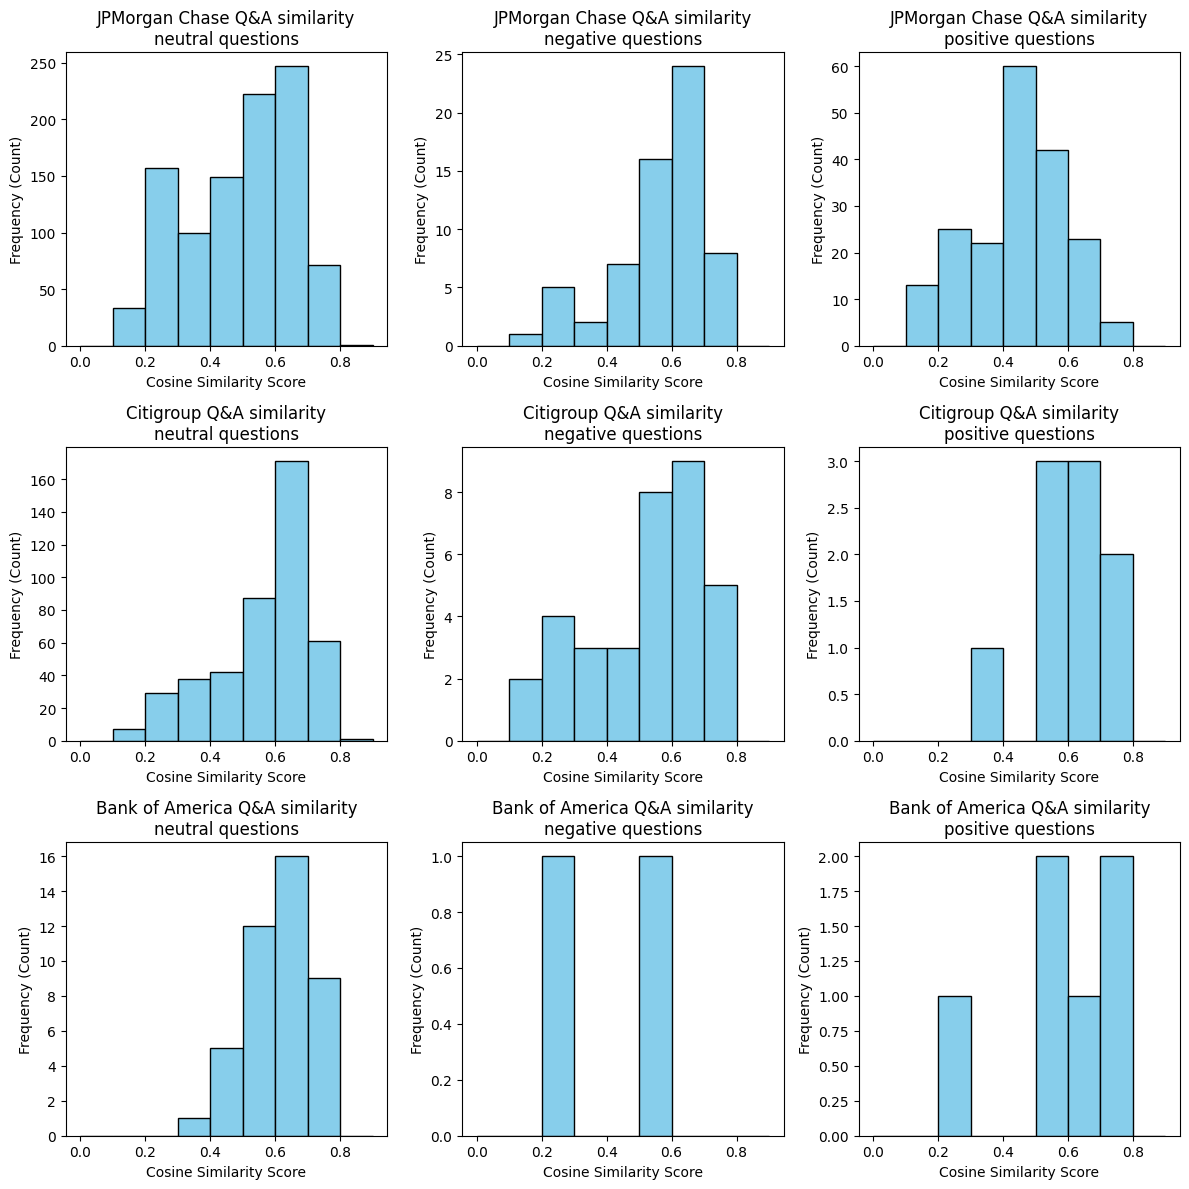

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
bins = np.arange(0.0, 1.0, 0.1)

banks = ['JPMorgan Chase', 'Citigroup', 'Bank of America']
sentiments = ['neutral', 'negative', 'positive']

for r, bnk in enumerate(banks):
    for c, snt in enumerate(sentiments):
        df_plot = df_qa_pairs_full_text[(df_qa_pairs_full_text['bank'] == bnk) & (df_qa_pairs_full_text['question_sentiment'] == snt)]

        axes[r ,c].hist(df_plot['alignment'], bins=bins, color='skyblue', edgecolor='black')

        # Add formatting and labels
        axes[r ,c].set_title(f'{bnk} Q&A similarity\n{snt} questions')
        axes[r ,c].set_xlabel('Cosine Similarity Score')
        axes[r ,c].set_ylabel('Frequency (Count)')

plt.tight_layout()
plt.show()

For JPM and CITI, the frequency distribution of cosine similarity scores show that most of the questions and answers were semantically similar (score > 0.5). Looking only at the questions with negative sentiments, the proportion of high scores improves further. This seems to show that management answers questions more directly and diligently when the question sentiment is negative.

## 6.4 LLM with RAG analysis of Sentiments plus Cosine Similarities

### 6.4.1 Create Vectorized DB with langchain_chromadb

In [ ]:
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_classic.retrievers import SelfQueryRetriever
from langchain_classic.chains.query_constructor.base import AttributeInfo

In [ ]:
import os
from google.colab import userdata

# Ensure your OpenAI API key is fetched and configured in the environment
try:
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception as e:
    print("Warning: Could not automatically retrieve OPENAI_API_KEY from Google Colab Secrets. Please make sure you have added it to your Colab Secrets (the key icon on the left panel).")

chroma_db_path = Path('/content') / 'chroma_db'

# 1. Set up Chroma and the LLM
vectorstore = Chroma(
    collection_name="question_answers",
    embedding_function=OpenAIEmbeddings(),
    persist_directory=str(chroma_db_path)
)
llm = ChatOpenAI(model="gpt-4o", temperature=0)

ids_list = []
texts_list = []
metadata_list = []

documents = []

i = 0
for idx, row in df_qa_pairs_full_text.iterrows():
    i = i + 1
    if i % 100 == 0:
        print(f"Processing row {i}")

    combined_text = (
        f"Question ({row['questioner']}): {row['question']}\n"
        f"Answer ({row['answerer']}): {row['answer']}"
    )

    documents.append(Document(page_content=combined_text,
                              metadata={
                                "qa_pair_id": str(row["qa_pair_id"]),
                                "doc_id": str(row["doc_id"]),
                                "temporal_order": str(row["temporal_order"]),

                                "bank": str(row["bank"]),
                                "event_date": str(row["event_date"]),
                                "fiscal_year": int(row["fiscal_year"]),
                                "fiscal_quarter": str(row["fiscal_quarter"]),

                                "analyst_name": str(row['questioner']),
                                "management_name": str(row['answerer']),
                                "question_sentiment": str(row['question_sentiment']),
                                "answer_sentiment": str(row['answer_sentiment']),
                                "cosine_similarity": float(row["alignment"]),
                              }))

    ids_list.append(str(row['qa_pair_id']))
    texts_list.append(combined_text)
    metadata_list.append({
            "qa_pair_id": str(row["qa_pair_id"]),
            "doc_id": str(row["doc_id"]),
            "temporal_order": str(row["temporal_order"]),

            "bank": str(row["bank"]),
            "event_date": str(row["event_date"]),
            "fiscal_year": int(row["fiscal_year"]),
            "fiscal_quarter": str(row["fiscal_quarter"]),

            "analyst_name": str(row['questioner']),
            "management_name": str(row['answerer']),
            "question_sentiment": str(row['question_sentiment']),
            "answer_sentiment": str(row['answer_sentiment']),
            "cosine_similarity": float(row["alignment"]),
        })

print("IDs list:", len(ids_list))
print("Texts list:", len(texts_list))
print("Metadata list:", len(metadata_list))

vectorstore.add_documents(documents)

# 2. Define your metadata schema so the LLM knows what fields exist
metadata_field_info = [
    AttributeInfo(
        name="bank",
        description="Name of the bank whose earning call transcript contained the question and answer pair",
        type="string",
    ),
    AttributeInfo(
        name="fiscal_quarter",
        description="Financial quarter whose earning call transcript contained the question and answer pair",
        type="string",
    ),
    AttributeInfo(
        name="fiscal_year",
        description="Financial year whose earning call transcript contained the question and answer pair",
        type="string",
    ),
    AttributeInfo(
        name="analyst_name",
        description="Name of the external analyst who asked the question in the question and answer pair",
        type="string",
    ),
    AttributeInfo(
        name="management_name",
        description="Name of the management team member at the bank who provided the answer in the question and answer pair",
        type="string",
    ),
    AttributeInfo(
        name="question_sentiment",
        description="Overall sentiment (either Positive, Negative or Neutral) in the question",
        type="string",
    ),
    AttributeInfo(
        name="answer_sentiment",
        description="Overall sentiment (either Positive, Negative or Neutral) in the answer",
        type="string",
    ),
    AttributeInfo(
        name="cosine_similarity",
        description="A score measuring how similar the texts in the question and answer are. Low values (<0.3) may indicate answer doesn't satisfy the question",
        type="string",
    ),
]
document_content_description = "Internal company policy documents and manuals"


Processing row 100
Processing row 200
Processing row 300
Processing row 400
Processing row 500
Processing row 600
Processing row 700
Processing row 800
Processing row 900
Processing row 1000
Processing row 1100
Processing row 1200
Processing row 1300
Processing row 1400
Processing row 1500
Processing row 1600
Processing row 1700
IDs list: 1764
Texts list: 1764
Metadata list: 1764


In [ ]:
import langchain_community.vectorstores as vs

_orig_getattr = getattr(vs, "__getattr__", None)

def _lenient_getattr(name):
    try:
        if _orig_getattr:
            return _orig_getattr(name)
    except (ImportError, AttributeError):
        pass
    return type(name, (), {})  # placeholder class for any missing vector store

vs.__getattr__ = _lenient_getattr


### 6.4.2 Retrieving insights using LLM

In [ ]:

# 3. Create the self-query retriever
retriever = SelfQueryRetriever.from_llm(
    llm,
    vectorstore,
    document_content_description,
    metadata_field_info,
    verbose=True
)

In [ ]:

# 4. Query the system natively
docs = retriever.invoke("What were the topics that analysts asked questions with negative sentiments in year 2025?")


In [ ]:
docs

[]

Unfortunately  I ran out of time to fine-tune and troubleshoot the LLM with RAG analysis of Q&A similarities any further. Without the analysis from LLM, there were no conclusions for this part.